In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = PROJECT_DIR / 'base_de_dados'

if not DATA_DIR.exists():
    alt_dir = PROJECT_DIR.parent / 'base_de_dados'
    if alt_dir.exists():
        DATA_DIR = alt_dir

# Função auxiliar para criar legenda "fantasma" com média e mediana
def add_legend(ax, data, group_col, value_col, group_colors=None):
    # Média e mediana
    mean_global = data[value_col].mean()
    median_global = data[value_col].median()

    groups = data[group_col].dropna().unique()
    mean_group = data.groupby(group_col)[value_col].mean()
    median_group = data.groupby(group_col)[value_col].median()

    legend_elements = [
        mpatches.Patch(color='white', label=f'Média: {mean_global:.2f}, 50% : {median_global:.2f}'),
    ]

    for g in groups:
        color = group_colors.get(g, 'gray') if group_colors else 'white'
        legend_elements.append(mpatches.Patch(color=color, label=f'{g} → Média: {mean_group[g]:.2f}, 50%: {median_group[g]:.2f}'))

    ax.legend(handles=legend_elements, loc='upper center', fontsize=8)


In [ ]:
# Ler e unir os dados
df_school = pd.concat([
    pd.read_csv(DATA_DIR / 'num_school_data.csv', sep=';'),
    pd.read_csv(DATA_DIR / 'cat_school_data.csv', sep=';')
], ignore_index=True)

# Remover duplicatas e NaN
df_school = df_school.drop_duplicates().dropna()

# Pivotar e selecionar colunas
df_school = df_school.pivot(index='school', columns='variable', values='value')[['type','schgend','schavg']]

# Converter 'schavg' para float direto
df_school['schavg'] = df_school['schavg'].str.replace(',', '.').astype(float)


In [ ]:
df_school

variable,type,schgend,schavg
school,,,
1,Mxd,mixed,0.166175
2,Sngl,girls,0.395149
3,Mxd,mixed,0.514155
4,Mxd,mixed,0.091764
5,Mxd,mixed,0.210525
...,...,...,...
61,Mxd,mixed,-0.020198
62,Mxd,mixed,0.167386
63,Mxd,mixed,0.156211


In [ ]:
# Ler e unir dados
df_student = pd.concat([
    pd.read_csv(DATA_DIR / 'num_student_data.csv', sep=';'),
    pd.read_csv(DATA_DIR / 'cat_student_data.csv', sep=';')
], ignore_index=True).drop_duplicates().dropna()

# Remover alunos com mais de 5 registros duplicados
duplicates = df_student.groupby(['school', 'student']).filter(lambda x: len(x) > 5)
df_student = df_student[~df_student.set_index(['school', 'student']).index.isin(duplicates.set_index(['school', 'student']).index)]

# Pivotar para formato wide
df_student = (
    df_student
    .pivot_table(index=['school','student'], columns='variable', values='value', aggfunc='first')
    .reset_index()
)

df_student = df_student.dropna(subset=['normexam']).reset_index(drop=True)


# parce para float
df_student['normexam'] = df_student['normexam'].str.replace(',', '.').astype(float)
df_student['standLRT'] = df_student['standLRT'].str.replace(',', '.').astype(float)


df_student['schgend'] = df_student.school.map(df_school['schgend'])
df_student['type'] = df_student.school.map(df_school['type'])
df_student['schavg'] = df_student.school.map(df_school['schavg'])


#preenche null sex com base no tipo de escola
df_student['sex'] = df_student['sex'].fillna(df_student['schgend'].map({'girls':'F', 'boys':'M'}))

#preenche null vr com base na escola
df_student['vr'] = df_student['vr'].fillna(df_student.groupby('school')['vr'].transform('first'))

df_student = df_student[['student','school','type','schgend','schavg','sex','intake','vr','standLRT','normexam']]

print(df_student.info())
df_student


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3936 entries, 0 to 3935
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   student   3936 non-null   float64
 1   school    3936 non-null   int64  
 2   type      3936 non-null   object 
 3   schgend   3936 non-null   object 
 4   schavg    3936 non-null   float64
 5   sex       3883 non-null   object 
 6   intake    3871 non-null   object 
 7   vr        3936 non-null   object 
 8   standLRT  3907 non-null   float64
 9   normexam  3936 non-null   float64
dtypes: float64(4), int64(1), object(5)
memory usage: 307.6+ KB
None


variable,student,school,type,schgend,schavg,sex,intake,vr,standLRT,normexam
0,1.0,1,Mxd,mixed,0.166175,F,bottom 25%,mid 50%,0.784362,1.506185
1,4.0,1,Mxd,mixed,0.166175,F,mid 50%,mid 50%,-1.033970,-0.555112
2,6.0,1,Mxd,mixed,0.166175,M,mid 50%,mid 50%,-0.951318,-1.335315
3,7.0,1,Mxd,mixed,0.166175,M,top 25%,mid 50%,-2.356393,-0.555112
4,13.0,1,Mxd,mixed,0.166175,M,mid 50%,mid 50%,-0.290107,-0.197611
...,...,...,...,...,...,...,...,...,...,...
3931,147.0,65,Sngl,girls,-0.235350,F,bottom 25%,mid 50%,1.032317,1.109438
3932,148.0,65,Sngl,girls,-0.235350,F,mid 50%,mid 50%,0.288453,-0.623051
3933,152.0,65,Sngl,girls,-0.235350,F,bottom 25%,mid 50%,-0.207455,0.134067
3934,154.0,65,Sngl,girls,-0.235350,F,mid 50%,mid 50%,-0.124804,0.478194


In [ ]:
df_student.describe()

variable,student,school,schavg,standLRT,normexam
count,3936.00000,3936.000000,3936.000000,3907.000000,3936.000000
mean,134.85315,30.864837,0.002737,0.010756,0.003531
std,174.91286,18.917141,0.316004,0.989489,0.997561
min,1.00000,1.000000,-0.755961,-2.934953,-3.666072
25%,39.00000,14.000000,-0.149341,-0.620713,-0.699505
50%,78.00000,29.000000,-0.016624,0.040499,0.004322
75%,138.00000,47.000000,0.267385,0.619059,0.678759
max,913.00000,65.000000,0.637656,3.015952,3.666091


In [ ]:
quantidade_alunos_escola = df_student['schgend'].value_counts()
print(f'{quantidade_alunos_escola=}')

proporcao_quantidade_alunos_escola = df_student['schgend'].value_counts(normalize=True)
print(f'{proporcao_quantidade_alunos_escola=}')

quantidade_escola = df_school['schgend'].value_counts()
print(f'{quantidade_escola=}')

proporcao_quantidade_escola = df_school['schgend'].value_counts(normalize=True)
print(f'{proporcao_quantidade_escola=}')

quantidade_alunos_escola_mis= df_student[df_student['schgend']=='mixed']['sex'].value_counts()
quantidade_alunos_escola_mis

quantidade_alunos_escola=schgend
mixed    2096
girls    1339
boys      501
Name: count, dtype: int64
proporcao_quantidade_alunos_escola=schgend
mixed    0.532520
girls    0.340193
boys     0.127287
Name: proportion, dtype: float64
quantidade_escola=schgend
mixed    35
girls    20
boys     10
Name: count, dtype: int64
proporcao_quantidade_escola=schgend
mixed    0.538462
girls    0.307692
boys     0.153846
Name: proportion, dtype: float64


,count
sex,
M,1045
F,998


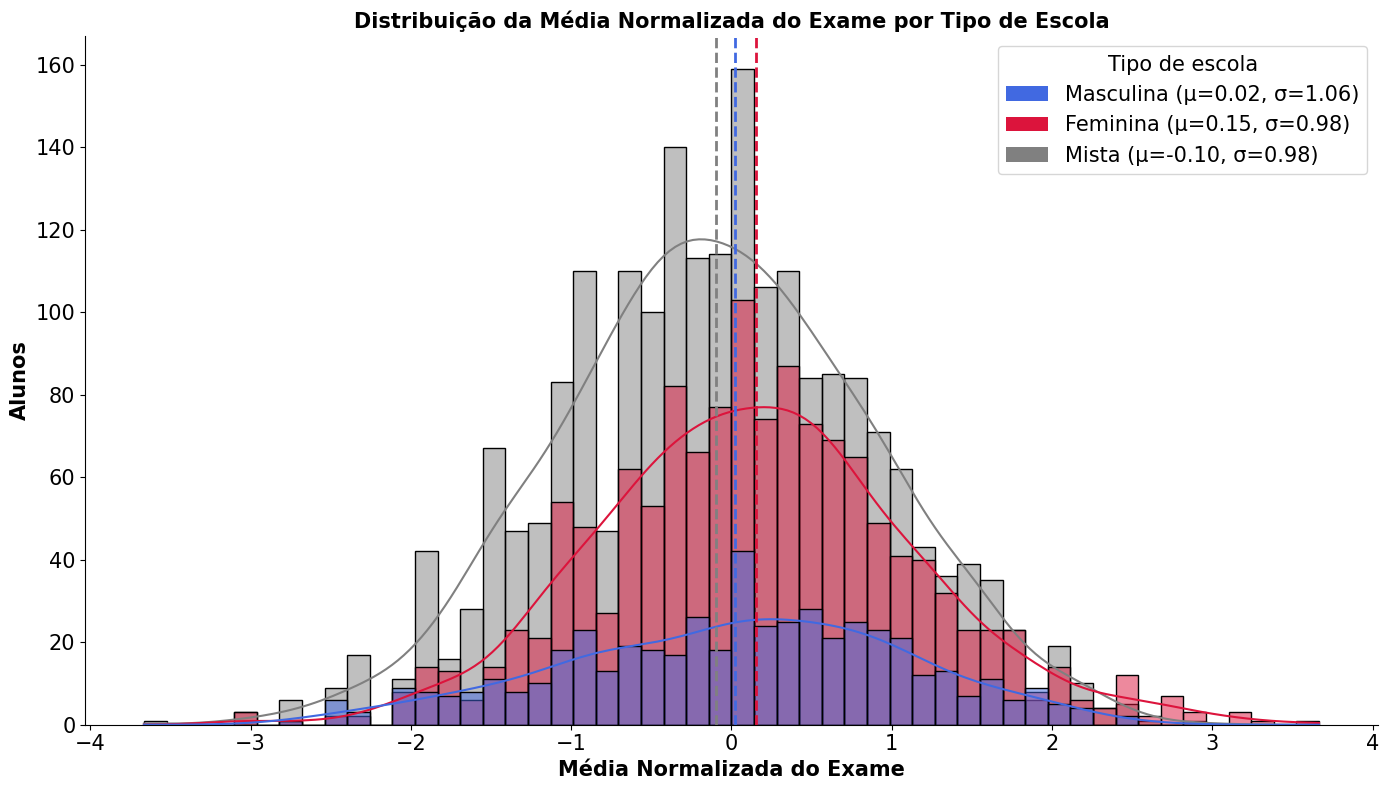

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Paleta de cores e rótulos
cores = {'mixed': 'gray', 'girls': 'crimson', 'boys': 'royalblue'}
rotulos = {'mixed': 'Mista', 'girls': 'Feminina', 'boys': 'Masculina'}

plt.figure(figsize=(14,8))

# Plot principal
sns.histplot(
    data=df_student,
    x='normexam',
    hue='schgend',
    hue_order=['boys', 'girls', 'mixed'],
    bins=52,
    palette=cores,
    kde=True,
    alpha=0.5,
    edgecolor='black'
)

# Calcular e desenhar as médias + desvio padrão
handles = []
for tipo, grupo in df_student.groupby('schgend'):
    media = grupo['normexam'].mean()
    desvio = grupo['normexam'].std()
    plt.axvline(media, color=cores[tipo], linestyle='--', linewidth=2)
    label = f"{rotulos[tipo]} (μ={media:.2f}, σ={desvio:.2f})"
    handles.append(Patch(facecolor=cores[tipo], label=label))

# Criar legenda manualmente
plt.legend(
    handles=handles,
    title='Tipo de escola',
    fontsize=15,
    title_fontsize=15
)

# Estilo geral
plt.xlabel('Média Normalizada do Exame', fontsize=15, fontweight='bold')
plt.ylabel('Alunos', fontsize=15, fontweight='bold')
plt.title('Distribuição da Média Normalizada do Exame por Tipo de Escola', fontsize=15, fontweight='bold')
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
sns.despine()
plt.tight_layout()
plt.show()


/tmp/ipython-input-4129646120.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.boxplot(


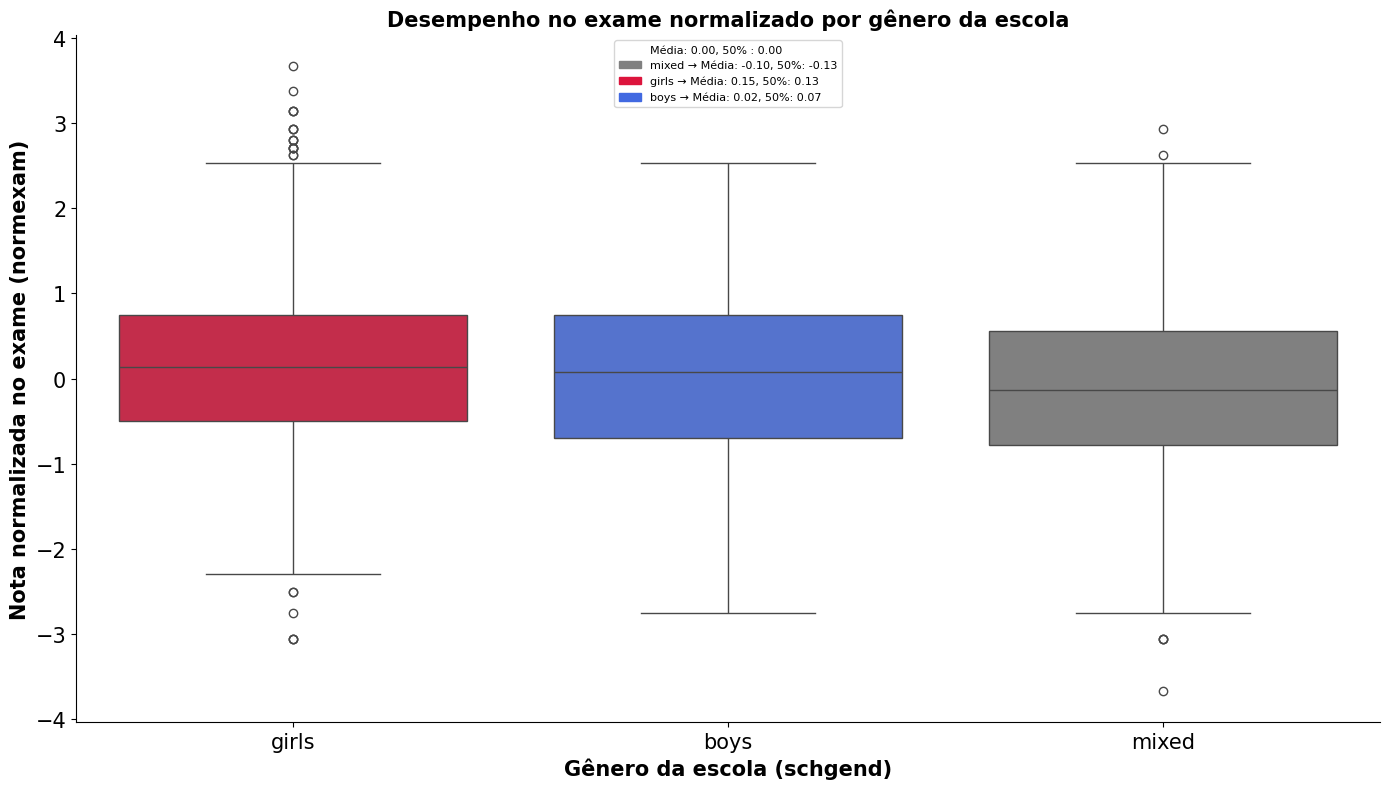

In [ ]:
plt.figure(figsize=(14,8))

ax2 = sns.boxplot(
    data=df_student,
    x='schgend',
    y='normexam',
    order=['girls', 'boys', 'mixed'],
    palette=cores
)

plt.title('Desempenho no exame normalizado por gênero da escola', fontsize=15, fontweight='bold')
plt.xlabel('Gênero da escola (schgend)', fontsize=15, fontweight='bold')
plt.ylabel('Nota normalizada no exame (normexam)', fontsize=15, fontweight='bold')

# Ajustar tamanho dos ticks
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

# Chamar função de legenda
add_legend(ax2, df_student, 'schgend', 'normexam', cores)

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats
import pandas as pd
import itertools

# Variáveis numéricas que queremos comparar
variaveis = ['normexam', 'standLRT']

# Dicionários para nomes e rótulos bonitos
rotulos = {'mixed': 'Mista', 'girls': 'Feminina', 'boys': 'Masculina'}

print("=" * 60)
print("RESULTADOS DOS TESTES T ENTRE TIPOS DE ESCOLA")
print("=" * 60)

# Loop para cada variável numérica
for var in variaveis:
    print(f"\n🔹 VARIÁVEL: {var}")
    print("-" * 60)

    # Todas as combinações de pares possíveis (ex: girls × boys)
    grupos = df_student['schgend'].dropna().unique()
    pares = list(itertools.combinations(grupos, 2))

    # Comparar cada par de escolas
    for g1, g2 in pares:
        d1 = df_student[df_student['schgend'] == g1][var].dropna()
        d2 = df_student[df_student['schgend'] == g2][var].dropna()

        # Teste t
        t_stat, p_val = stats.ttest_ind(d1, d2, equal_var=False)

        # Diferença de médias
        diff = d1.mean() - d2.mean()

        # Impressão formatada
        print(f"\n{rotulos[g1]} × {rotulos[g2]}")
        print(f"  {rotulos[g1]} (n={len(d1)}): Média = {d1.mean()}")
        print(f"  {rotulos[g2]} (n={len(d2)}): Média = {d2.mean()}")
        print(f"  Diferença ({rotulos[g1]} - {rotulos[g2]}): {diff}")
        print(f"  Estatística t: {t_stat}")
        print(f"  Valor p: {p_val}")
        print(f"  Significativo (p < 0.05): {'SIM' if p_val < 0.05 else 'NÃO'}")

    print("\n" + "=" * 60)

# Interpretação geral
print("INTERPRETAÇÃO GERAL:")
print("=" * 60)
print("Se p < 0.05, há diferença significativa entre os grupos comparados.")
print("Diferença positiva indica que o primeiro grupo teve média maior.")


RESULTADOS DOS TESTES T ENTRE TIPOS DE ESCOLA

🔹 VARIÁVEL: normexam
------------------------------------------------------------

Mista × Feminina
  Mista (n=2096): Média = -0.09659705505725193
  Feminina (n=1339): Média = 0.15382951501120237
  Diferença (Mista - Feminina): -0.2504265700684543
  Estatística t: -7.286814996371677
  Valor p: 4.091821321019146e-13
  Significativo (p < 0.05): SIM

Mista × Masculina
  Mista (n=2096): Média = -0.09659705505725193
  Masculina (n=501): Média = 0.020736809580838293
  Diferença (Mista - Masculina): -0.11733386463809022
  Estatística t: -2.265399552141411
  Valor p: 0.02378446193845804
  Significativo (p < 0.05): SIM

Feminina × Masculina
  Feminina (n=1339): Média = 0.15382951501120237
  Masculina (n=501): Média = 0.020736809580838293
  Diferença (Feminina - Masculina): 0.13309270543036408
  Estatística t: 2.451580011188387
  Valor p: 0.014424655223124649
  Significativo (p < 0.05): SIM


🔹 VARIÁVEL: standLRT
------------------------------------

/tmp/ipython-input-1894087906.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipython-input-1894087906.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


girls: 0.014215028080657199
boys: 0.0023015297405189765
mixed: -0.004491442366412201


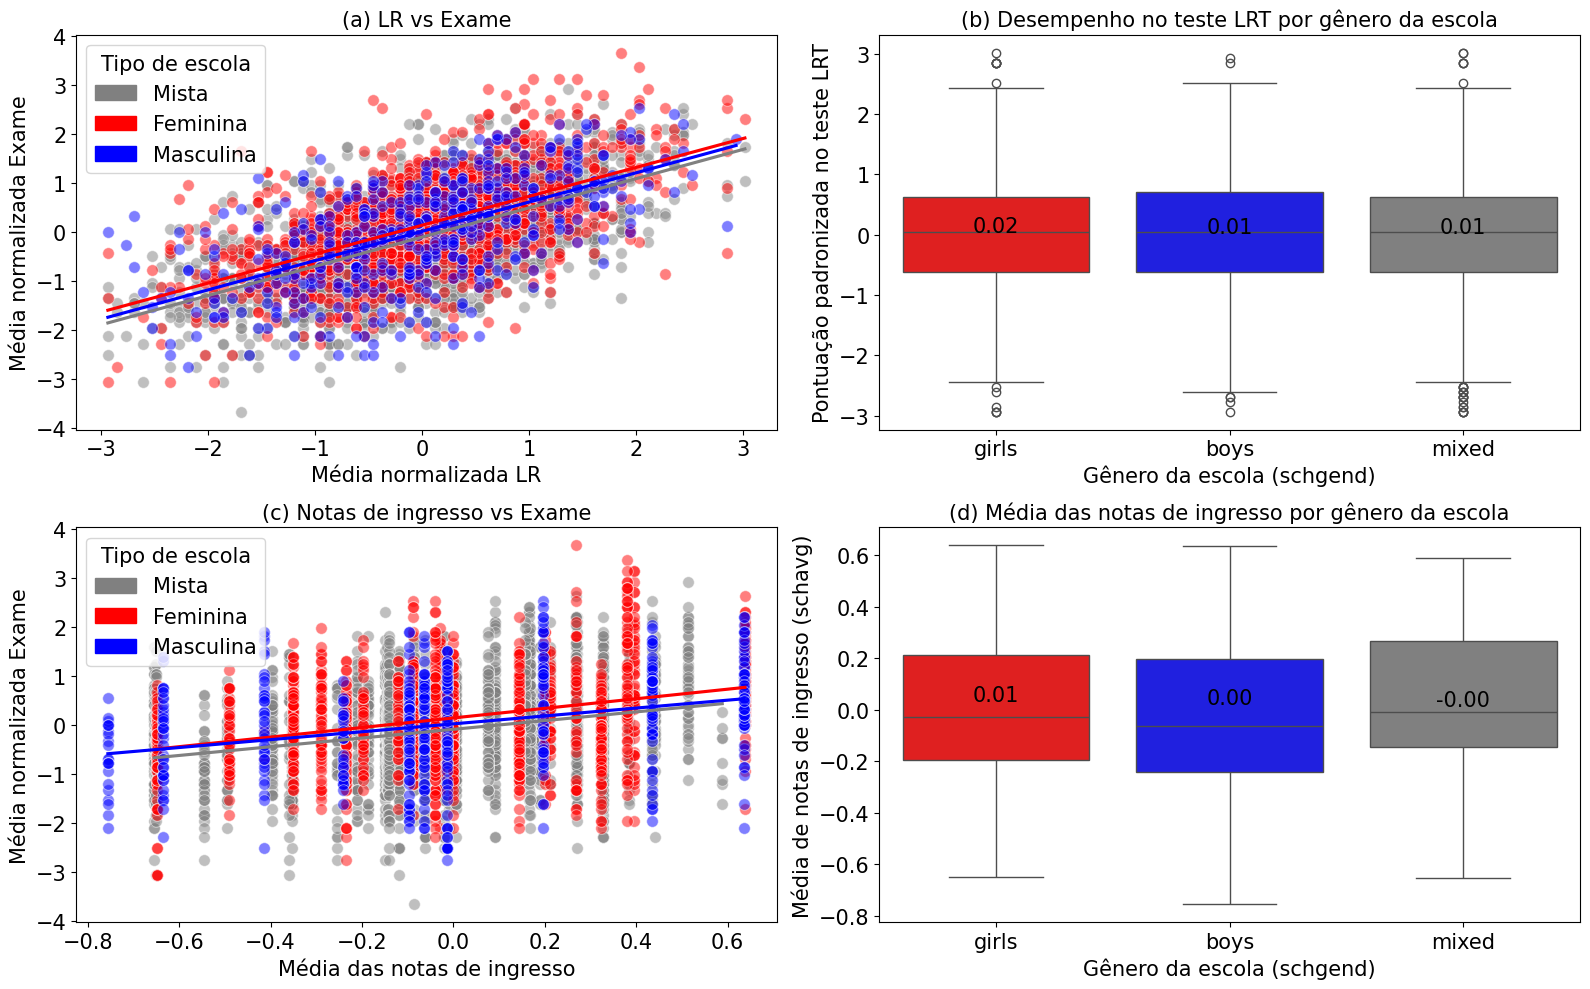

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import numpy as np

plt.figure(figsize=(16,10))

# Grupos e cores
groups = ['mixed', 'girls', 'boys']
colors = ['gray', 'red', 'blue']
labels = ['Mista', 'Feminina', 'Masculina']

# --- Gráfico 1: LR vs Exame ---
ax1 = plt.subplot(2, 2, 1)
for g, color, label in zip(groups, colors, labels):
    subset = df_student[df_student['schgend'] == g]
    sns.scatterplot(
        data=subset,
        x='standLRT',
        y='normexam',
        color=color,
        s=70,
        alpha=0.5
    )
    sns.regplot(
        data=subset,
        x='standLRT',
        y='normexam',
        scatter=False,
        color=color,
        ci=None
    )
ax1.set_xlabel('Média normalizada LR', fontsize=15)
ax1.set_ylabel('Média normalizada Exame', fontsize=15)
ax1.set_title('(a) LR vs Exame', fontsize=15)
ax1.tick_params(axis='both', labelsize=15)

# Legenda scatter
handles_scatter = [Patch(color=c, label=l) for c, l in zip(colors, labels)]
ax1.legend(handles=handles_scatter, title='Tipo de escola', fontsize=15, title_fontsize=15)

# --- Gráfico 2: Desempenho LRT por gênero (boxplot) ---
ax2 = plt.subplot(2, 2, 2)
sns.boxplot(
    data=df_student,
    x='schgend',
    y='standLRT',
    order=['girls','boys','mixed'],
    palette=dict(zip(groups, colors)),
    ax=ax2
)
# Adicionar médias
for i, g in enumerate(['girls','boys','mixed']):
    mean_val = df_student[df_student['schgend']==g]['standLRT'].mean()
    ax2.text(i, mean_val + 0.02, f'{mean_val:.2f}', ha='center', fontsize=15, color='black')

ax2.set_title('(b) Desempenho no teste LRT por gênero da escola', fontsize=15)
ax2.set_xlabel('Gênero da escola (schgend)', fontsize=15)
ax2.set_ylabel('Pontuação padronizada no teste LRT', fontsize=15)
ax2.tick_params(axis='both', labelsize=15)

# --- Gráfico 3: Notas de ingresso vs Exame ---
ax3 = plt.subplot(2, 2, 3)
for g, color, label in zip(groups, colors, labels):
    subset = df_student[df_student['schgend'] == g]
    sns.scatterplot(
        data=subset,
        x='schavg',
        y='normexam',
        color=color,
        s=70,
        alpha=0.5
    )
    sns.regplot(
        data=subset,
        x='schavg',
        y='normexam',
        scatter=False,
        color=color,
        ci=None
    )
ax3.set_xlabel('Média das notas de ingresso', fontsize=15)
ax3.set_ylabel('Média normalizada Exame', fontsize=15)
ax3.set_title('(c) Notas de ingresso vs Exame', fontsize=15)
ax3.tick_params(axis='both', labelsize=15)
ax3.legend(handles=handles_scatter, title='Tipo de escola', fontsize=15, title_fontsize=15)

# --- Gráfico 4: Média das notas de ingresso por gênero (boxplot) ---
ax4 = plt.subplot(2, 2, 4)
sns.boxplot(
    data=df_student,
    x='schgend',
    y='schavg',
    order=['girls','boys','mixed'],
    palette=dict(zip(groups, colors)),
    ax=ax4
)
# Adicionar médias
for i, g in enumerate(['girls','boys','mixed']):
    mean_val = df_student[df_student['schgend']==g]['schavg'].mean()
    print(f'{g}: {mean_val}')
    ax4.text(i, mean_val + 0.02, f'{mean_val:.2f}', ha='center', fontsize=15, color='black')

ax4.set_title('(d) Média das notas de ingresso por gênero da escola', fontsize=15)
ax4.set_xlabel('Gênero da escola (schgend)', fontsize=15)
ax4.set_ylabel('Média de notas de ingresso (schavg)', fontsize=15)
ax4.tick_params(axis='both', labelsize=15)


plt.tight_layout()
plt.show()


/tmp/ipython-input-1423983590.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipython-input-1423983590.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


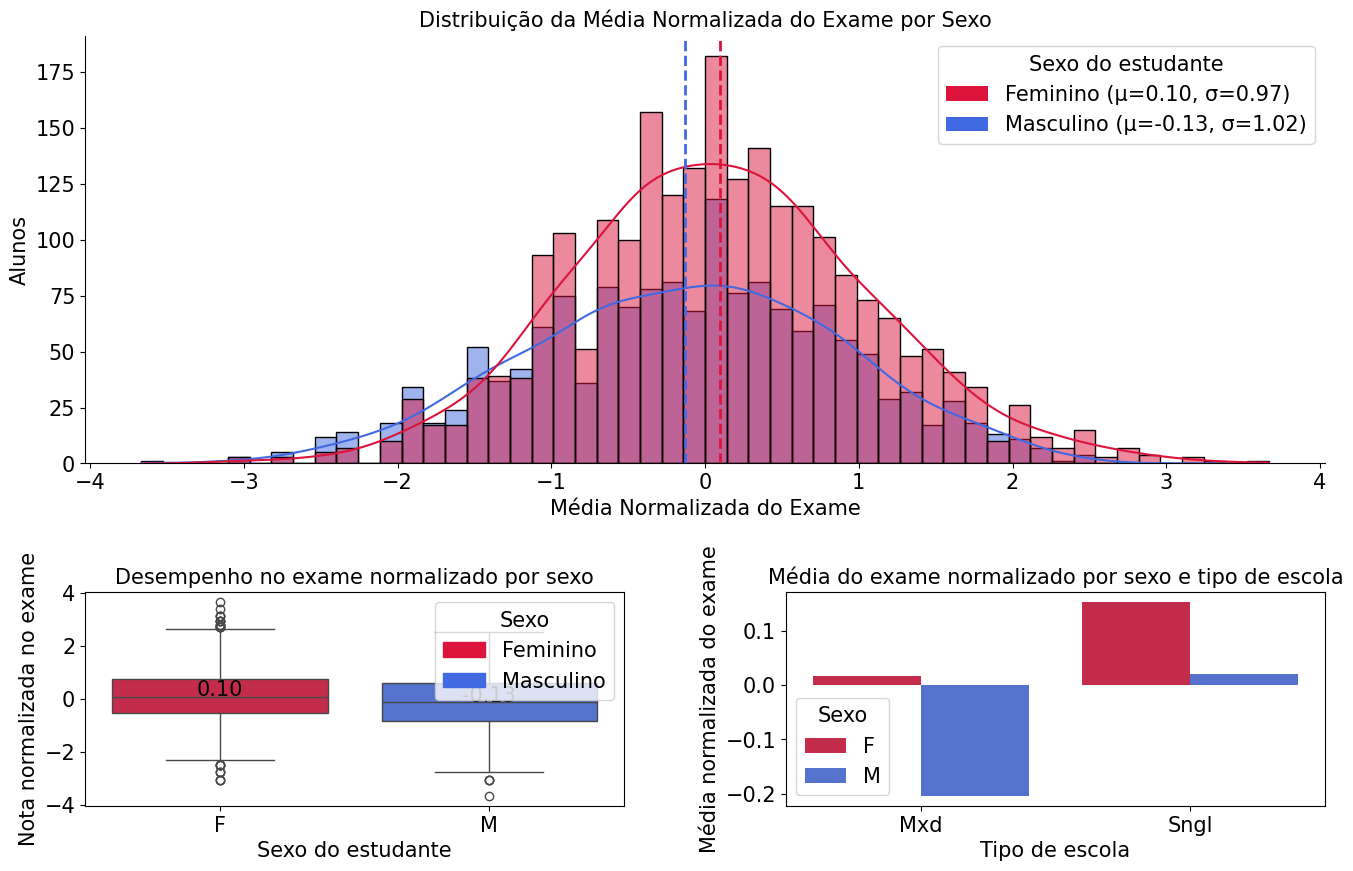

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec

# Paleta de cores consistente
cores_sex = {'F': 'crimson', 'M': 'royalblue'}
rotulos_sex = {'F': 'Feminino', 'M': 'Masculino'}

# Calcular médias por tipo e sexo
media_por_tipo_sexo = df_student.groupby(['type', 'sex'])[['normexam', 'standLRT','schavg']].mean().reset_index()

# Criar figura com GridSpec
fig = plt.figure(figsize=(16,10))
gs = GridSpec(2, 2, height_ratios=[2, 1], hspace=0.4, wspace=0.3)

# ---------------------------
# Gráfico 1: Histograma (topo) - ocupa toda a linha
# ---------------------------
ax_hist = fig.add_subplot(gs[0, :])
sns.histplot(
    data=df_student,
    x='normexam',
    hue='sex',
    bins=52,
    palette=cores_sex,
    kde=True,
    alpha=0.5,
    edgecolor='black',
    ax=ax_hist
)

# Linhas de média
handles = []
for sexo, grupo in df_student.groupby('sex'):
    media = grupo['normexam'].mean()
    desvio = grupo['normexam'].std()
    ax_hist.axvline(media, color=cores_sex[sexo], linestyle='--', linewidth=2)
    label = f"{rotulos_sex[sexo]} (μ={media:.2f}, σ={desvio:.2f})"
    handles.append(Patch(facecolor=cores_sex[sexo], label=label))

ax_hist.legend(handles=handles, title='Sexo do estudante', fontsize=15, title_fontsize=15)
ax_hist.set_xlabel('Média Normalizada do Exame', fontsize=15)
ax_hist.set_ylabel('Alunos', fontsize=15)
ax_hist.set_title('Distribuição da Média Normalizada do Exame por Sexo', fontsize=15)
ax_hist.tick_params(axis='both', labelsize=15)
sns.despine(ax=ax_hist)

# ---------------------------
# Gráfico 2: Boxplot (embaixo à esquerda)
# ---------------------------
ax_box = fig.add_subplot(gs[1,0])
sns.boxplot(
    data=df_student,
    x='sex',
    y='normexam',
    palette=cores_sex,
    ax=ax_box
)
# Adicionar médias acima das caixas
for i, sexo in enumerate(['F','M']):
    mean_val = df_student[df_student['sex']==sexo]['normexam'].mean()
    ax_box.text(i, mean_val + 0.02, f'{mean_val:.2f}', ha='center', fontsize=15, color='black')

ax_box.set_title('Desempenho no exame normalizado por sexo', fontsize=15)
ax_box.set_xlabel('Sexo do estudante', fontsize=15)
ax_box.set_ylabel('Nota normalizada no exame', fontsize=15)
ax_box.tick_params(axis='both', labelsize=15)

handles_box = [Patch(color=cores_sex[s], label=rotulos_sex[s]) for s in ['F','M']]
ax_box.legend(handles=handles_box, title='Sexo', fontsize=15, title_fontsize=15)

# ---------------------------
# Gráfico 3: Barplot média do exame por tipo e sexo (embaixo à direita)
# ---------------------------
ax_bar = fig.add_subplot(gs[1,1])
sns.barplot(
    data=media_por_tipo_sexo,
    x='type',
    y='normexam',
    hue='sex',
    palette=['crimson','royalblue'],
    ax=ax_bar
)
# Adicionar médias sobre as barras


ax_bar.set_xlabel('Tipo de escola', fontsize=15)
ax_bar.set_ylabel('Média normalizada do exame', fontsize=15)
ax_bar.set_title('Média do exame normalizado por sexo e tipo de escola', fontsize=15)
ax_bar.tick_params(axis='both', labelsize=15)
ax_bar.legend(title='Sexo', fontsize=15, title_fontsize=15)

plt.tight_layout()
plt.show()


/tmp/ipython-input-2583721771.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipython-input-2583721771.py:19: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipython-input-2583721771.py:29: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




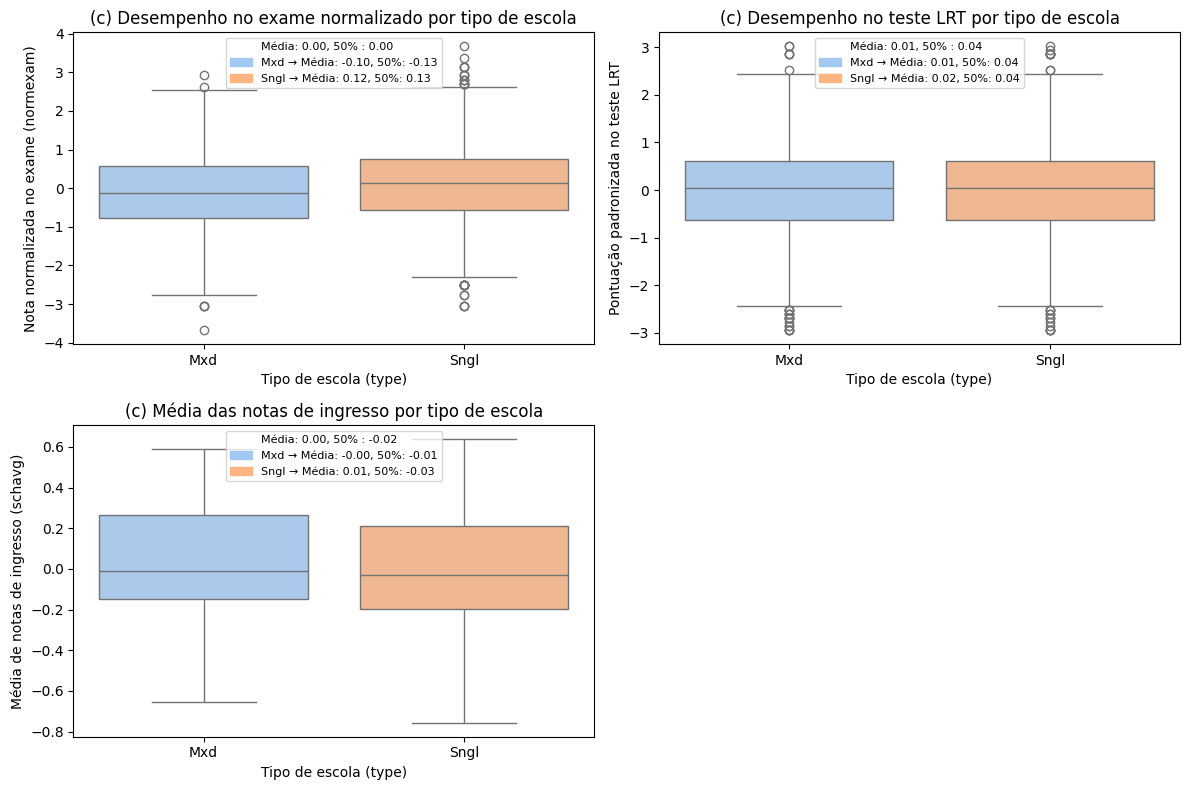

In [ ]:
# --- Figura maior e grade organizada ---
plt.figure(figsize=(12, 8))

# --- (3) Desempenho por tipo de escola ---
plt.subplot(2, 2, 1)
school_types = df_student['type'].dropna().unique()
palette_type = {t: color for t, color in zip(school_types, sns.color_palette('pastel', len(school_types)))}
ax3 = sns.boxplot(data=df_student, x='type', y='normexam', palette=palette_type)
plt.title('(c) Desempenho no exame normalizado por tipo de escola')
plt.xlabel('Tipo de escola (type)')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax3, df_student, 'type', 'normexam', palette_type)


# --- (3) Desempenho no teste LRT por tipo de escola ---
plt.subplot(2, 2, 2)
school_types = df_student['type'].dropna().unique()
palette_type = {t: color for t, color in zip(school_types, sns.color_palette('pastel', len(school_types)))}
ax3 = sns.boxplot(data=df_student, x='type', y='standLRT', palette=palette_type)
plt.title('(c) Desempenho no teste LRT por tipo de escola')
plt.xlabel('Tipo de escola (type)')
plt.ylabel('Pontuação padronizada no teste LRT')
add_legend(ax3, df_student, 'type', 'standLRT', palette_type)

# --- (3) Média das notas de ingresso por tipo de escola ---
plt.subplot(2, 2, 3)
school_types = df_student['type'].dropna().unique()
palette_type = {t: color for t, color in zip(school_types, sns.color_palette('pastel', len(school_types)))}
ax3 = sns.boxplot(data=df_student, x='type', y='schavg', palette=palette_type)
plt.title('(c) Média das notas de ingresso por tipo de escola')
plt.xlabel('Tipo de escola (type)')
plt.ylabel('Média de notas de ingresso (schavg)')
add_legend(ax3, df_student, 'type', 'schavg', palette_type)



In [ ]:
group_colors_schgend = {'girls': 'pink', 'boys': 'lightblue', 'mixed': 'lightgreen'}
ax2 = sns.boxplot(data=df_student, x='schgend', y='normexam', order=['girls','boys','mixed'], palette=group_colors_schgend)
plt.title('(b) Desempenho no exame normalizado por gênero da escola')
plt.xlabel('Gênero da escola (schgend)')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax2, df_student, 'schgend', 'normexam', group_colors_schgend)

/tmp/ipython-input-3912599709.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipython-input-3912599709.py:14: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipython-input-3912599709.py:22: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




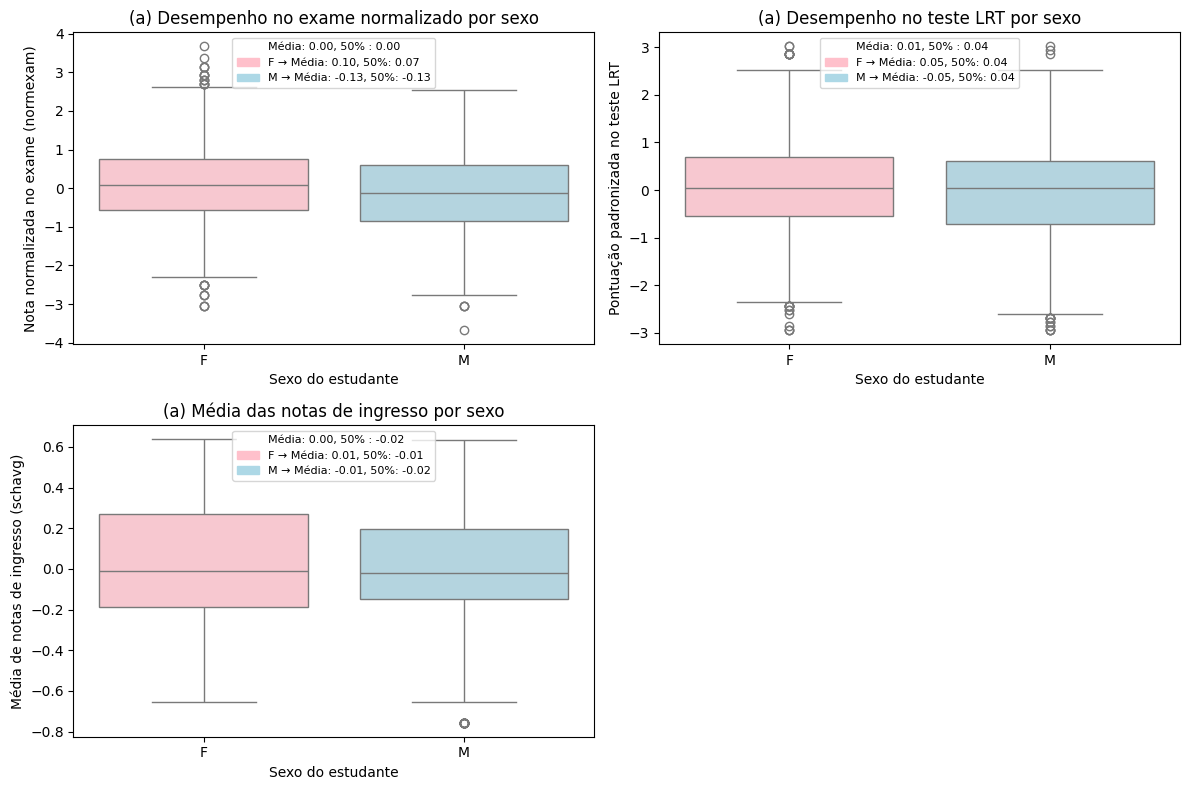

In [ ]:
# --- Figura maior e grade organizada ---
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
group_colors_sex = {'F': 'pink', 'M': 'lightblue'}
ax1 = sns.boxplot(data=df_student, x='sex', y='normexam', palette=group_colors_sex)
plt.title('(a) Desempenho no exame normalizado por sexo')
plt.xlabel('Sexo do estudante')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax1, df_student, 'sex', 'normexam', group_colors_sex)

plt.subplot(2, 2, 2)
group_colors_sex = {'F': 'pink', 'M': 'lightblue'}
ax1 = sns.boxplot(data=df_student, x='sex', y='standLRT', palette=group_colors_sex)
plt.title('(a) Desempenho no teste LRT por sexo')
plt.xlabel('Sexo do estudante')
plt.ylabel('Pontuação padronizada no teste LRT')
add_legend(ax1, df_student, 'sex', 'standLRT', group_colors_sex)

plt.subplot(2, 2, 3)
group_colors_sex = {'F': 'pink', 'M': 'lightblue'}
ax1 = sns.boxplot(data=df_student, x='sex', y='schavg', palette=group_colors_sex)
plt.title('(a) Média das notas de ingresso por sexo')
plt.xlabel('Sexo do estudante')
plt.ylabel('Média de notas de ingresso (schavg)')
add_legend(ax1, df_student, 'sex', 'schavg', group_colors_sex)

# Ajuste de layout
plt.tight_layout()
plt.show()


type
Mxd     0.53252
Sngl    0.46748
Name: proportion, dtype: float64
type
Mxd     0.538462
Sngl    0.461538
Name: proportion, dtype: float64
sex
F    0.601854
M    0.398146
Name: proportion, dtype: float64
sex
M    0.511503
F    0.488497
Name: proportion, dtype: float64


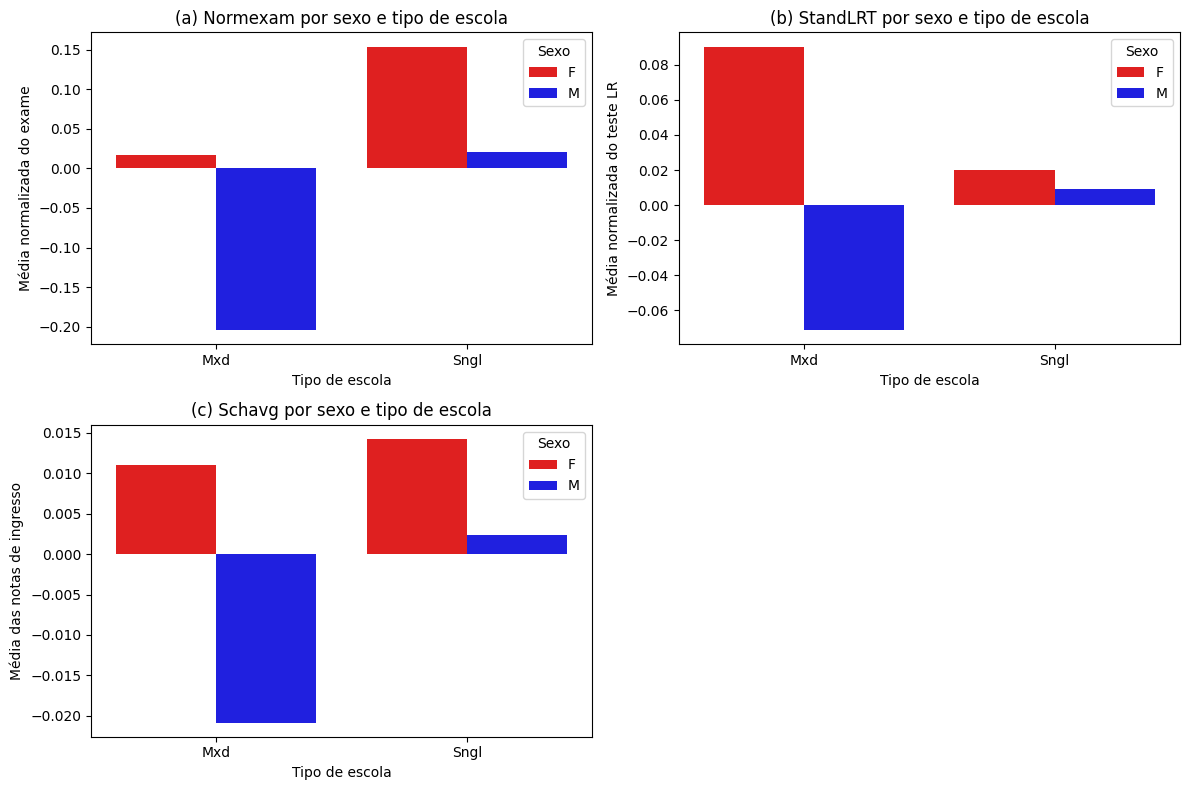

In [ ]:
# Filtra apenas escolas do tipo Mxd
df_mxd = df_student[df_student['type'] == 'Mxd']

# Calcula a proporção de cada sexo dentro de Mxd
proporcao_sexo_mxd = df_mxd['sex'].value_counts(normalize=True)
print(proporcao_sexo_mxd)

# --- Preparar os dados ---
# Calcula a média de desempenho por tipo de escola e sexo
media_por_tipo_sexo = df_student.groupby(['type', 'sex'])[['normexam', 'standLRT','schavg']].mean().reset_index()

# --- Criar subplots 2x2 ---
plt.figure(figsize=(12, 8))

# --- Gráfico 1: Média do exame ---
plt.subplot(2,2,1)
sns.barplot(
    data=media_por_tipo_sexo,
    x='type',
    y='normexam',
    hue='sex',
    palette=['red', 'blue']
)
plt.xlabel('Tipo de escola')
plt.ylabel('Média normalizada do exame')
plt.title('(a) Normexam por sexo e tipo de escola')
plt.legend(title='Sexo')

# --- Gráfico 2: Média do teste LR ---
plt.subplot(2,2,2)
sns.barplot(
    data=media_por_tipo_sexo,
    x='type',
    y='standLRT',
    hue='sex',
    palette=['red', 'blue']
)
plt.xlabel('Tipo de escola')
plt.ylabel('Média normalizada do teste LR')
plt.title('(b) StandLRT por sexo e tipo de escola')
plt.legend(title='Sexo')

# --- Gráfico 3: Média das notas de ingresso ---
plt.subplot(2,2,3)
sns.barplot(
    data=media_por_tipo_sexo,
    x='type',
    y='schavg',
    hue='sex',
    palette=['red', 'blue']
)
plt.xlabel('Tipo de escola')
plt.ylabel('Média das notas de ingresso')
plt.title('(c) Schavg por sexo e tipo de escola')
plt.legend(title='Sexo')

plt.tight_layout()
plt.show()



/tmp/ipython-input-3140316933.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.boxplot(data=df_student, x='sex', y='normexam', palette=group_colors_sex)
/tmp/ipython-input-3140316933.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.boxplot(data=df_student, x='schgend', y='normexam', order=['girls','boys','mixed'], palette=group_colors_schgend)
/tmp/ipython-input-3140316933.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.boxplot(data=df_student, x='type', y='normexam', palette=palette_type)
/tmp/ipython-input-3140316933.py:36: FutureWar

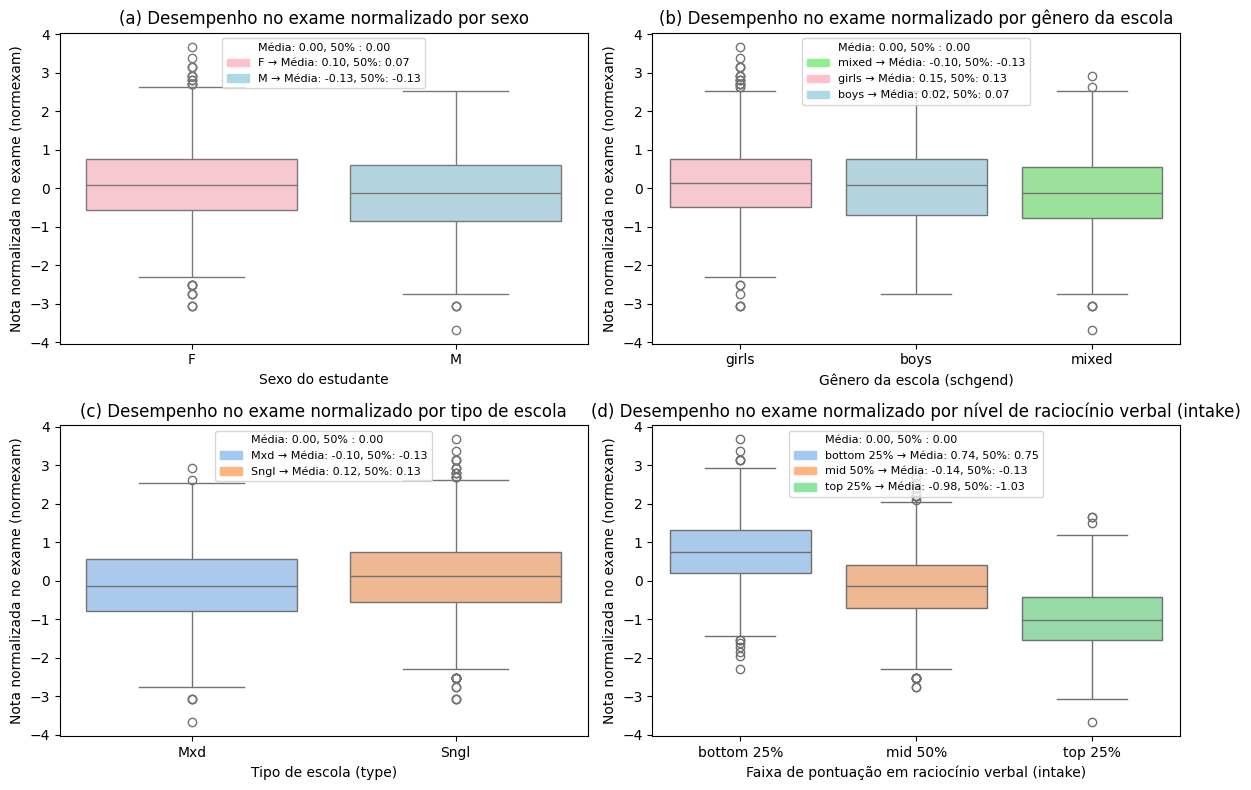

In [ ]:
# --- Figura maior e grade organizada ---
plt.figure(figsize=(12, 8))

# --- (1) Desempenho por sexo ---
plt.subplot(2, 2, 1)
group_colors_sex = {'F': 'pink', 'M': 'lightblue'}
ax1 = sns.boxplot(data=df_student, x='sex', y='normexam', palette=group_colors_sex)
plt.title('(a) Desempenho no exame normalizado por sexo')
plt.xlabel('Sexo do estudante')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax1, df_student, 'sex', 'normexam', group_colors_sex)

# --- (2) Desempenho por gênero da escola ---
plt.subplot(2, 2, 2)
group_colors_schgend = {'girls': 'pink', 'boys': 'lightblue', 'mixed': 'lightgreen'}
ax2 = sns.boxplot(data=df_student, x='schgend', y='normexam', order=['girls','boys','mixed'], palette=group_colors_schgend)
plt.title('(b) Desempenho no exame normalizado por gênero da escola')
plt.xlabel('Gênero da escola (schgend)')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax2, df_student, 'schgend', 'normexam', group_colors_schgend)

# --- (3) Desempenho por tipo de escola ---
plt.subplot(2, 2, 3)
school_types = df_student['type'].dropna().unique()
palette_type = {t: color for t, color in zip(school_types, sns.color_palette('pastel', len(school_types)))}
ax3 = sns.boxplot(data=df_student, x='type', y='normexam', palette=palette_type)
plt.title('(c) Desempenho no exame normalizado por tipo de escola')
plt.xlabel('Tipo de escola (type)')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax3, df_student, 'type', 'normexam', palette_type)

# --- (4) Desempenho por nível de VR ---
plt.subplot(2, 2, 4)
vr_levels = ['bottom 25%', 'mid 50%', 'top 25%']
palette_vr = {level: color for level, color in zip(vr_levels, sns.color_palette('pastel', len(vr_levels)))}
ax4 = sns.boxplot(data=df_student, x='vr', y='normexam', order=vr_levels, palette=palette_vr)
plt.title('(d) Desempenho no exame normalizado por nível de raciocínio verbal (VR)')
plt.xlabel('Faixa de pontuação em raciocínio verbal (vr)')
plt.ylabel('Nota normalizada no exame (normexam)')
add_legend(ax4, df_student, 'vr', 'normexam', palette_vr)

# Ajuste de layout
plt.tight_layout()
plt.show()


/tmp/ipython-input-2621001891.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.boxplot(data=df_student, x='sex', y='standLRT', palette=group_colors_sex)
/tmp/ipython-input-2621001891.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.boxplot(data=df_student, x='schgend', y='standLRT', order=['girls','boys','mixed'], palette=group_colors_schgend)
/tmp/ipython-input-2621001891.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.boxplot(data=df_student, x='type', y='standLRT', palette=palette_type)
/tmp/ipython-input-2621001891.py:35: FutureWar

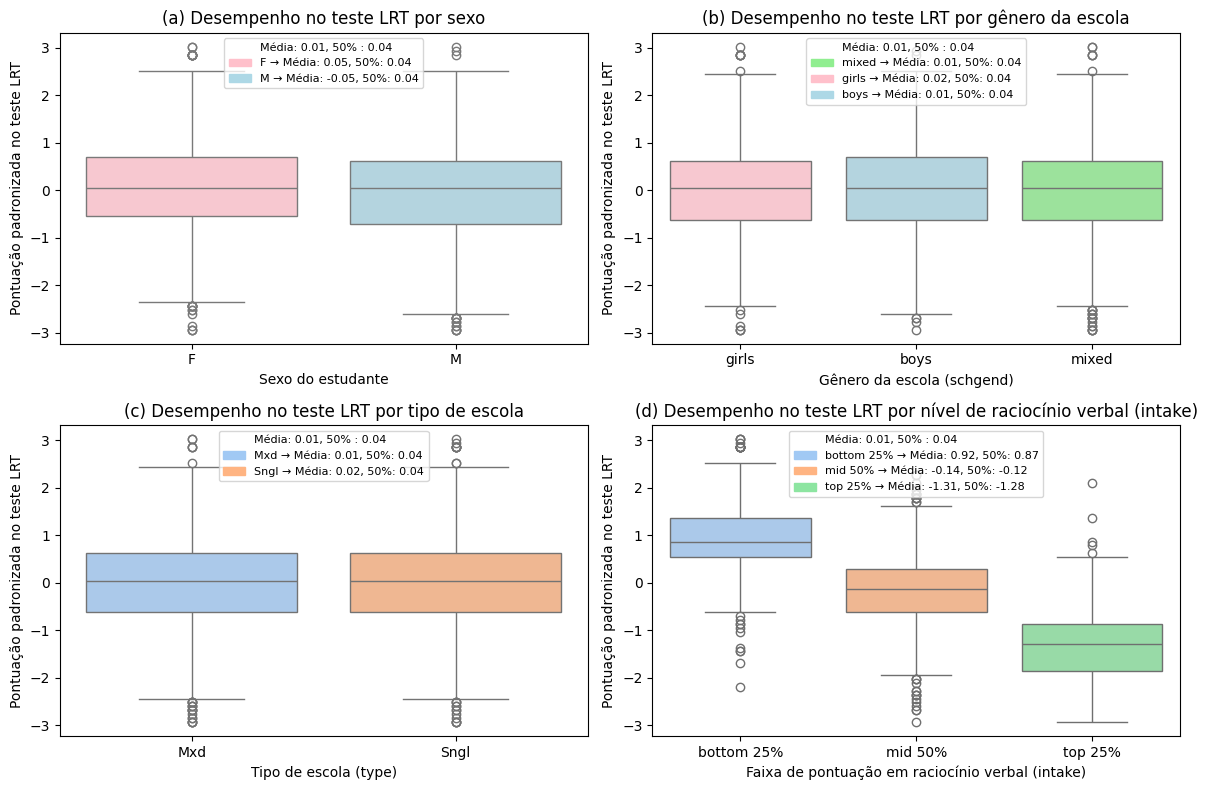

In [ ]:
plt.figure(figsize=(12, 8))

# --- (1) Desempenho no teste LRT por sexo ---
plt.subplot(2, 2, 1)
group_colors_sex = {'F': 'pink', 'M': 'lightblue'}
ax1 = sns.boxplot(data=df_student, x='sex', y='standLRT', palette=group_colors_sex)
plt.title('(a) Desempenho no teste LRT por sexo')
plt.xlabel('Sexo do estudante')
plt.ylabel('Pontuação padronizada no teste LRT')
add_legend(ax1, df_student, 'sex', 'standLRT', group_colors_sex)

# --- (2) Desempenho no teste LRT por gênero da escola ---
plt.subplot(2, 2, 2)
group_colors_schgend = {'girls': 'pink', 'boys': 'lightblue', 'mixed': 'lightgreen'}
ax2 = sns.boxplot(data=df_student, x='schgend', y='standLRT', order=['girls','boys','mixed'], palette=group_colors_schgend)
plt.title('(b) Desempenho no teste LRT por gênero da escola')
plt.xlabel('Gênero da escola (schgend)')
plt.ylabel('Pontuação padronizada no teste LRT')
add_legend(ax2, df_student, 'schgend', 'standLRT', group_colors_schgend)

# --- (3) Desempenho no teste LRT por tipo de escola ---
plt.subplot(2, 2, 3)
school_types = df_student['type'].dropna().unique()
palette_type = {t: color for t, color in zip(school_types, sns.color_palette('pastel', len(school_types)))}
ax3 = sns.boxplot(data=df_student, x='type', y='standLRT', palette=palette_type)
plt.title('(c) Desempenho no teste LRT por tipo de escola')
plt.xlabel('Tipo de escola (type)')
plt.ylabel('Pontuação padronizada no teste LRT')
add_legend(ax3, df_student, 'type', 'standLRT', palette_type)

# --- (4) Desempenho no teste LRT por nível de VR ---
plt.subplot(2, 2, 4)
vr_levels = ['bottom 25%', 'mid 50%', 'top 25%']
palette_vr = {level: color for level, color in zip(vr_levels, sns.color_palette('pastel', len(vr_levels)))}
ax4 = sns.boxplot(data=df_student, x='vr', y='standLRT', order=vr_levels, palette=palette_vr)
plt.title('(d) Desempenho no teste LRT por nível de raciocínio verbal (VR)')
plt.xlabel('Faixa de pontuação em raciocínio verbal (vr)')
plt.ylabel('Pontuação padronizada no teste LRT')
add_legend(ax4, df_student, 'vr', 'standLRT', palette_vr)

# Ajuste de layout
plt.tight_layout()
plt.show()

/tmp/ipython-input-2704071437.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.boxplot(data=df_student, x='sex', y='schavg', palette=group_colors_sex)
/tmp/ipython-input-2704071437.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.boxplot(data=df_student, x='schgend', y='schavg', order=['girls','boys','mixed'], palette=group_colors_schgend)
/tmp/ipython-input-2704071437.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.boxplot(data=df_student, x='type', y='schavg', palette=palette_type)
/tmp/ipython-input-2704071437.py:34: FutureWarning: 

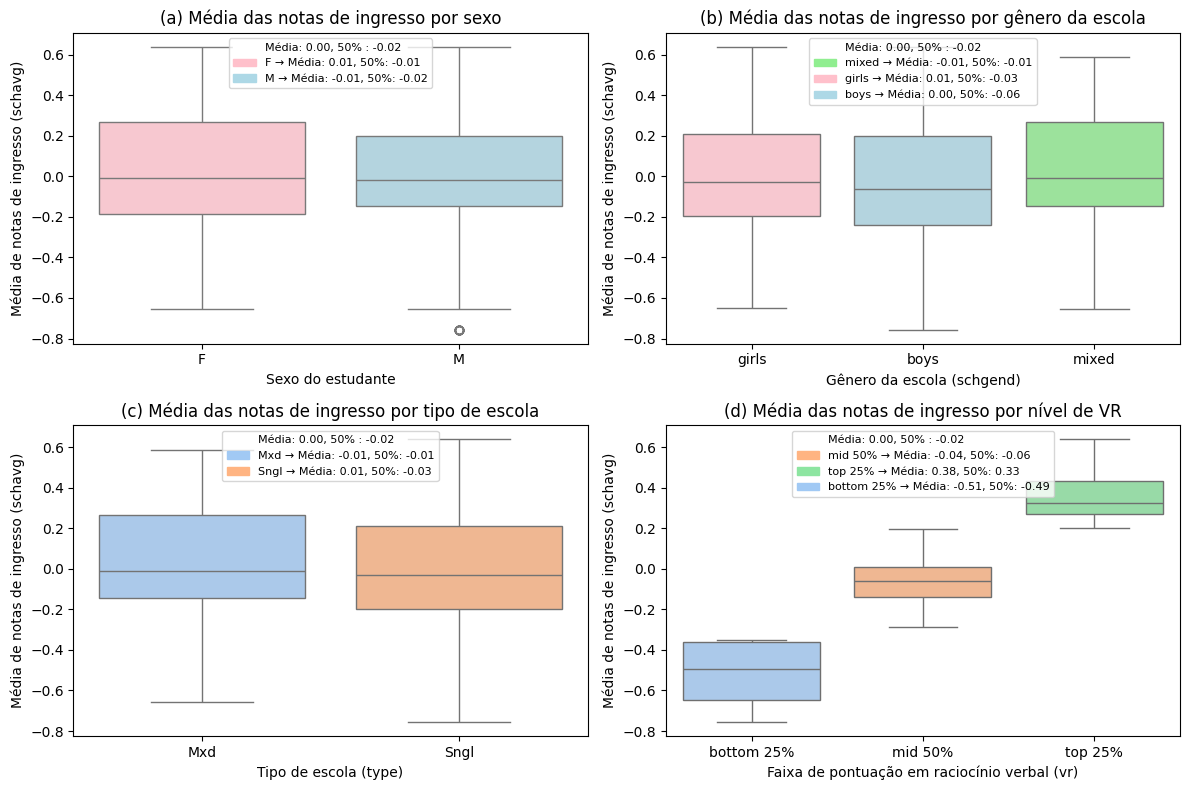

In [ ]:
plt.figure(figsize=(12, 8))
# --- (1) Média das notas de ingresso por sexo ---
plt.subplot(2, 2, 1)
group_colors_sex = {'F': 'pink', 'M': 'lightblue'}
ax1 = sns.boxplot(data=df_student, x='sex', y='schavg', palette=group_colors_sex)
plt.title('(a) Média das notas de ingresso por sexo')
plt.xlabel('Sexo do estudante')
plt.ylabel('Média de notas de ingresso (schavg)')
add_legend(ax1, df_student, 'sex', 'schavg', group_colors_sex)

# --- (2) Média das notas de ingresso por gênero da escola ---
plt.subplot(2, 2, 2)
group_colors_schgend = {'girls': 'pink', 'boys': 'lightblue', 'mixed': 'lightgreen'}
ax2 = sns.boxplot(data=df_student, x='schgend', y='schavg', order=['girls','boys','mixed'], palette=group_colors_schgend)
plt.title('(b) Média das notas de ingresso por gênero da escola')
plt.xlabel('Gênero da escola (schgend)')
plt.ylabel('Média de notas de ingresso (schavg)')
add_legend(ax2, df_student, 'schgend', 'schavg', group_colors_schgend)

# --- (3) Média das notas de ingresso por tipo de escola ---
plt.subplot(2, 2, 3)
school_types = df_student['type'].dropna().unique()
palette_type = {t: color for t, color in zip(school_types, sns.color_palette('pastel', len(school_types)))}
ax3 = sns.boxplot(data=df_student, x='type', y='schavg', palette=palette_type)
plt.title('(c) Média das notas de ingresso por tipo de escola')
plt.xlabel('Tipo de escola (type)')
plt.ylabel('Média de notas de ingresso (schavg)')
add_legend(ax3, df_student, 'type', 'schavg', palette_type)

# --- (4) Média das notas por nível de VR ---
plt.subplot(2, 2, 4)
vr_levels = ['bottom 25%', 'mid 50%', 'top 25%']
palette_vr = {level: color for level, color in zip(vr_levels, sns.color_palette('pastel', len(vr_levels)))}
ax4 = sns.boxplot(data=df_student, x='vr', y='schavg', order=vr_levels, palette=palette_vr)
plt.title('(d) Média das notas de ingresso por nível de VR')
plt.xlabel('Faixa de pontuação em raciocínio verbal (vr)')
plt.ylabel('Média de notas de ingresso (schavg)')
add_legend(ax4, df_student, 'vr', 'schavg', palette_vr)

# Ajuste de layout
plt.tight_layout()
plt.show()

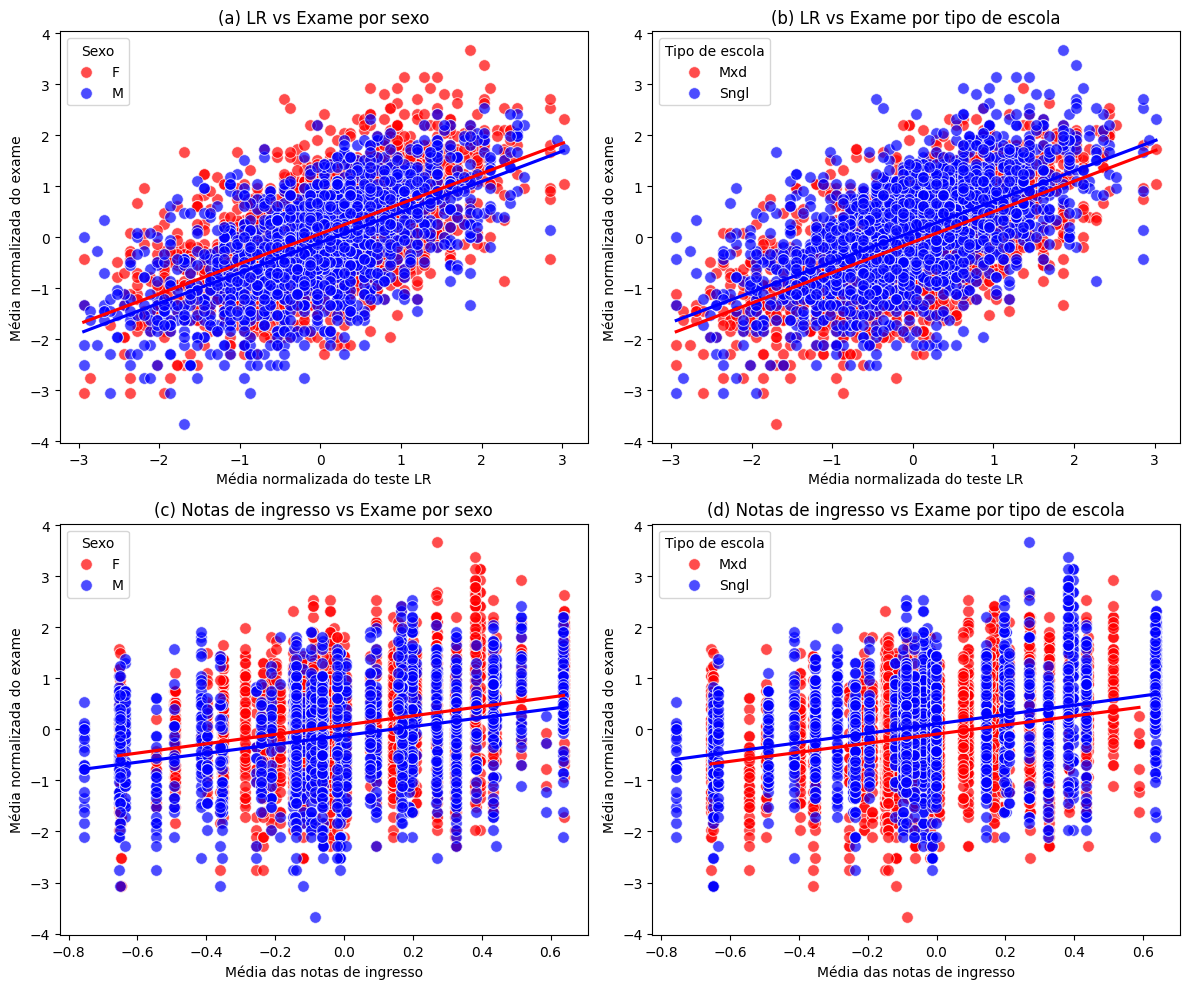

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

# --- Gráfico 1: LR vs Exame por sexo ---
plt.subplot(2, 2, 1)
for g, color in zip(['F','M'], ['red', 'blue']):
    subset = df_student[df_student['sex'] == g]
    sns.scatterplot(
        data=subset,
        x='standLRT',
        y='normexam',
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='standLRT',
        y='normexam',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média normalizada do teste LR')
plt.ylabel('Média normalizada do exame')
plt.title('(a) LR vs Exame por sexo')
plt.legend(title='Sexo')

# --- Gráfico 2: LR vs Exame por tipo de escola ---
plt.subplot(2, 2, 2)
for g, color in zip(['Mxd','Sngl'], ['red', 'blue']):
    subset = df_student[df_student['type'] == g]
    sns.scatterplot(
        data=subset,
        x='standLRT',
        y='normexam',
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='standLRT',
        y='normexam',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média normalizada do teste LR')
plt.ylabel('Média normalizada do exame')
plt.title('(b) LR vs Exame por tipo de escola')
plt.legend(title='Tipo de escola')

# --- Gráfico 3: Notas de ingresso vs Exame por sexo ---
plt.subplot(2, 2, 3)
for g, color in zip(['F','M'], ['red', 'blue']):
    subset = df_student[df_student['sex'] == g]
    sns.scatterplot(
        data=subset,
        x='schavg',
        y='normexam',
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='schavg',
        y='normexam',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média das notas de ingresso')
plt.ylabel('Média normalizada do exame')
plt.title('(c) Notas de ingresso vs Exame por sexo')
plt.legend(title='Sexo')

# --- Gráfico 4: Notas de ingresso vs Exame por tipo de escola ---
plt.subplot(2, 2, 4)
for g, color in zip(['Mxd','Sngl'], ['red', 'blue']):
    subset = df_student[df_student['type'] == g]
    sns.scatterplot(
        data=subset,
        x='schavg',
        y='normexam',
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='schavg',
        y='normexam',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média das notas de ingresso')
plt.ylabel('Média normalizada do exame')
plt.title('(d) Notas de ingresso vs Exame por tipo de escola')
plt.legend(title='Tipo de escola')

plt.tight_layout()
plt.show()


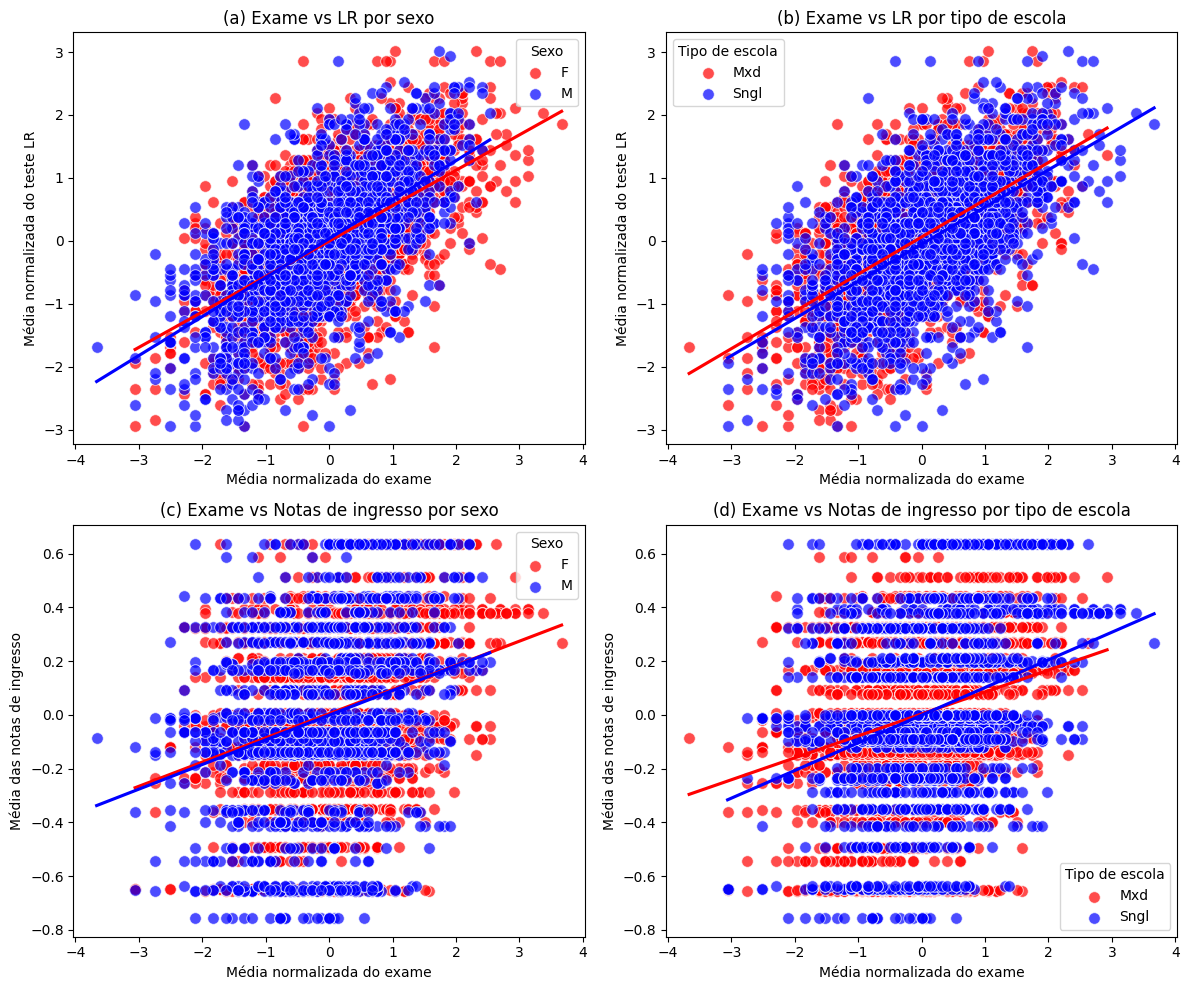

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

# --- Gráfico 1: Exame vs LR por sexo (eixos invertidos) ---
plt.subplot(2, 2, 1)
for g, color in zip(['F','M'], ['red', 'blue']):
    subset = df_student[df_student['sex'] == g]
    sns.scatterplot(
        data=subset,
        x='normexam',   # agora eixo x
        y='standLRT',   # agora eixo y
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='normexam',
        y='standLRT',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média normalizada do exame')
plt.ylabel('Média normalizada do teste LR')
plt.title('(a) Exame vs LR por sexo')
plt.legend(title='Sexo')

# --- Gráfico 2: Exame vs LR por tipo de escola ---
plt.subplot(2, 2, 2)
for g, color in zip(['Mxd','Sngl'], ['red', 'blue']):
    subset = df_student[df_student['type'] == g]
    sns.scatterplot(
        data=subset,
        x='normexam',
        y='standLRT',
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='normexam',
        y='standLRT',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média normalizada do exame')
plt.ylabel('Média normalizada do teste LR')
plt.title('(b) Exame vs LR por tipo de escola')
plt.legend(title='Tipo de escola')

# --- Gráfico 3: Exame vs Notas de ingresso por sexo ---
plt.subplot(2, 2, 3)
for g, color in zip(['F','M'], ['red', 'blue']):
    subset = df_student[df_student['sex'] == g]
    sns.scatterplot(
        data=subset,
        x='normexam',   # eixo x invertido
        y='schavg',     # eixo y invertido
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='normexam',
        y='schavg',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média normalizada do exame')
plt.ylabel('Média das notas de ingresso')
plt.title('(c) Exame vs Notas de ingresso por sexo')
plt.legend(title='Sexo')

# --- Gráfico 4: Exame vs Notas de ingresso por tipo de escola ---
plt.subplot(2, 2, 4)
for g, color in zip(['Mxd','Sngl'], ['red', 'blue']):
    subset = df_student[df_student['type'] == g]
    sns.scatterplot(
        data=subset,
        x='normexam',
        y='schavg',
        color=color,
        s=70,
        alpha=0.7,
        label=g
    )
    sns.regplot(
        data=subset,
        x='normexam',
        y='schavg',
        scatter=False,
        color=color,
        ci=None
    )
plt.xlabel('Média normalizada do exame')
plt.ylabel('Média das notas de ingresso')
plt.title('(d) Exame vs Notas de ingresso por tipo de escola')
plt.legend(title='Tipo de escola')

plt.tight_layout()
plt.show()


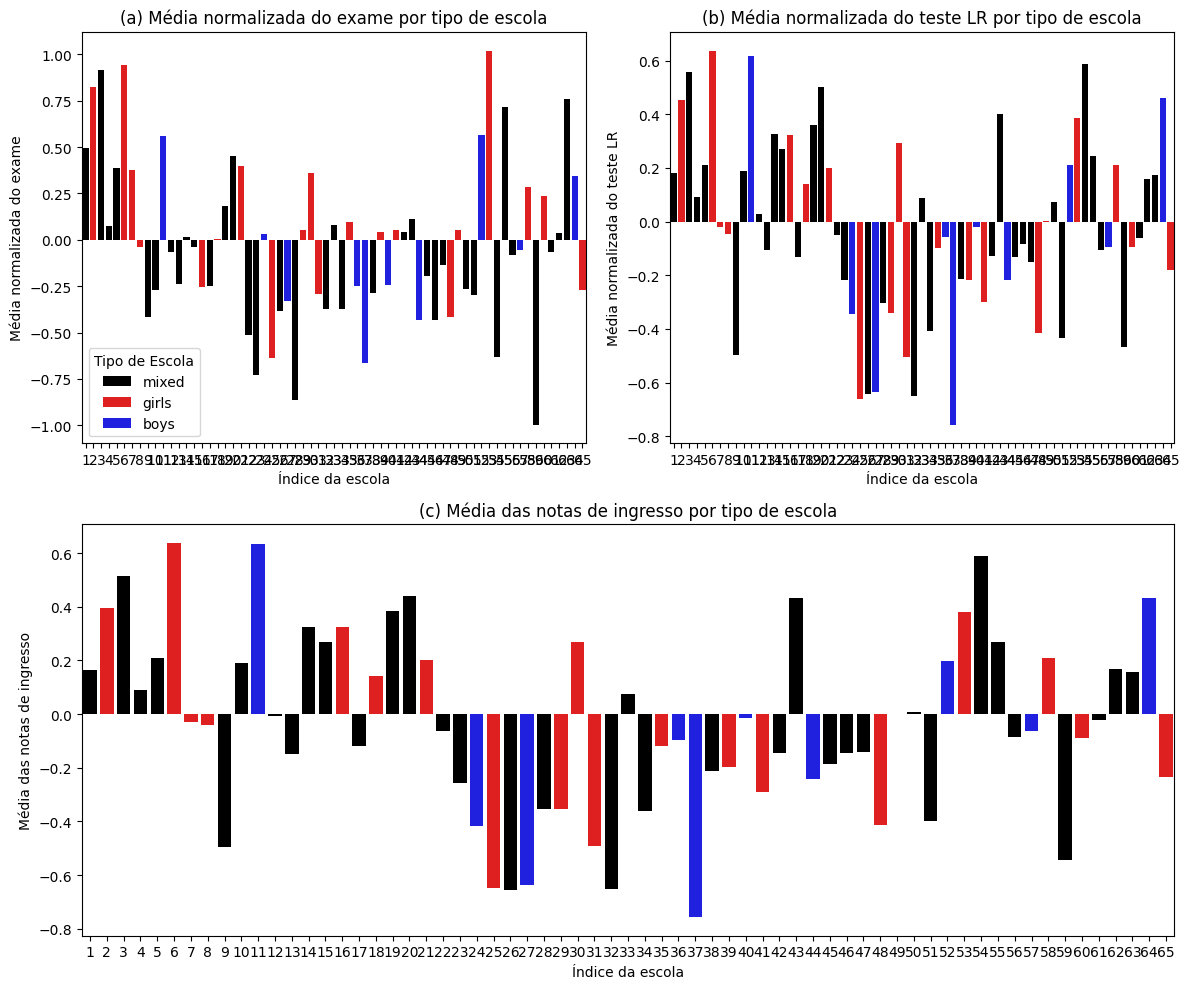

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cria a figura com 3 subplots (2 em cima e 1 embaixo)
plt.figure(figsize=(12, 10))

# --- Gráfico 1 ---
plt.subplot(2, 2, 1)
sns.barplot(
    data=df_school,
    x=df_school.index,
    y='mean_normexam',
    hue='schgend',
    palette={'mixed': 'black', 'girls': 'red', 'boys': 'blue'}
)
plt.xlabel('Índice da escola')
plt.ylabel('Média normalizada do exame')
plt.title('(a) Média normalizada do exame por tipo de escola')
plt.legend(title='Tipo de Escola')

# --- Gráfico 2 ---
plt.subplot(2, 2, 2)
sns.barplot(
    data=df_school,
    x=df_school.index,
    y='mean_standLRT',
    hue='schgend',
    palette={'mixed': 'black', 'girls': 'red', 'boys': 'blue'},
    legend=False  # evita repetir legenda
)
plt.xlabel('Índice da escola')
plt.ylabel('Média normalizada do teste LR')
plt.title('(b) Média normalizada do teste LR por tipo de escola')

# --- Gráfico 3 ---
plt.subplot(2, 1, 2)  # ocupa toda a segunda linha
sns.barplot(
    data=df_school,
    x=df_school.index,
    y='schavg',
    hue='schgend',
    palette={'mixed': 'black', 'girls': 'red', 'boys': 'blue'},
    legend=False
)
plt.xlabel('Índice da escola')
plt.ylabel('Média das notas de ingresso')
plt.title('(c) Média das notas de ingresso por tipo de escola')

plt.tight_layout()
plt.show()

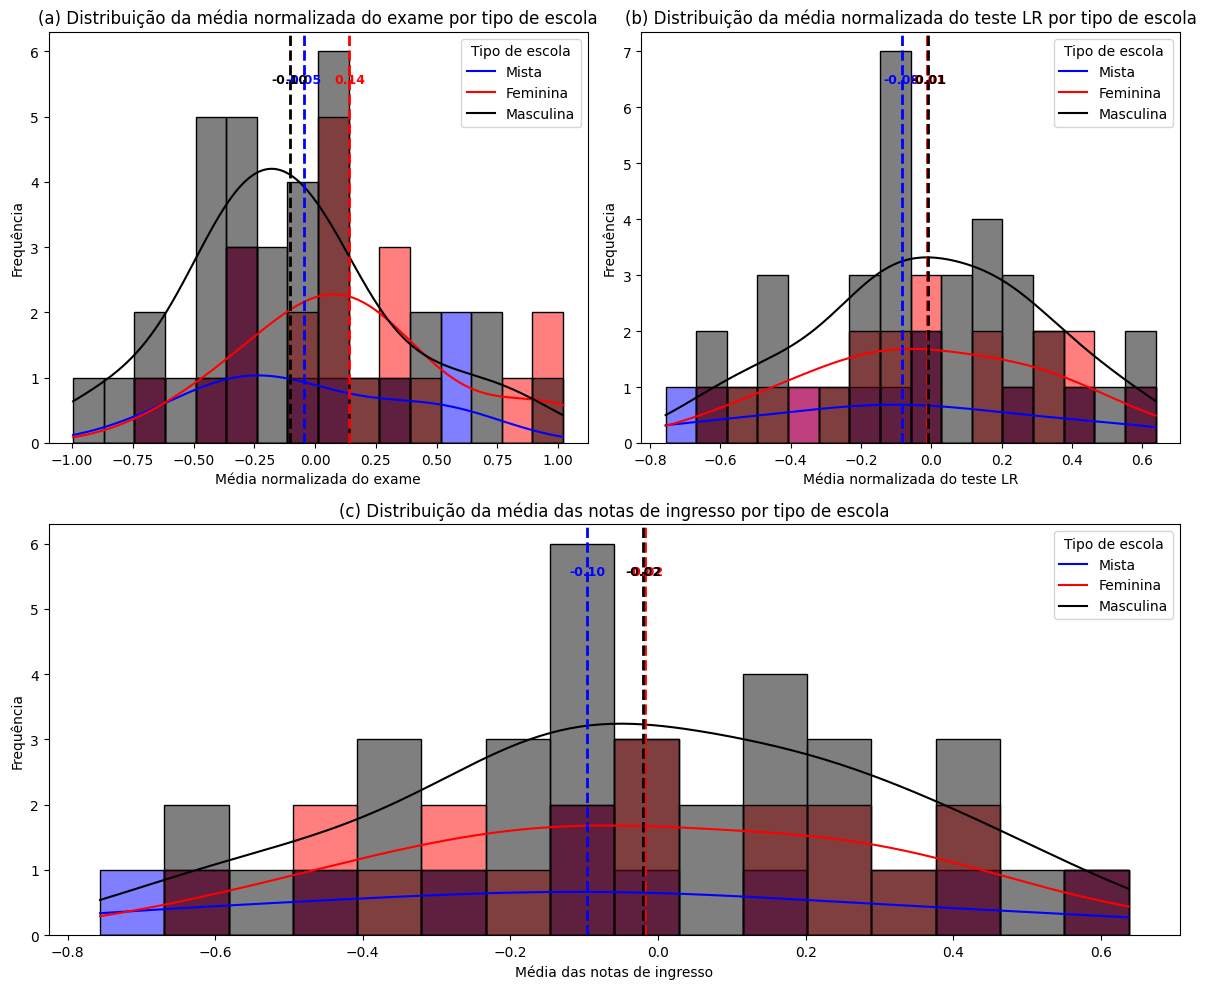

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

bins = 16
cores = {'mixed': 'black', 'girls': 'red', 'boys': 'blue'}
rotulos = {'mixed': 'Mista', 'girls': 'Feminina', 'boys': 'Masculina'}

plt.figure(figsize=(12, 10))

# --- Função auxiliar para adicionar linhas de média ---
def adicionar_linhas_medias(ax, coluna):
    medias = df_school.groupby('schgend')[coluna].mean()
    for tipo, media in medias.items():
        ax.axvline(media, color=cores[tipo], linestyle='--', linewidth=2)
        ax.text(
            media, ax.get_ylim()[1]*0.9,  # posição do texto
            f"{media:.2f}",
            color=cores[tipo],
            ha='center', va='top',
            fontsize=9, fontweight='bold'
        )

# --- (a) Média normalizada do exame ---
plt.subplot(2, 2, 1)
ax1 = sns.histplot(
    data=df_school,
    x='mean_normexam',
    bins=bins,
    hue='schgend',
    palette=cores,
    kde=True
)
adicionar_linhas_medias(ax1, 'mean_normexam')
plt.xlabel('Média normalizada do exame')
plt.ylabel('Frequência')
plt.title('(a) Distribuição da média normalizada do exame por tipo de escola')
plt.legend(title='Tipo de escola', labels=rotulos.values())

# --- (b) Média normalizada do teste LR ---
plt.subplot(2, 2, 2)
ax2 = sns.histplot(
    data=df_school,
    x='mean_standLRT',
    bins=bins,
    hue='schgend',
    palette=cores,
    kde=True
)
adicionar_linhas_medias(ax2, 'mean_standLRT')
plt.xlabel('Média normalizada do teste LR')
plt.ylabel('Frequência')
plt.title('(b) Distribuição da média normalizada do teste LR por tipo de escola')
plt.legend(title='Tipo de escola', labels=rotulos.values())

# --- (c) Média das notas de ingresso ---
plt.subplot(2, 1, 2)
ax3 = sns.histplot(
    data=df_school,
    x='schavg',
    bins=bins,
    hue='schgend',
    palette=cores,
    kde=True
)
adicionar_linhas_medias(ax3, 'schavg')
plt.xlabel('Média das notas de ingresso')
plt.ylabel('Frequência')
plt.title('(c) Distribuição da média das notas de ingresso por tipo de escola')
plt.legend(title='Tipo de escola', labels=rotulos.values())

plt.tight_layout()
plt.show()


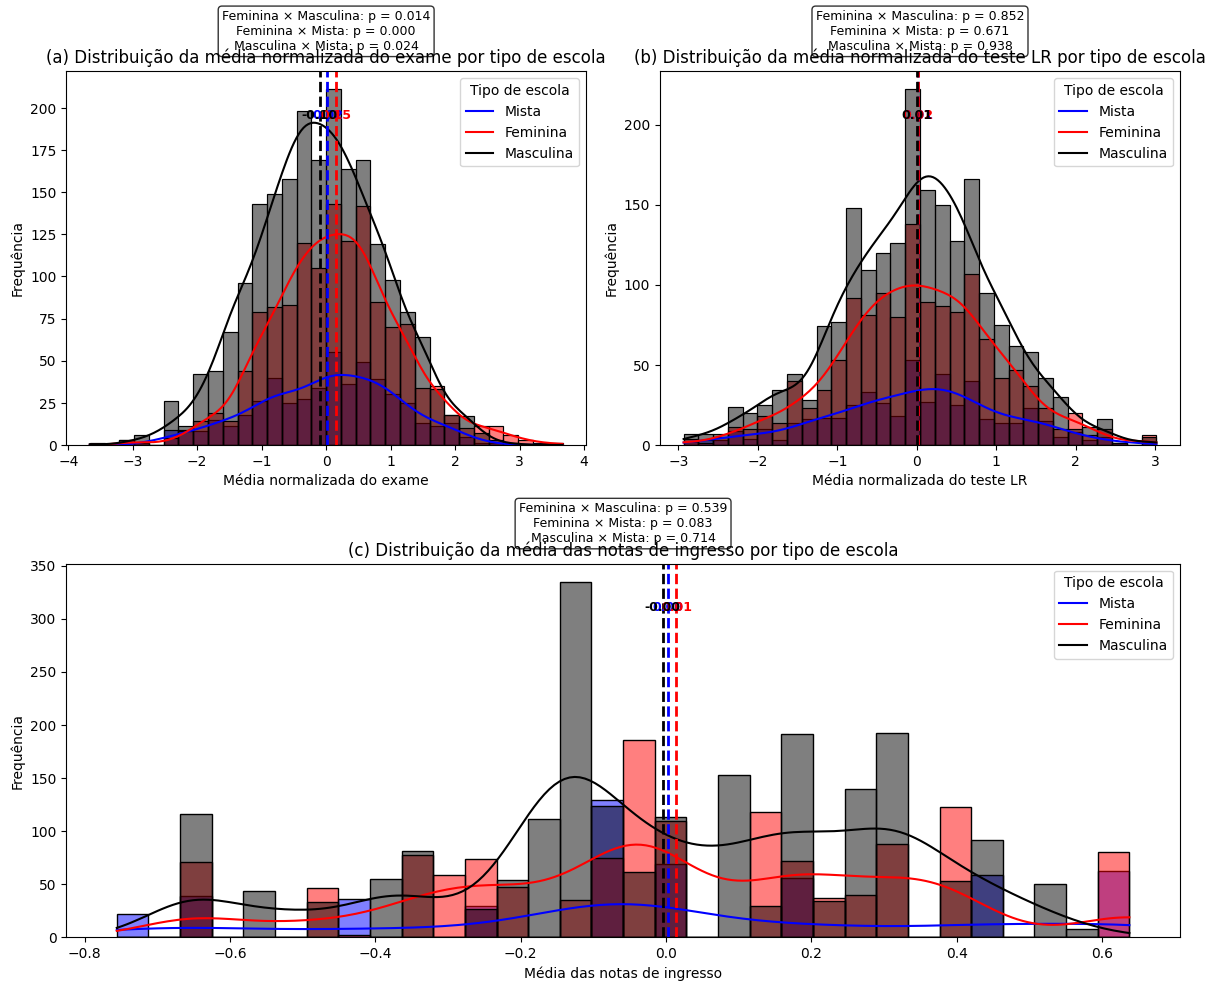

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
import numpy as np

bins = 32
cores = {'mixed': 'black', 'girls': 'red', 'boys': 'blue'}
rotulos = {'mixed': 'Mista', 'girls': 'Feminina', 'boys': 'Masculina'}

plt.figure(figsize=(12, 10))

# --- Função auxiliar para adicionar linhas de média ---
def adicionar_linhas_medias(ax, coluna):
    medias = df_student.groupby('schgend')[coluna].mean()
    for tipo, media in medias.items():
        ax.axvline(media, color=cores[tipo], linestyle='--', linewidth=2)
        ax.text(
            media, ax.get_ylim()[1]*0.9,
            f"{media:.2f}",
            color=cores[tipo],
            ha='center', va='top',
            fontsize=9, fontweight='bold'
        )

# --- Função para calcular e exibir testes t ---
def mostrar_ttest(ax, coluna):
    grupos = df_student['schgend'].unique()
    pares = [('girls', 'boys'), ('girls', 'mixed'), ('boys', 'mixed')]
    resultados = []
    for g1, g2 in pares:
        if g1 in grupos and g2 in grupos:
            d1 = df_student[df_student['schgend'] == g1][coluna].dropna()
            d2 = df_student[df_student['schgend'] == g2][coluna].dropna()
            stat, p = ttest_ind(d1, d2, equal_var=False)
            resultados.append(f"{rotulos[g1]} × {rotulos[g2]}: p = {p:.3f}")
    texto = "\n".join(resultados)
    ax.text(
        0.5, 1.05, texto,
        transform=ax.transAxes,
        ha='center', va='bottom',
        fontsize=9,
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round')
    )

# --- (a) Média normalizada do exame ---
plt.subplot(2, 2, 1)
ax1 = sns.histplot(
    data=df_student,
    x='normexam',
    bins=bins,
    hue='schgend',
    palette=cores,
    kde=True
)
adicionar_linhas_medias(ax1, 'normexam')
mostrar_ttest(ax1, 'normexam')
plt.xlabel('Média normalizada do exame')
plt.ylabel('Frequência')
plt.title('(a) Distribuição da média normalizada do exame por tipo de escola')
plt.legend(title='Tipo de escola', labels=rotulos.values())

# --- (b) Média normalizada do teste LR ---
plt.subplot(2, 2, 2)
ax2 = sns.histplot(
    data=df_student,
    x='standLRT',
    bins=bins,
    hue='schgend',
    palette=cores,
    kde=True
)
adicionar_linhas_medias(ax2, 'standLRT')
mostrar_ttest(ax2, 'standLRT')
plt.xlabel('Média normalizada do teste LR')
plt.ylabel('Frequência')
plt.title('(b) Distribuição da média normalizada do teste LR por tipo de escola')
plt.legend(title='Tipo de escola', labels=rotulos.values())

# --- (c) Média das notas de ingresso ---
plt.subplot(2, 1, 2)
ax3 = sns.histplot(
    data=df_student,
    x='schavg',
    bins=bins,
    hue='schgend',
    palette=cores,
    kde=True
)
adicionar_linhas_medias(ax3, 'schavg')
mostrar_ttest(ax3, 'schavg')
plt.xlabel('Média das notas de ingresso')
plt.ylabel('Frequência')
plt.title('(c) Distribuição da média das notas de ingresso por tipo de escola')
plt.legend(title='Tipo de escola', labels=rotulos.values())

plt.tight_layout()
plt.show()


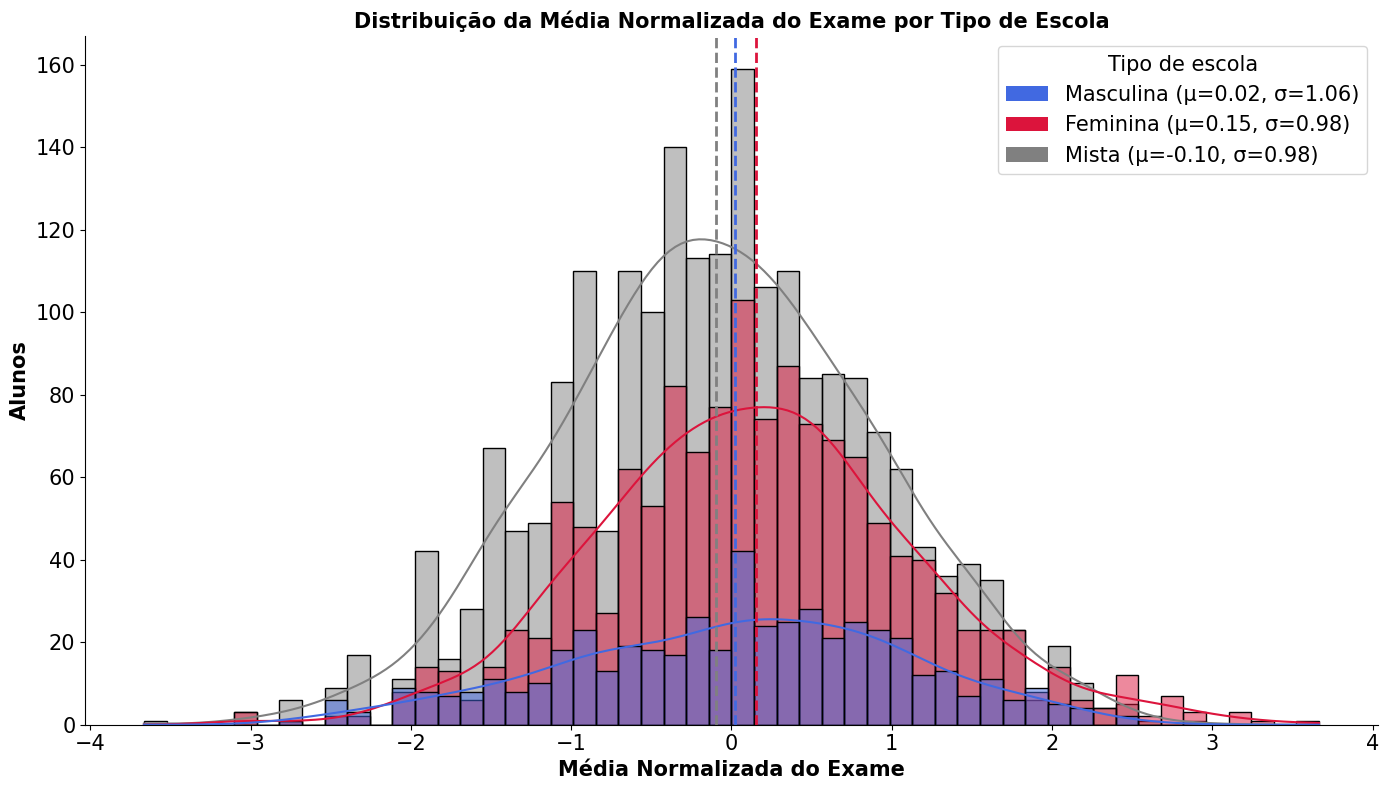

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Paleta de cores e rótulos
cores = {'mixed': 'gray', 'girls': 'crimson', 'boys': 'royalblue'}
rotulos = {'mixed': 'Mista', 'girls': 'Feminina', 'boys': 'Masculina'}

plt.figure(figsize=(14,8))

# Plot principal
sns.histplot(
    data=df_student,
    x='normexam',
    hue='schgend',
    hue_order=['boys', 'girls', 'mixed'],
    bins=52,
    palette=cores,
    kde=True,
    alpha=0.5,
    edgecolor='black'
)

# Calcular e desenhar as médias + desvio padrão
handles = []
for tipo, grupo in df_student.groupby('schgend'):
    media = grupo['normexam'].mean()
    desvio = grupo['normexam'].std()
    plt.axvline(media, color=cores[tipo], linestyle='--', linewidth=2)
    label = f"{rotulos[tipo]} (μ={media:.2f}, σ={desvio:.2f})"
    handles.append(Patch(facecolor=cores[tipo], label=label))

# Criar legenda manualmente
plt.legend(
    handles=handles,
    title='Tipo de escola',
    fontsize=15,
    title_fontsize=15
)

# Estilo geral
plt.xlabel('Média Normalizada do Exame', fontsize=15, fontweight='bold')
plt.ylabel('Alunos', fontsize=15, fontweight='bold')
plt.title('Distribuição da Média Normalizada do Exame por Tipo de Escola', fontsize=15, fontweight='bold')
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
sns.despine()
plt.tight_layout()
plt.show()


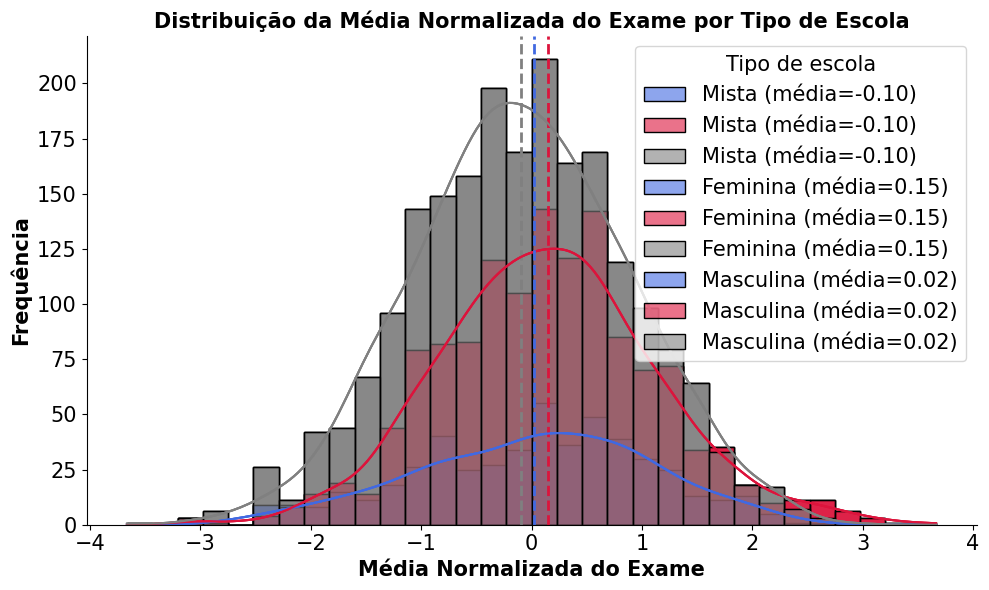

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta de cores e rótulos
cores = {'mixed': 'gray', 'girls': 'crimson', 'boys': 'royalblue'}
rotulos = {'mixed': 'Mista', 'girls': 'Feminina', 'boys': 'Masculina'}

plt.figure(figsize=(10,6))

# Histograma
for tipo in df_student['schgend'].unique():
    dados = df_student[df_student['schgend']==tipo]['normexam']
    media = dados.mean()
    sns.histplot(
        data=df_student,
        x='normexam',
        hue='schgend',
        bins=32,
        palette=cores,
        kde=True,
        alpha=0.6,
        edgecolor='black',
        color=cores[tipo],
        label=f"{rotulos[tipo]} (média={media:.2f})"
    )
    # Linha de média
    plt.axvline(media, color=cores[tipo], linestyle='--', linewidth=2)



# Personalização
plt.xlabel('Média Normalizada do Exame', fontsize=15, fontweight='bold')
plt.ylabel('Frequência', fontsize=15, fontweight='bold')
plt.title('Distribuição da Média Normalizada do Exame por Tipo de Escola', fontsize=15, fontweight='bold')
plt.legend(title='Tipo de escola', fontsize=15, title_fontsize=15)
sns.despine()
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.tight_layout()
plt.show()


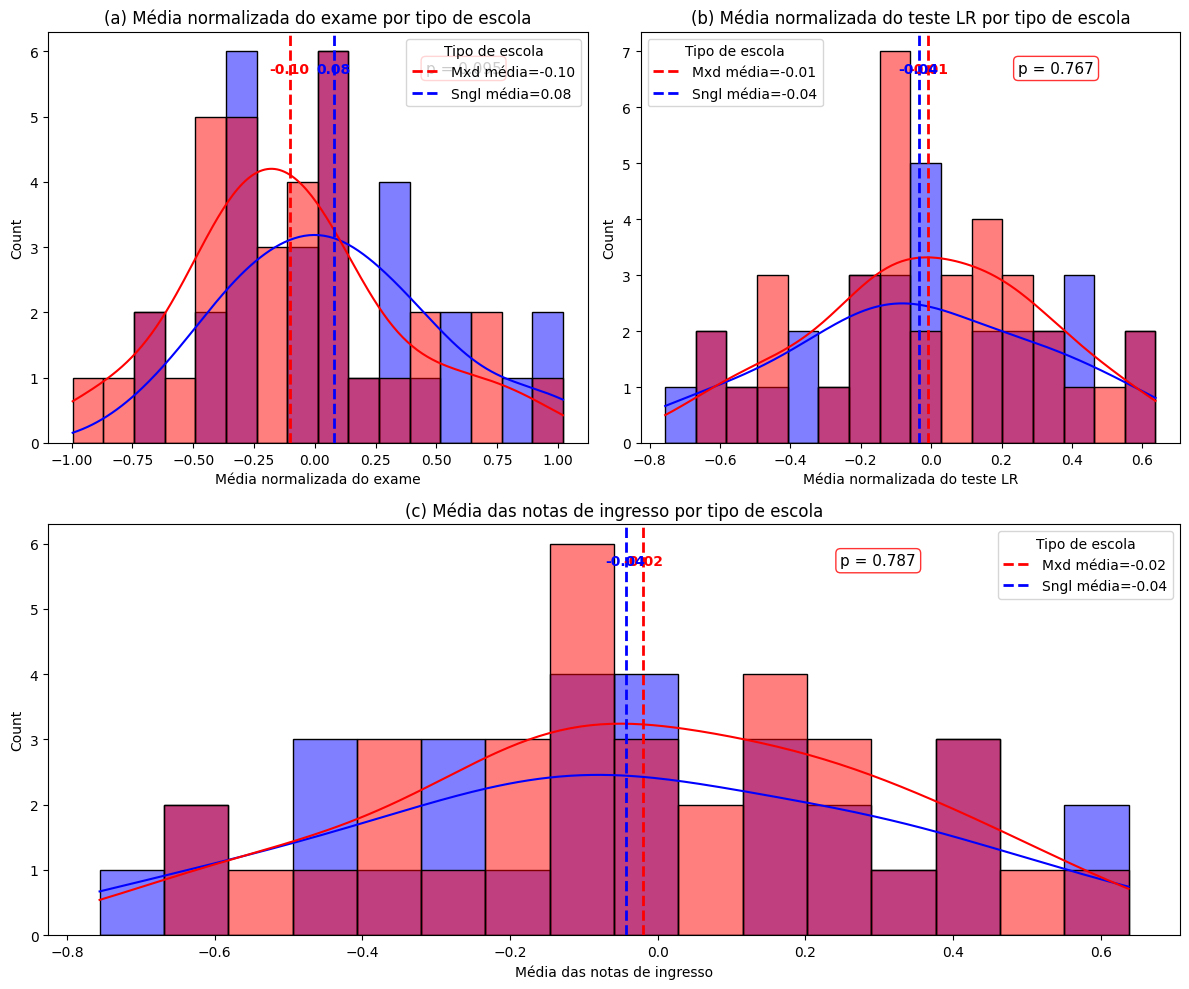

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
import numpy as np

bins = 16

plt.figure(figsize=(12, 10))

# --- Função auxiliar para adicionar médias e p-valor ---
def adicionar_medias_pvalor(ax, data, var, group_col='type', palette=None):
    grupos = data[group_col].unique()
    cores = palette if palette else ['red', 'blue']

    medias = {}
    for g, cor in zip(grupos, cores):
        subset = data[data[group_col] == g][var].dropna()
        media = subset.mean()
        medias[g] = media
        ax.axvline(media, color=cor, linestyle='--', linewidth=2, label=f'{g} média={media:.2f}')
        ax.text(media, ax.get_ylim()[1]*0.9, f'{media:.2f}', color=cor, ha='center', fontsize=10, fontweight='bold')

    # Teste t entre os dois grupos
    if len(grupos) == 2:
        g1, g2 = grupos
        stat, p = ttest_ind(
            data[data[group_col]==g1][var].dropna(),
            data[data[group_col]==g2][var].dropna(),
            equal_var=False
        )
        ax.text(0.7, 0.9, f'p = {p:.3f}', transform=ax.transAxes, fontsize=11,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red", alpha=0.8))
    return medias

# --- Gráfico 1: mean_normexam ---
ax1 = plt.subplot(2, 2, 1)
sns.histplot(
    data=df_school,
    x='mean_normexam',
    bins=bins,
    hue='type',
    palette={'Mxd': 'red', 'Sngl': 'blue'},
    kde=True
)
plt.xlabel('Média normalizada do exame')
plt.title('(a) Média normalizada do exame por tipo de escola')
adicionar_medias_pvalor(ax1, df_school, 'mean_normexam', group_col='type', palette=['red','blue'])
plt.legend(title='Tipo de escola')

# --- Gráfico 2: mean_standLRT ---
ax2 = plt.subplot(2, 2, 2)
sns.histplot(
    data=df_school,
    x='mean_standLRT',
    bins=bins,
    hue='type',
    palette={'Mxd': 'red', 'Sngl': 'blue'},
    kde=True
)
plt.xlabel('Média normalizada do teste LR')
plt.title('(b) Média normalizada do teste LR por tipo de escola')
adicionar_medias_pvalor(ax2, df_school, 'mean_standLRT', group_col='type', palette=['red','blue'])
plt.legend(title='Tipo de escola')

# --- Gráfico 3: schavg ---
ax3 = plt.subplot(2, 1, 2)
sns.histplot(
    data=df_school,
    x='schavg',
    bins=bins,
    hue='type',
    palette={'Mxd': 'red', 'Sngl': 'blue'},
    kde=True
)
plt.xlabel('Média das notas de ingresso')
plt.title('(c) Média das notas de ingresso por tipo de escola')
adicionar_medias_pvalor(ax3, df_school, 'schavg', group_col='type', palette=['red','blue'])
plt.legend(title='Tipo de escola')

plt.tight_layout()
plt.show()


/tmp/ipython-input-1191928567.py:41: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.

/tmp/ipython-input-1191928567.py:49: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



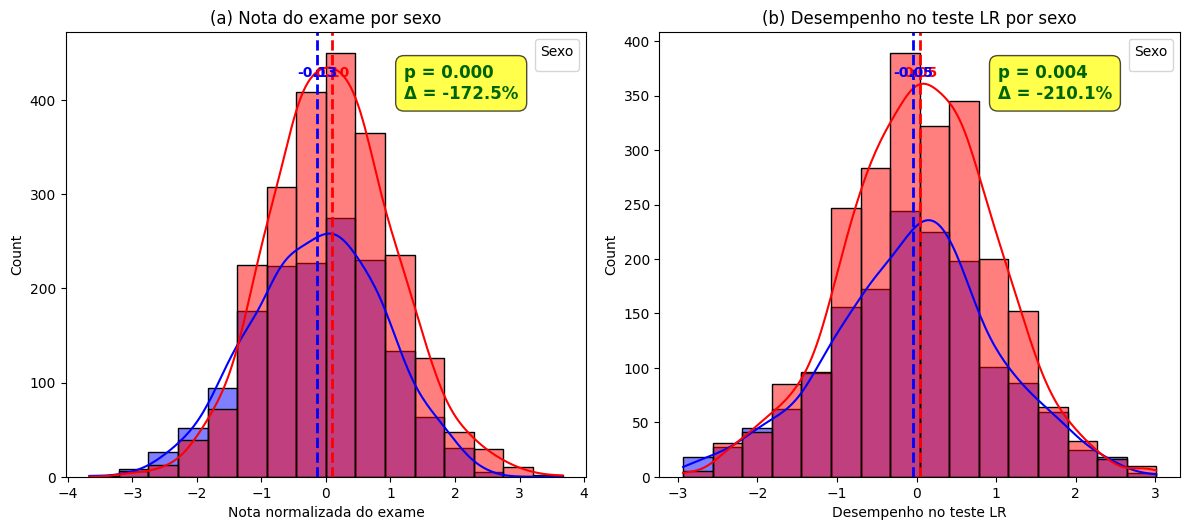

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

bins = 16
plt.figure(figsize=(12, 10))

def adicionar_medias_pvalor(ax, data, var, group_col='sex', palette=None):
    grupos = data[group_col].dropna().unique()
    cores = palette if palette else ['red','blue']
    medias = {}

    # Calcula médias
    for g, cor in zip(grupos, cores):
        subset = data[data[group_col]==g][var].dropna()
        media = subset.mean()
        medias[g] = media
        ax.axvline(media, color=cor, linestyle='--', linewidth=2)
        ax.text(media, ax.get_ylim()[1]*0.9, f'{media:.2f}', color=cor,
                ha='center', fontsize=10, fontweight='bold')

    # Calcula p-valor usando scipy.stats.ttest_ind
    if len(grupos) == 2:
        g1, g2 = grupos
        v1 = data[data[group_col]==g1][var].dropna()
        v2 = data[data[group_col]==g2][var].dropna()
        stat, p = stats.ttest_ind(v1, v2, equal_var=False)
        diff_perc = (medias[g1]-medias[g2])/medias[g2]*100
        ax.text(0.65, 0.85, f'p = {p:.3f}\nΔ = {diff_perc:.1f}%',
                transform=ax.transAxes, fontsize=12, fontweight='bold',
                color='darkgreen', bbox=dict(boxstyle="round,pad=0.5", fc="yellow", ec="black", alpha=0.7))
    return medias

# --- Gráfico 1: normexam ---
ax1 = plt.subplot(2,2,1)
sns.histplot(df_student, x='normexam', bins=bins, hue='sex', palette={'F':'red','M':'blue'}, kde=True)
plt.xlabel('Nota normalizada do exame')
plt.title('(a) Nota do exame por sexo')
adicionar_medias_pvalor(ax1, df_student, 'normexam', group_col='sex', palette=['red','blue'])
plt.legend(title='Sexo')

# --- Gráfico 2: standLRT ---
ax2 = plt.subplot(2,2,2)
sns.histplot(df_student, x='standLRT', bins=bins, hue='sex', palette={'F':'red','M':'blue'}, kde=True)
plt.xlabel('Desempenho no teste LR')
plt.title('(b) Desempenho no teste LR por sexo')
adicionar_medias_pvalor(ax2, df_student, 'standLRT', group_col='sex', palette=['red','blue'])
plt.legend(title='Sexo')



plt.tight_layout()
plt.show()


/tmp/ipython-input-3679813433.py:38: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.

/tmp/ipython-input-3679813433.py:46: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



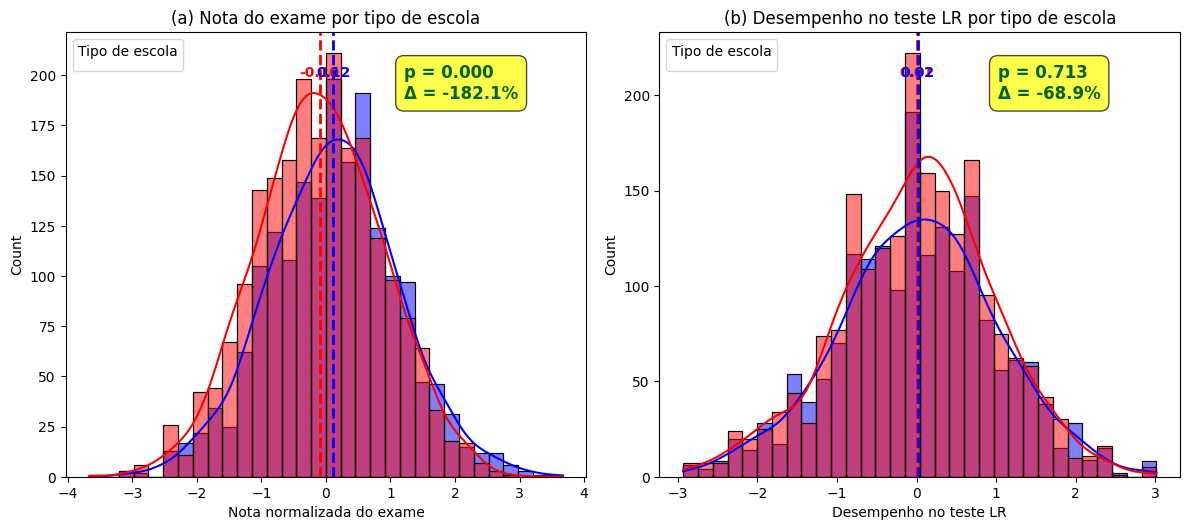

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

bins = 32
plt.figure(figsize=(12, 10))

def adicionar_medias_pvalor_tipo(ax, data, var, group_col='type', palette=None):
    grupos = data[group_col].dropna().unique()
    cores = palette if palette else ['red','blue']
    medias = {}

    for g, cor in zip(grupos, cores):
        subset = data[data[group_col]==g][var].dropna()
        media = subset.mean()
        medias[g] = media
        ax.axvline(media, color=cor, linestyle='--', linewidth=2)
        ax.text(media, ax.get_ylim()[1]*0.9, f'{media:.2f}', color=cor,
                ha='center', fontsize=10, fontweight='bold')

    if len(grupos) == 2:
        g1, g2 = grupos
        v1 = data[data[group_col]==g1][var].dropna()
        v2 = data[data[group_col]==g2][var].dropna()
        stat, p = stats.ttest_ind(v1, v2, equal_var=False)
        diff_perc = (medias[g1]-medias[g2])/medias[g2]*100
        ax.text(0.65, 0.85, f'p = {p:.3f}\nΔ = {diff_perc:.1f}%',
                transform=ax.transAxes, fontsize=12, fontweight='bold',
                color='darkgreen', bbox=dict(boxstyle="round,pad=0.5", fc="yellow", ec="black", alpha=0.7))
    return medias

# --- Gráfico 1: normexam ---
ax1 = plt.subplot(2,2,1)
sns.histplot(df_student, x='normexam', bins=bins, hue='type', palette={'Mxd':'red','Sngl':'blue'}, kde=True)
plt.xlabel('Nota normalizada do exame')
plt.title('(a) Nota do exame por tipo de escola')
adicionar_medias_pvalor_tipo(ax1, df_student, 'normexam', group_col='type', palette=['red','blue'])
plt.legend(title='Tipo de escola')

# --- Gráfico 2: standLRT ---
ax2 = plt.subplot(2,2,2)
sns.histplot(df_student, x='standLRT', bins=bins, hue='type', palette={'Mxd':'red','Sngl':'blue'}, kde=True)
plt.xlabel('Desempenho no teste LR')
plt.title('(b) Desempenho no teste LR por tipo de escola')
adicionar_medias_pvalor_tipo(ax2, df_student, 'standLRT', group_col='type', palette=['red','blue'])
plt.legend(title='Tipo de escola')



plt.tight_layout()
plt.show()


/tmp/ipython-input-3972260414.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.

/tmp/ipython-input-3972260414.py:32: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



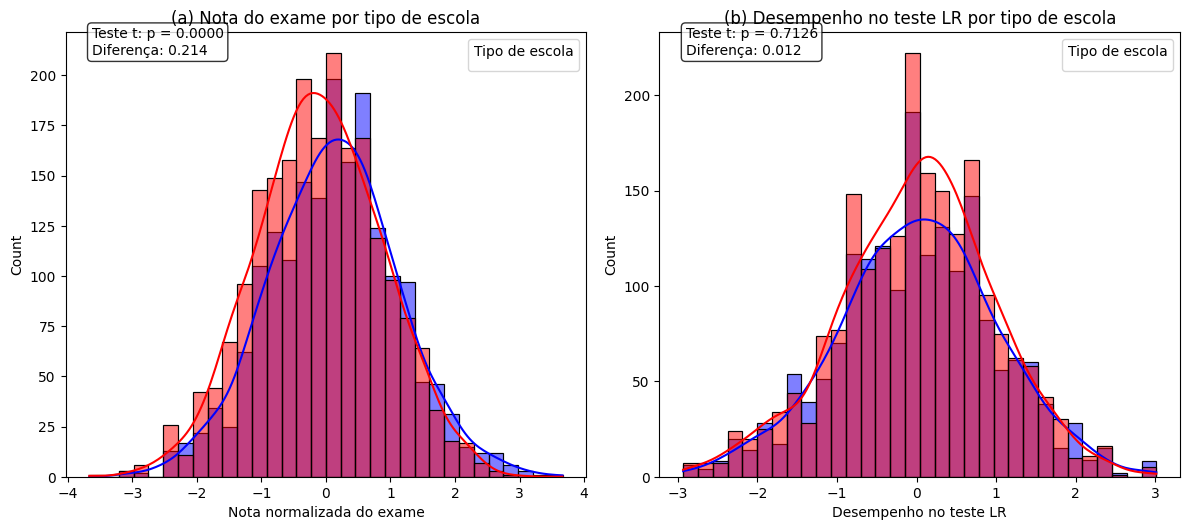

RESULTADOS DOS TESTES ESTATÍSTICOS

1. NOTA DO EXAME (normexam):
   Mxd (n=2096): Média = -0.097
   Sngl (n=1840): Média = 0.118
   Diferença (Sngl - Mxd): 0.214
   Estatística t: -6.748
   Valor p: 0.0000
   Significativo (p < 0.05): SIM

2. TESTE LR (standLRT):
   Mxd (n=2079): Média = 0.005
   Sngl (n=1828): Média = 0.017
   Diferença (Sngl - Mxd): 0.012
   Estatística t: -0.368
   Valor p: 0.7126
   Significativo (p < 0.05): NÃO

INTERPRETAÇÃO:
✓ Há diferença SIGNIFICATIVA no exame: escolas Sngl são MELHORES
✗ NÃO há diferença significativa no teste LR entre os tipos de escola


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

bins = 32
plt.figure(figsize=(12, 10))

# --- Gráfico 1: normexam ---
ax1 = plt.subplot(2, 2, 1)
sns.histplot(df_student, x='normexam', bins=bins, hue='type', palette={'Mxd':'red','Sngl':'blue'}, kde=True)
plt.xlabel('Nota normalizada do exame')
plt.title('(a) Nota do exame por tipo de escola')
plt.legend(title='Tipo de escola')

# Teste t para normexam
mxd_normexam = df_student[df_student['type'] == 'Mxd']['normexam'].dropna()
sngl_normexam = df_student[df_student['type'] == 'Sngl']['normexam'].dropna()

t_stat_normexam, p_value_normexam = stats.ttest_ind(mxd_normexam, sngl_normexam, equal_var=False)
diff_normexam = sngl_normexam.mean() - mxd_normexam.mean()

# Adicionar resultados do teste no gráfico
ax1.text(0.05, 0.95, f'Teste t: p = {p_value_normexam:.4f}\nDiferença: {diff_normexam:.3f}',
         transform=ax1.transAxes, fontsize=10, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

# --- Gráfico 2: standLRT ---
ax2 = plt.subplot(2, 2, 2)
sns.histplot(df_student, x='standLRT', bins=bins, hue='type', palette={'Mxd':'red','Sngl':'blue'}, kde=True)
plt.xlabel('Desempenho no teste LR')
plt.title('(b) Desempenho no teste LR por tipo de escola')
plt.legend(title='Tipo de escola')

# Teste t para standLRT
mxd_standLRT = df_student[df_student['type'] == 'Mxd']['standLRT'].dropna()
sngl_standLRT = df_student[df_student['type'] == 'Sngl']['standLRT'].dropna()

t_stat_standLRT, p_value_standLRT = stats.ttest_ind(mxd_standLRT, sngl_standLRT, equal_var=False)
diff_standLRT = sngl_standLRT.mean() - mxd_standLRT.mean()

# Adicionar resultados do teste no gráfico
ax2.text(0.05, 0.95, f'Teste t: p = {p_value_standLRT:.4f}\nDiferença: {diff_standLRT:.3f}',
         transform=ax2.transAxes, fontsize=10, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

# --- Resultados numéricos detalhados ---
print("=" * 50)
print("RESULTADOS DOS TESTES ESTATÍSTICOS")
print("=" * 50)

print("\n1. NOTA DO EXAME (normexam):")
print(f"   Mxd (n={len(mxd_normexam)}): Média = {mxd_normexam.mean():.3f}")
print(f"   Sngl (n={len(sngl_normexam)}): Média = {sngl_normexam.mean():.3f}")
print(f"   Diferença (Sngl - Mxd): {diff_normexam:.3f}")
print(f"   Estatística t: {t_stat_normexam:.3f}")
print(f"   Valor p: {p_value_normexam:.4f}")
print(f"   Significativo (p < 0.05): {'SIM' if p_value_normexam < 0.05 else 'NÃO'}")

print("\n2. TESTE LR (standLRT):")
print(f"   Mxd (n={len(mxd_standLRT)}): Média = {mxd_standLRT.mean():.3f}")
print(f"   Sngl (n={len(sngl_standLRT)}): Média = {sngl_standLRT.mean():.3f}")
print(f"   Diferença (Sngl - Mxd): {diff_standLRT:.3f}")
print(f"   Estatística t: {t_stat_standLRT:.3f}")
print(f"   Valor p: {p_value_standLRT:.4f}")
print(f"   Significativo (p < 0.05): {'SIM' if p_value_standLRT < 0.05 else 'NÃO'}")

# --- Interpretação ---
print("\n" + "=" * 50)
print("INTERPRETAÇÃO:")
print("=" * 50)

if p_value_normexam < 0.05:
    if diff_normexam > 0:
        print("✓ Há diferença SIGNIFICATIVA no exame: escolas Sngl são MELHORES")
    else:
        print("✓ Há diferença SIGNIFICATIVA no exame: escolas Mxd são MELHORES")
else:
    print("✗ NÃO há diferença significativa no desempenho do exame entre os tipos de escola")

if p_value_standLRT < 0.05:
    if diff_standLRT > 0:
        print("✓ Há diferença SIGNIFICATIVA no teste LR: escolas Sngl são MELHORES")
    else:
        print("✓ Há diferença SIGNIFICATIVA no teste LR: escolas Mxd são MELHORES")
else:
    print("✗ NÃO há diferença significativa no teste LR entre os tipos de escola")

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


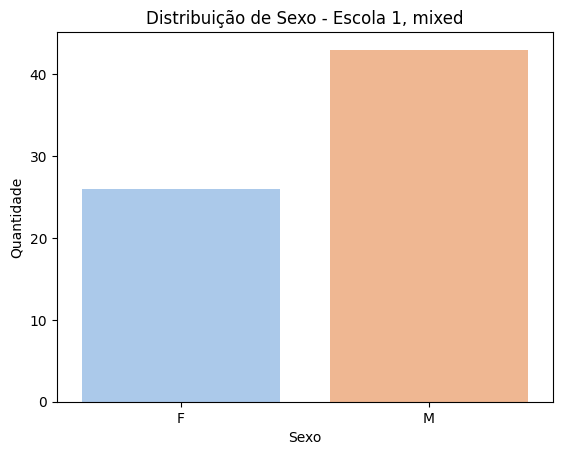

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


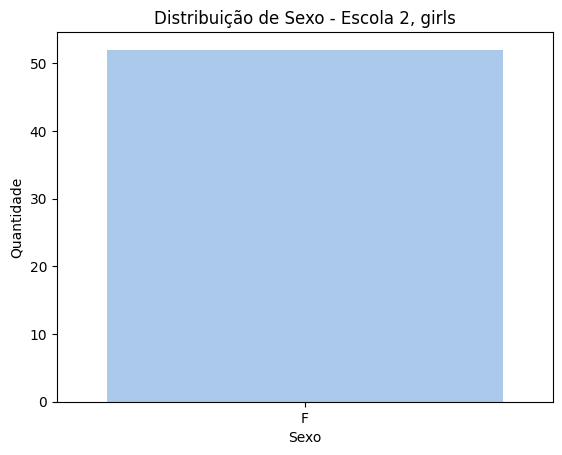

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


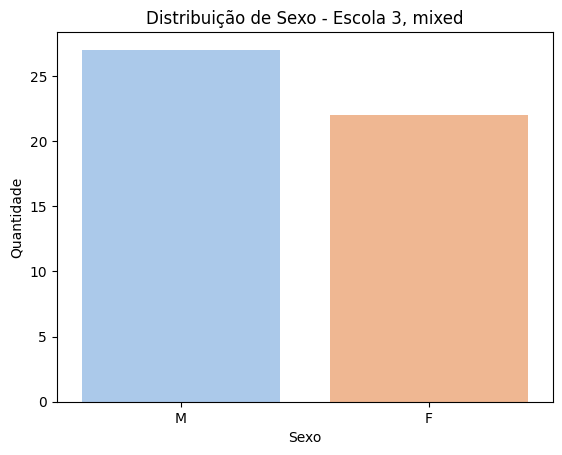

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


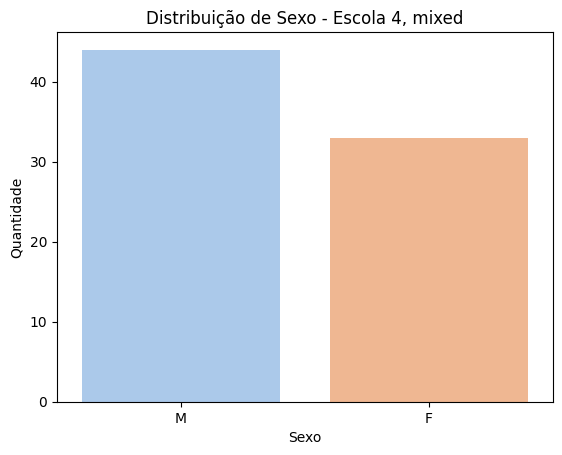

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


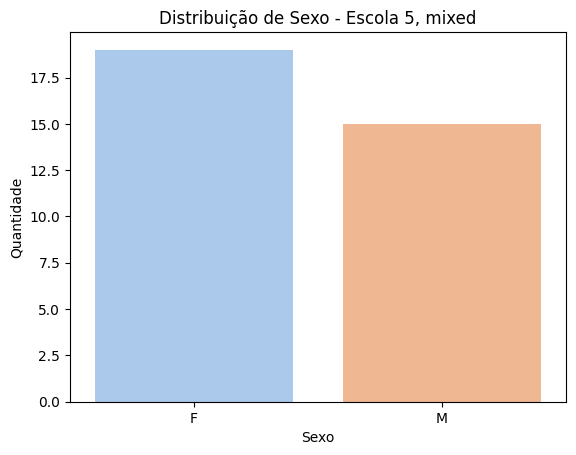

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


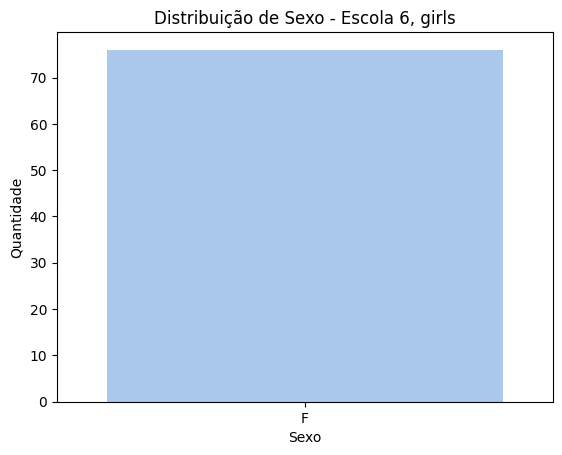

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


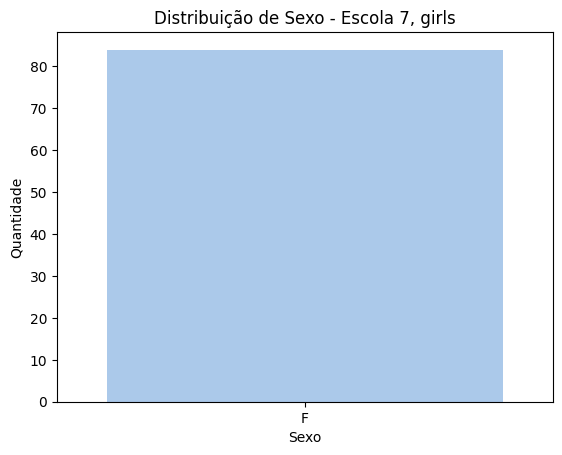

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


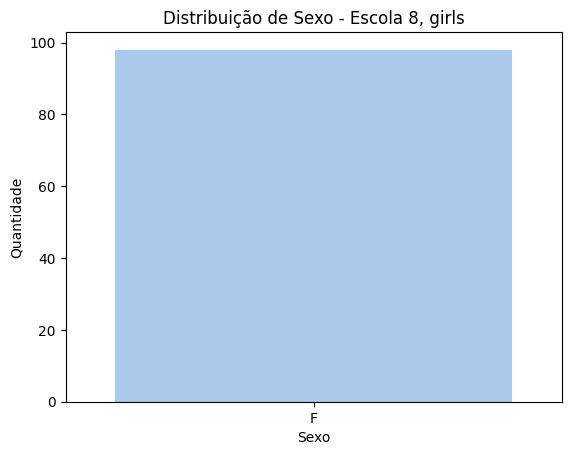

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


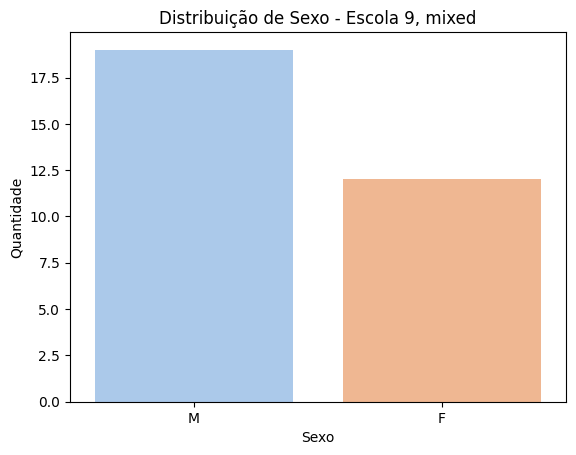

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


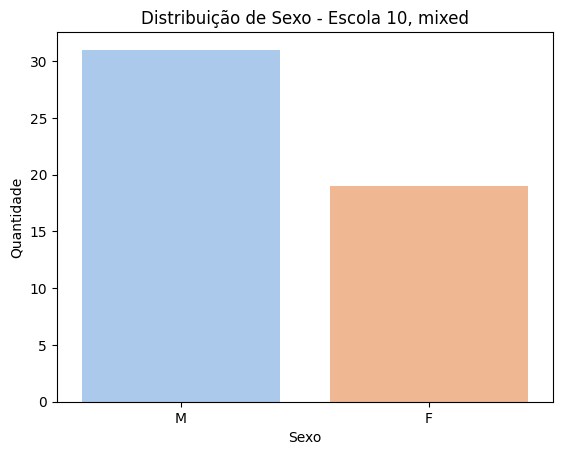

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


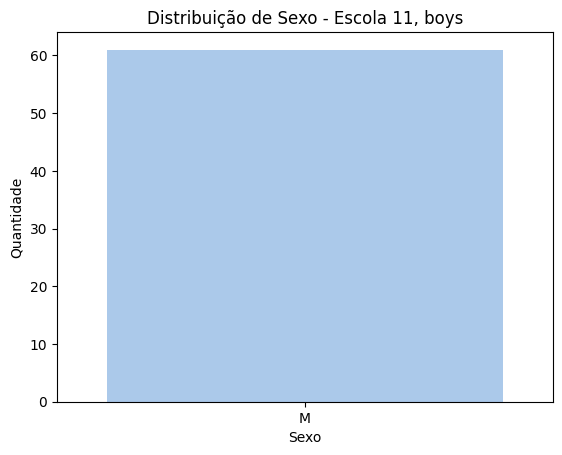

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


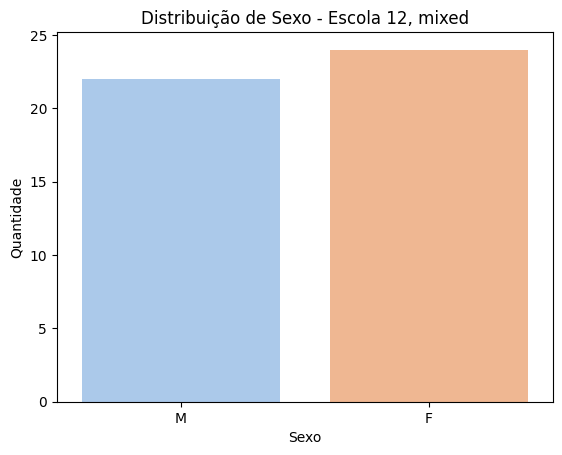

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


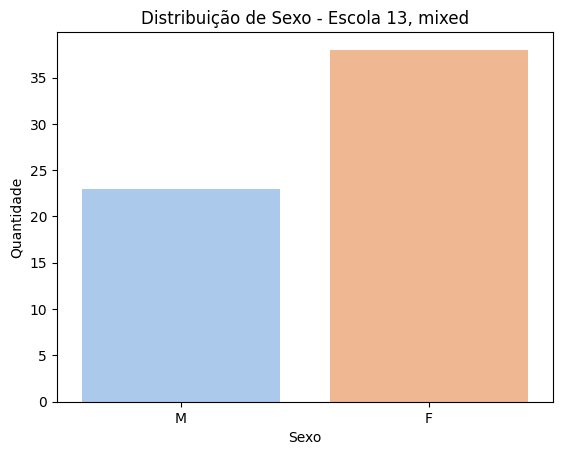

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


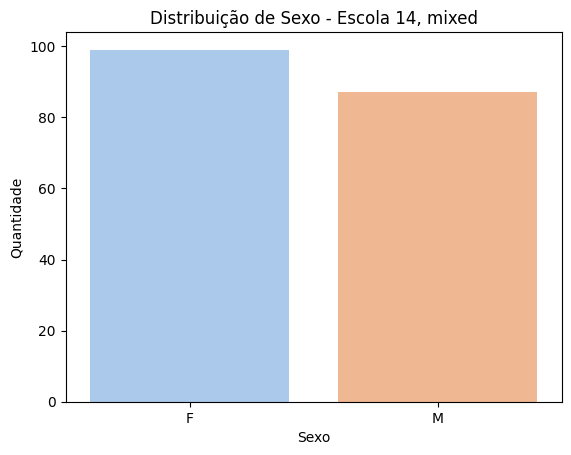

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


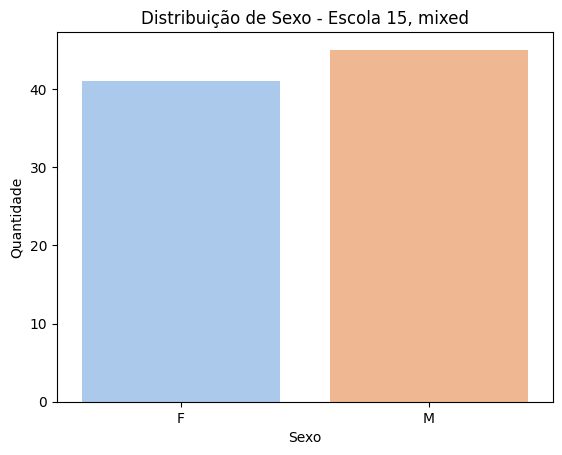

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


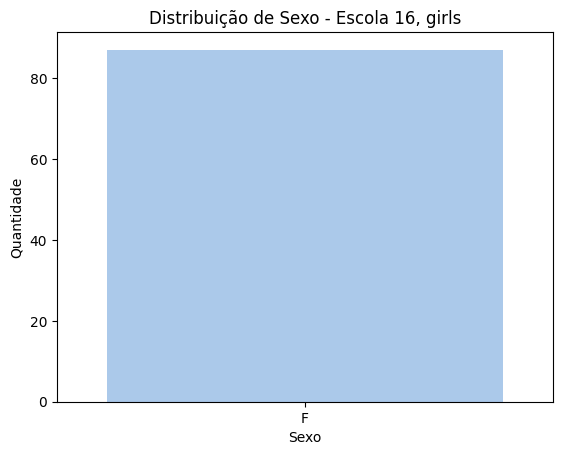

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


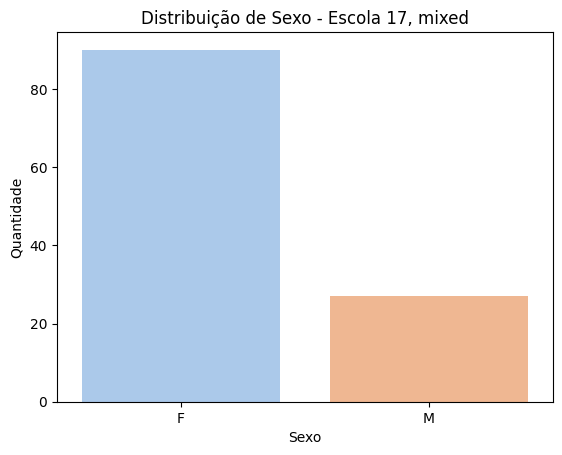

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


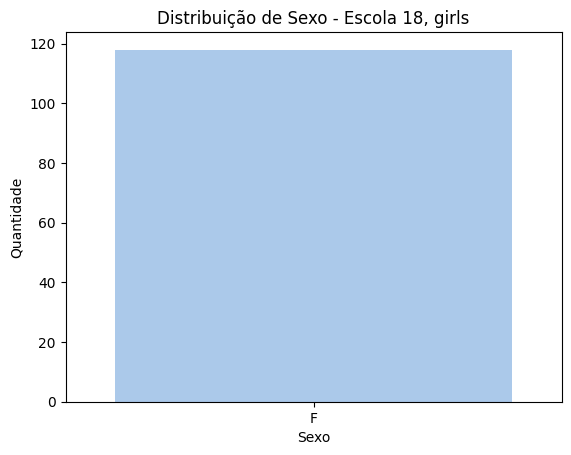

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


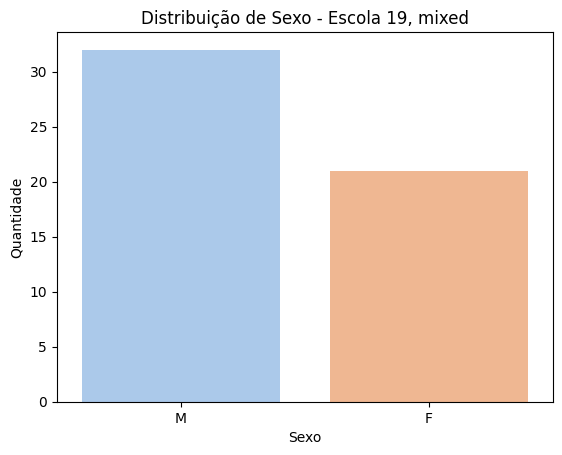

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


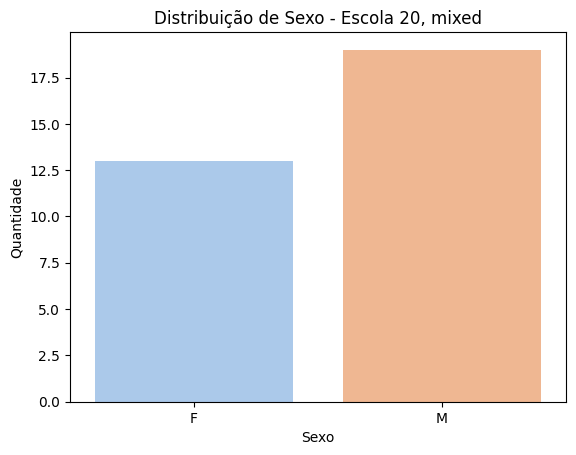

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


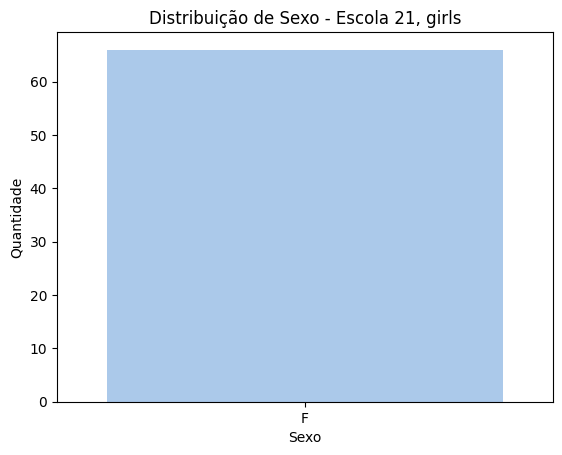

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


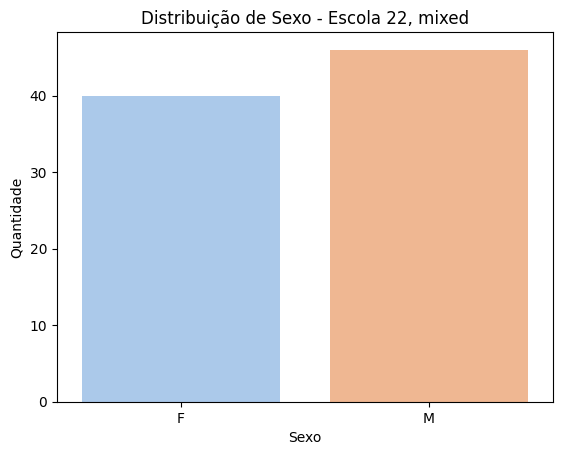

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


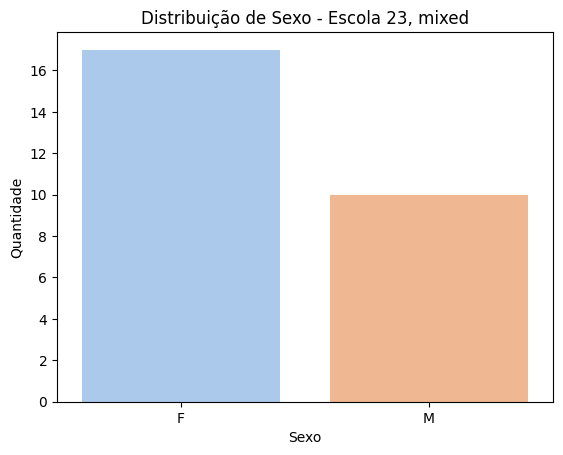

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


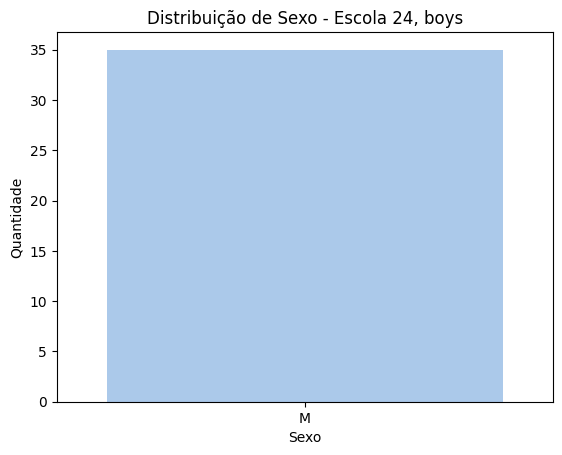

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


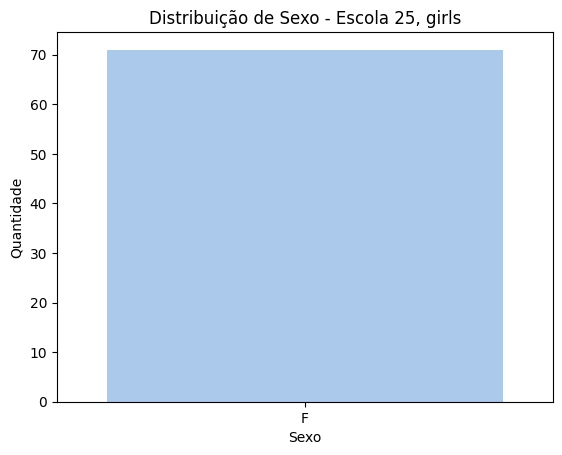

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


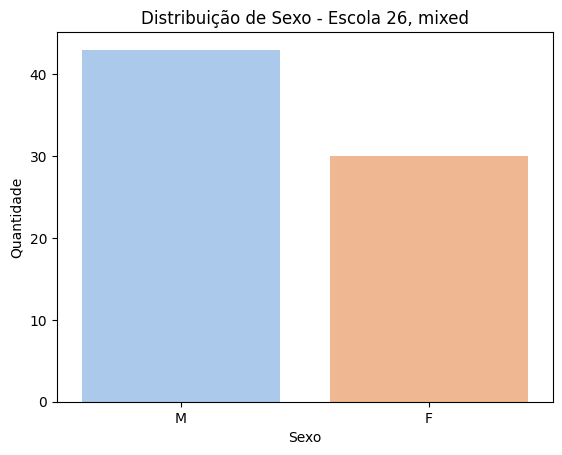

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


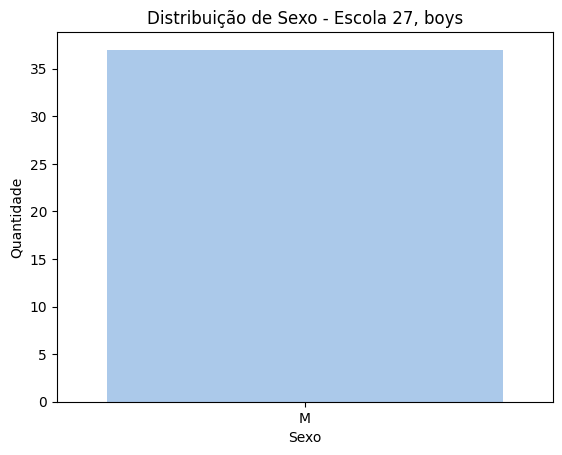

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


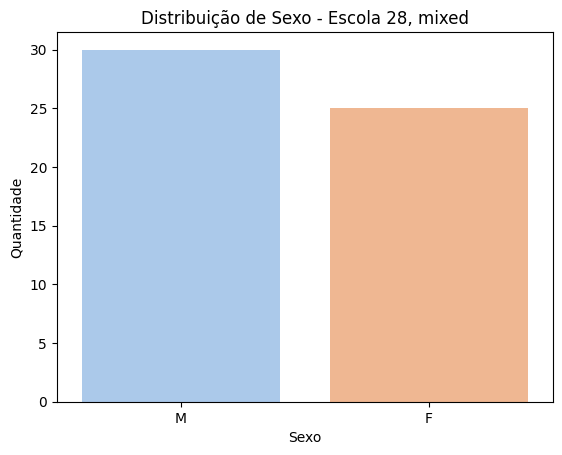

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


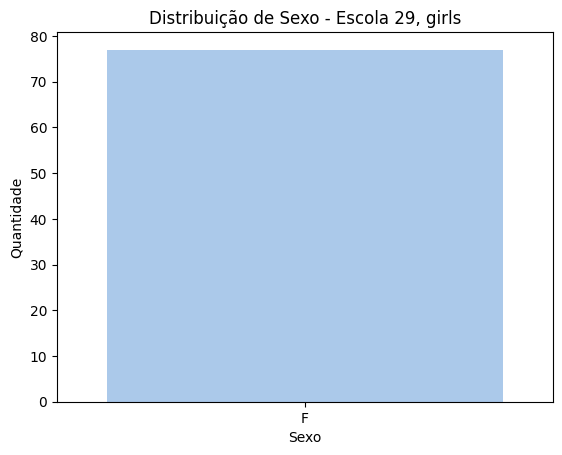

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


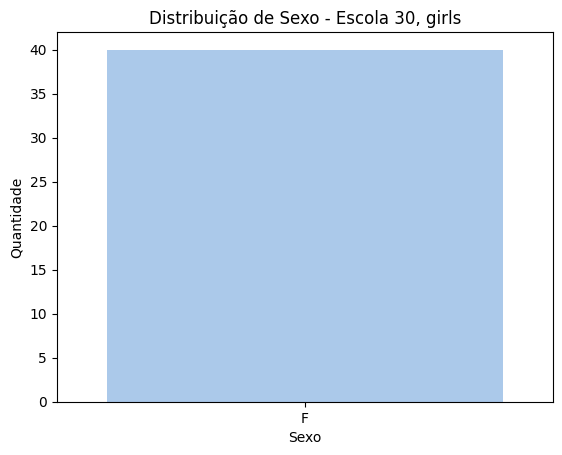

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


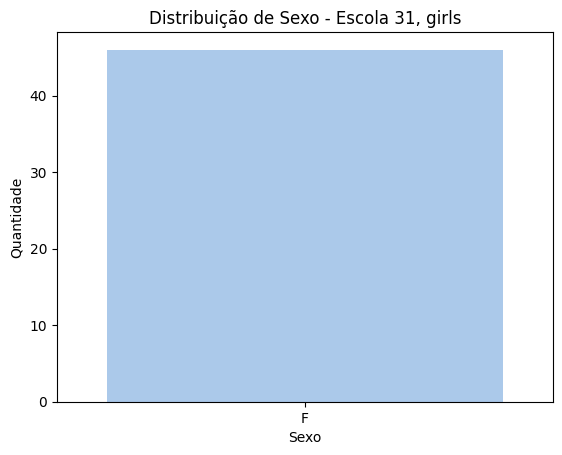

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


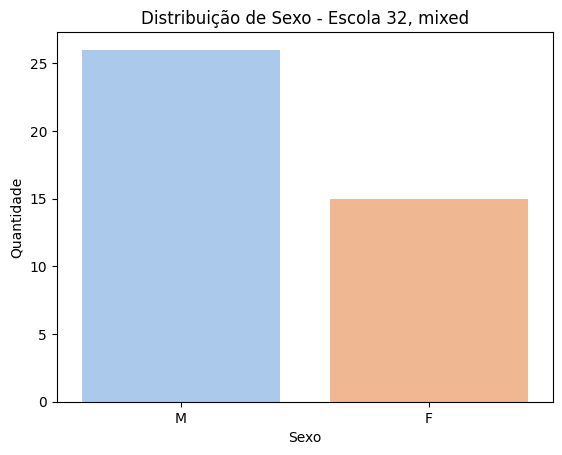

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


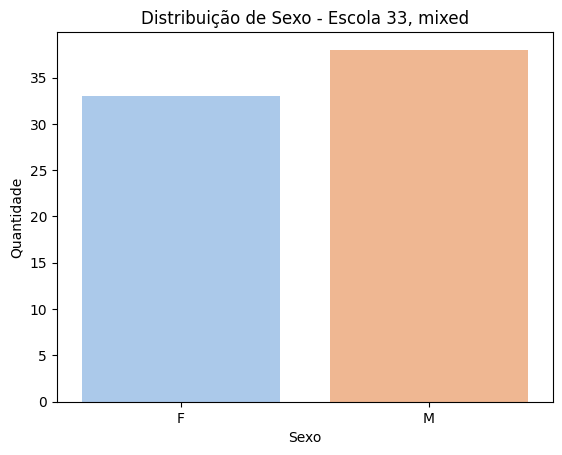

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


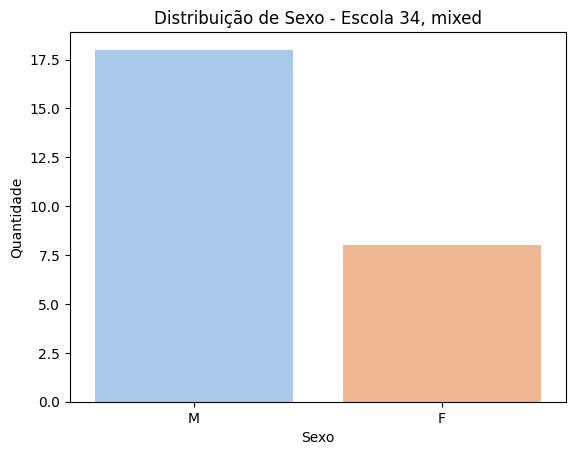

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


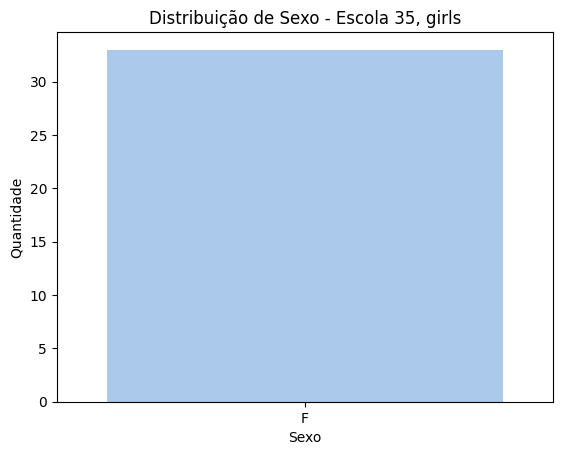

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


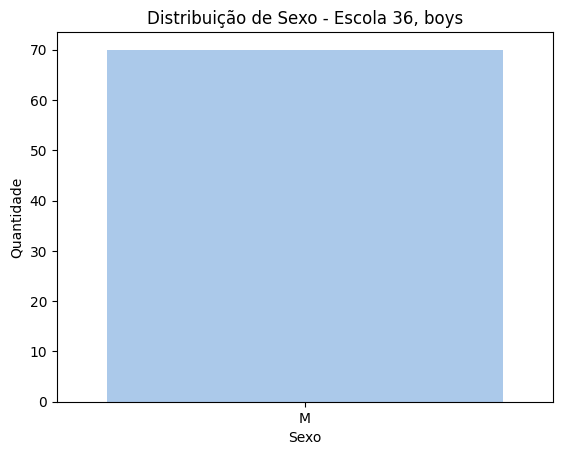

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


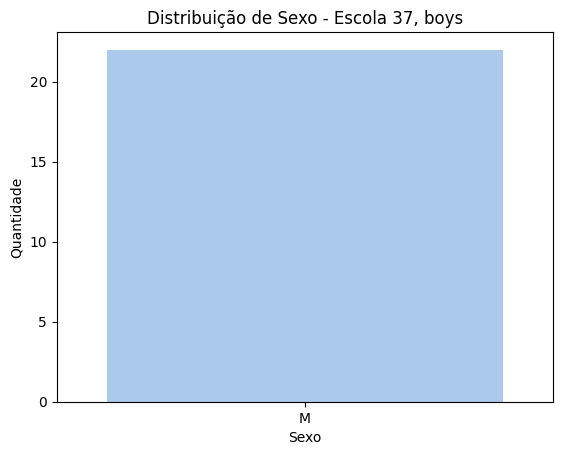

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


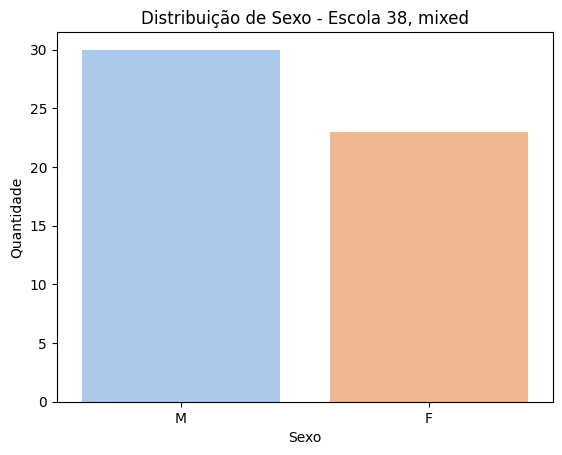

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


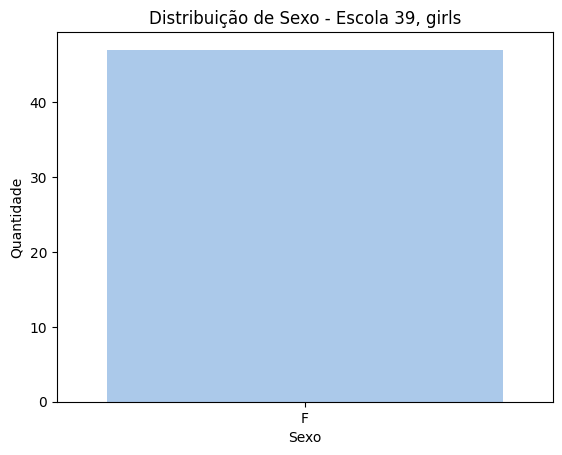

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


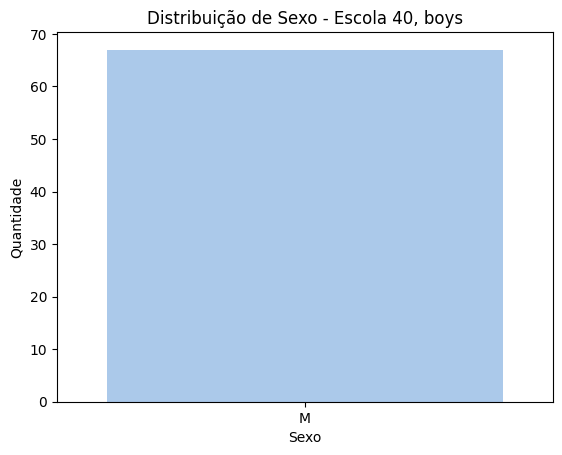

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


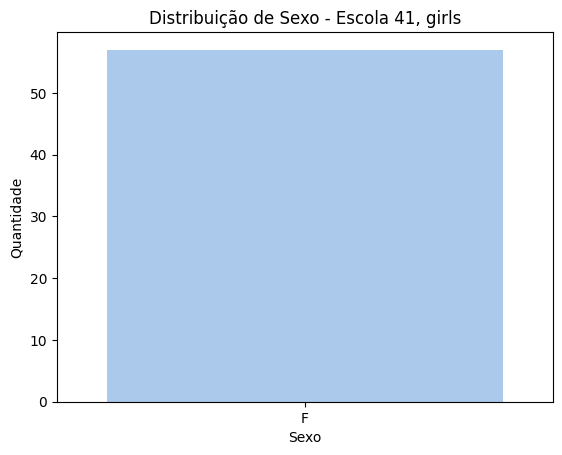

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


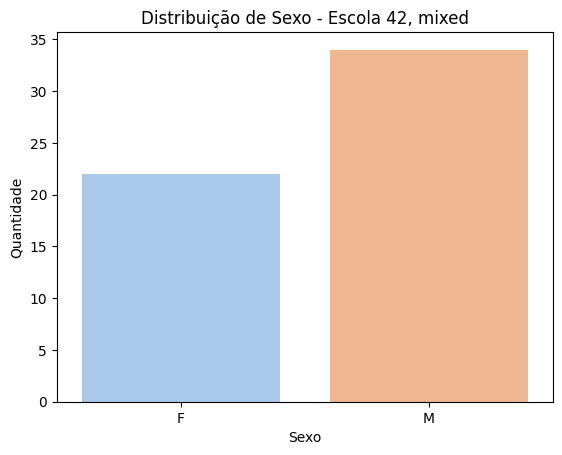

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


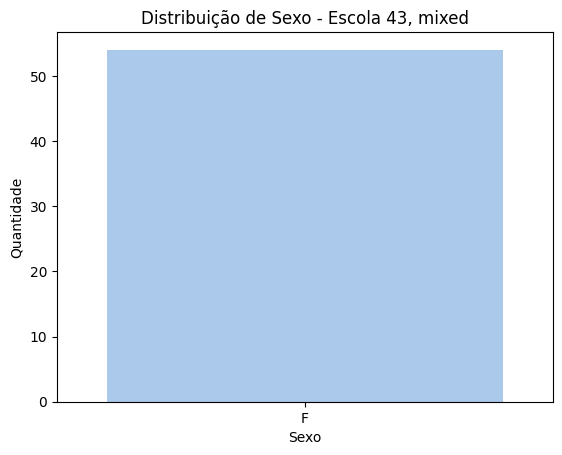

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


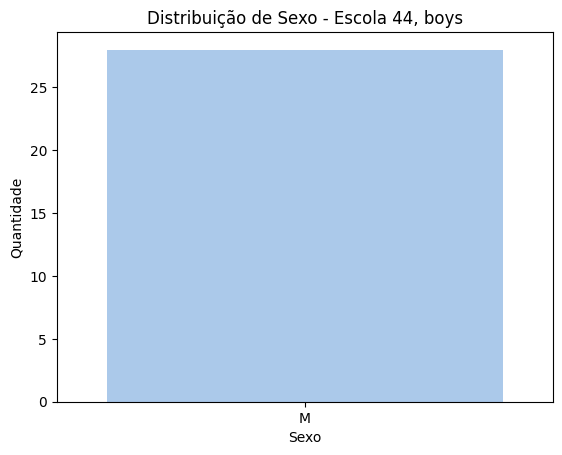

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


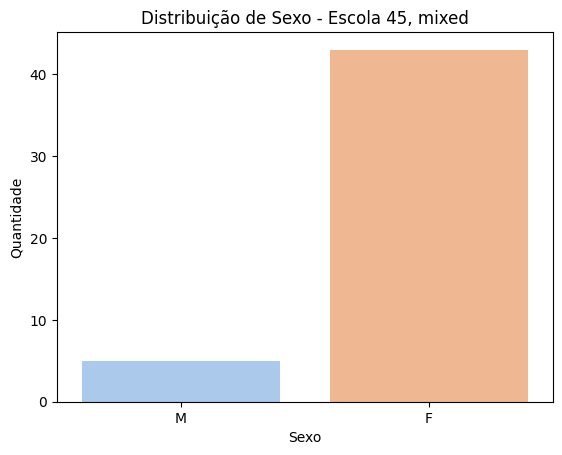

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


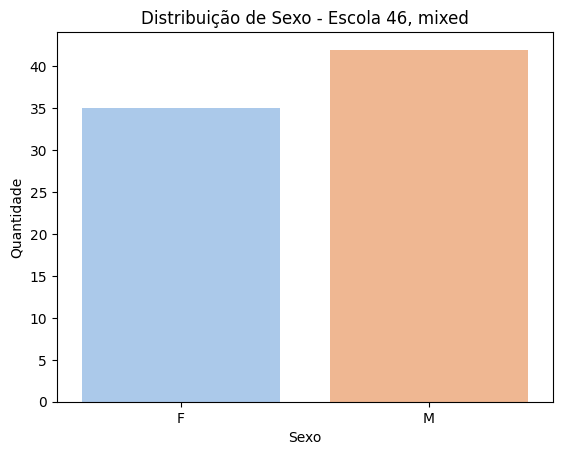

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


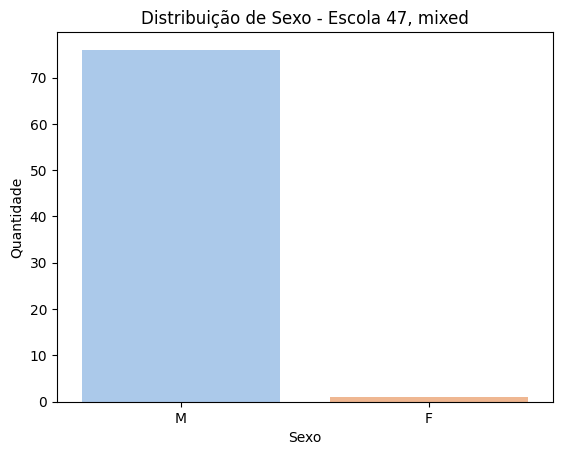

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


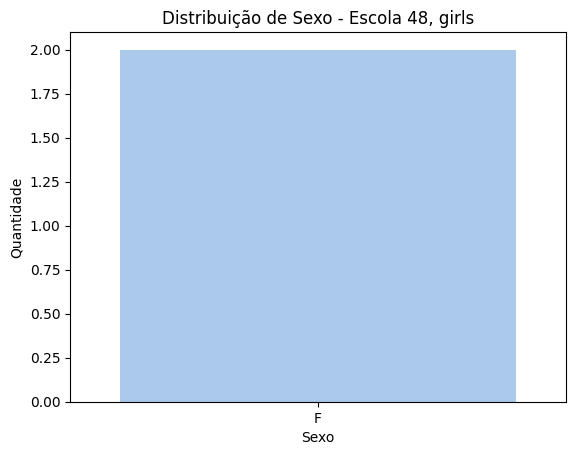

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


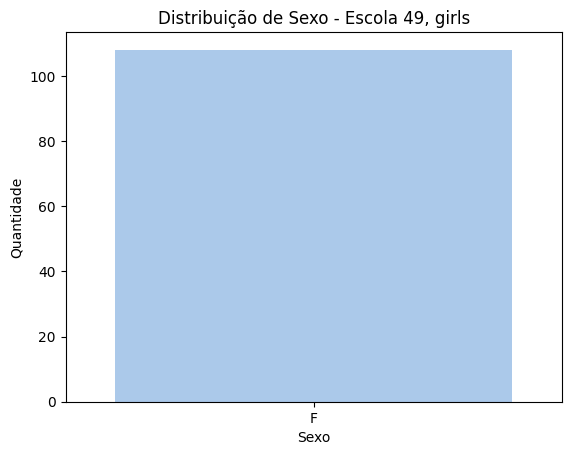

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


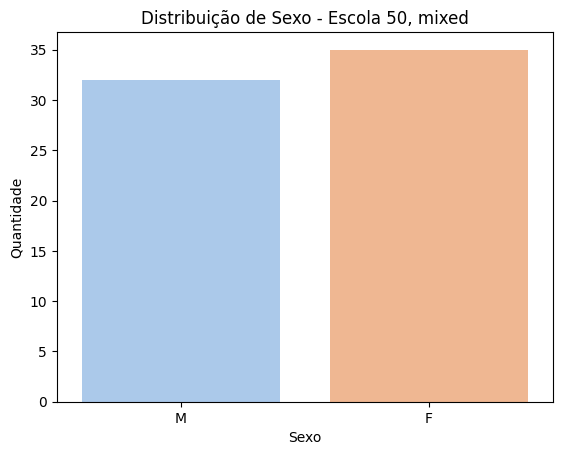

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


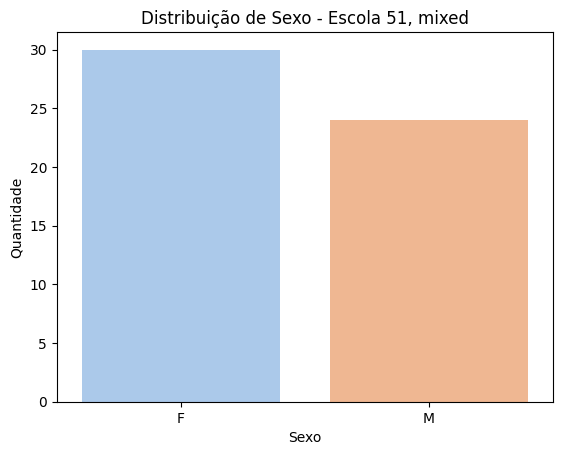

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


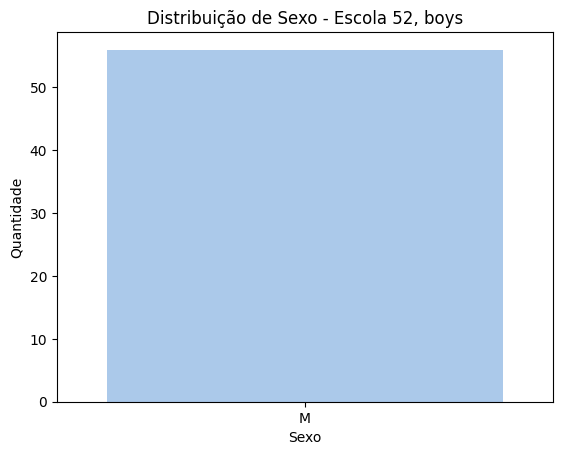

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


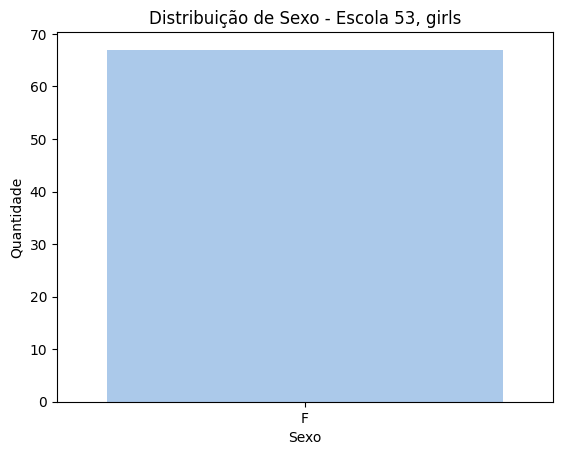

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


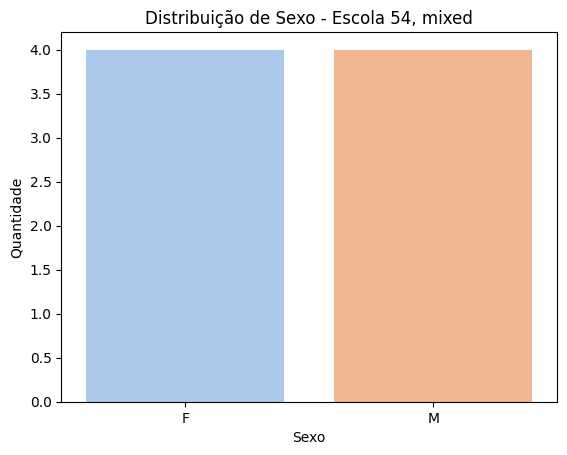

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


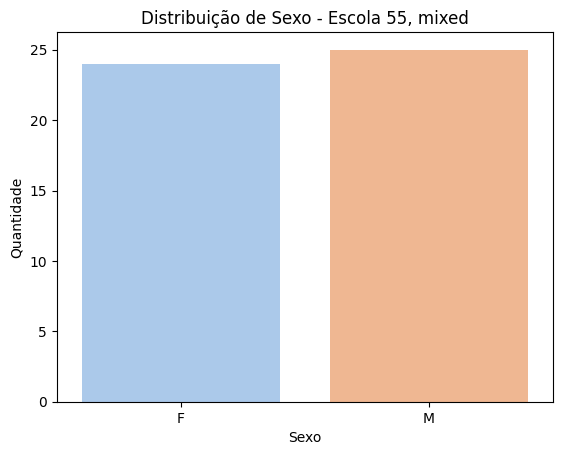

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


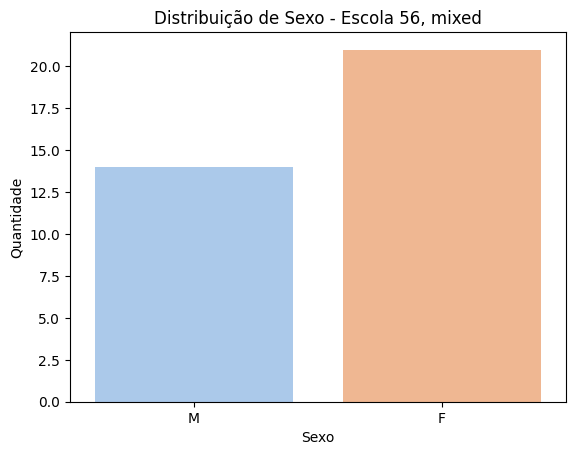

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


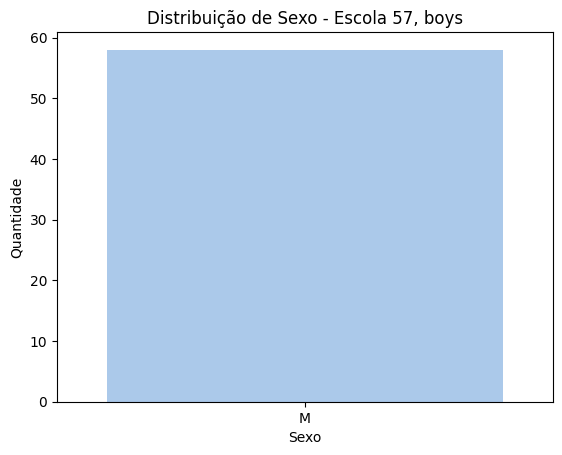

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


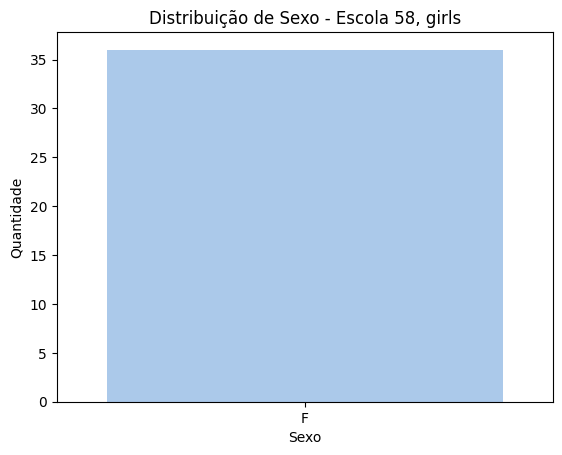

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


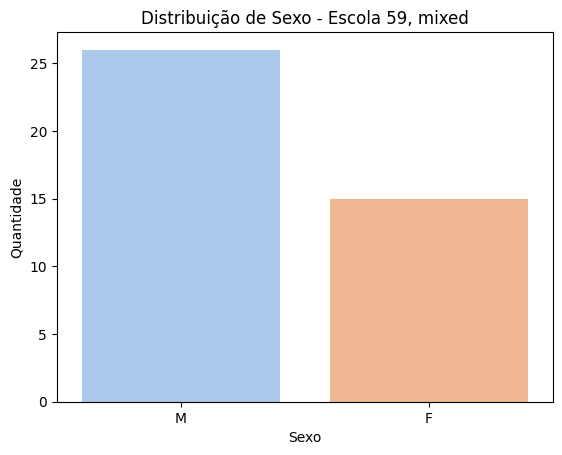

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


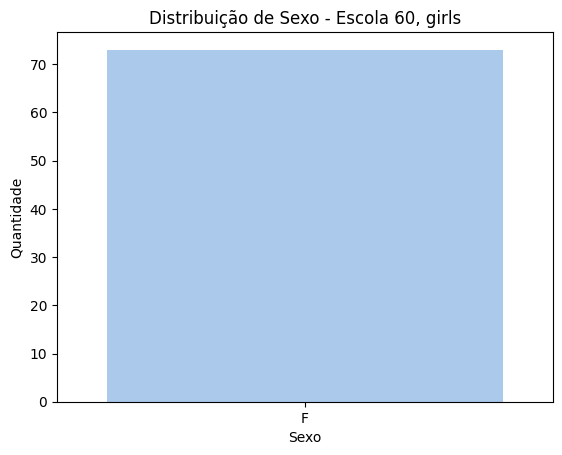

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


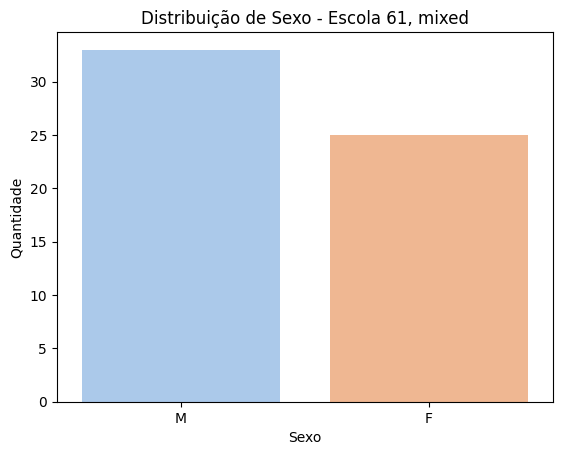

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


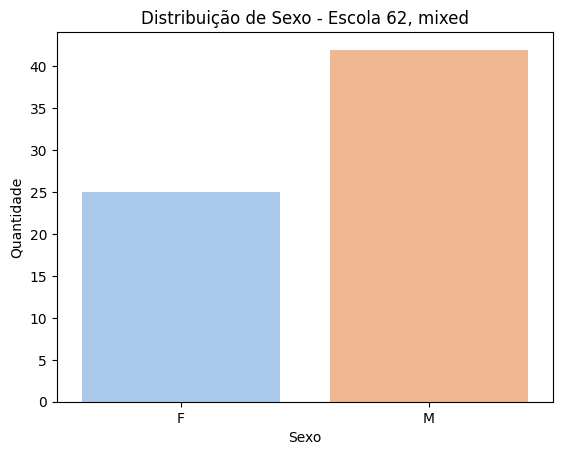

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


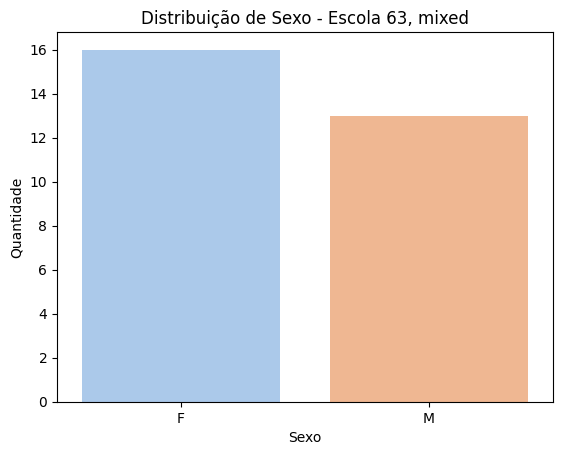

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


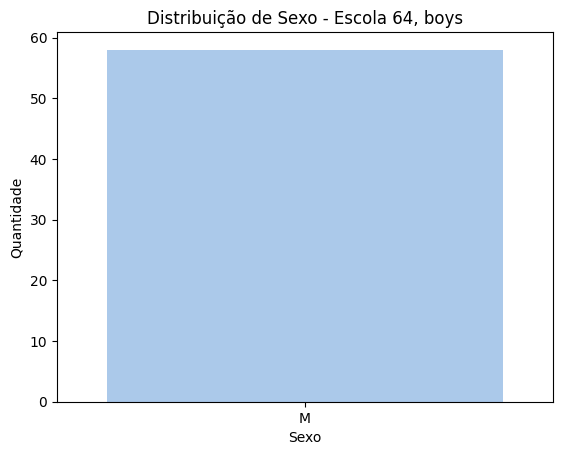

/tmp/ipython-input-2385928789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='sex', palette='pastel')


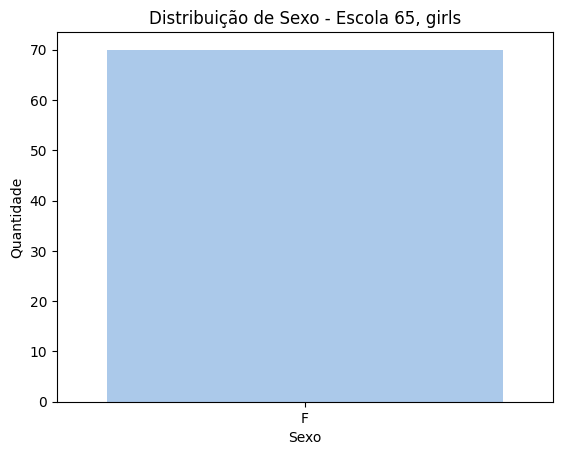

In [ ]:
# conferir distribuição de sexo
for school in df_school.index:
  student_school = df_student[df_student['school'] == school]
  school_schgend = df_school.loc[school, 'schgend']
  sns.countplot(student_school, x='sex', palette='pastel')
  plt.title(f'Distribuição de Sexo - Escola {school}, {school_schgend}')
  plt.xlabel('Sexo')
  plt.ylabel('Quantidade')
  plt.show()


/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


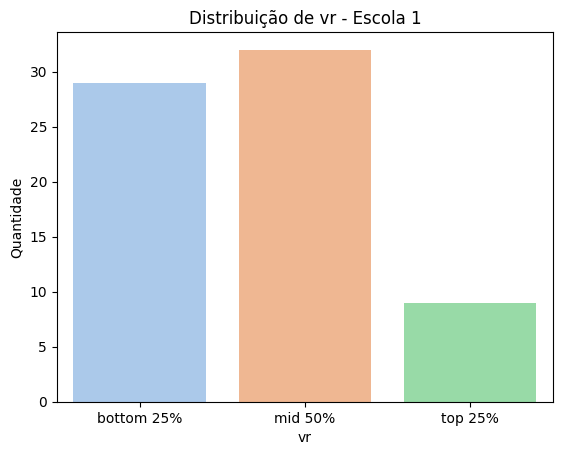

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


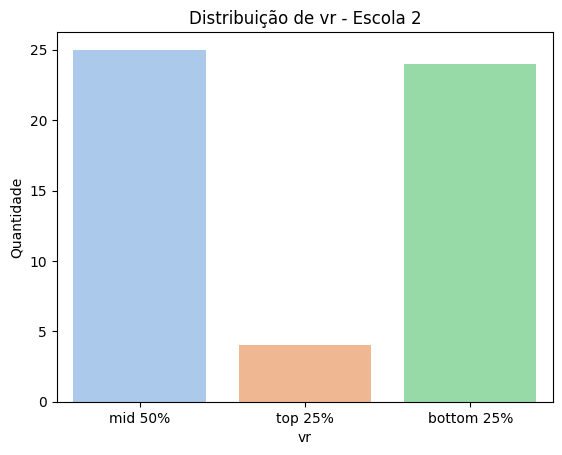

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


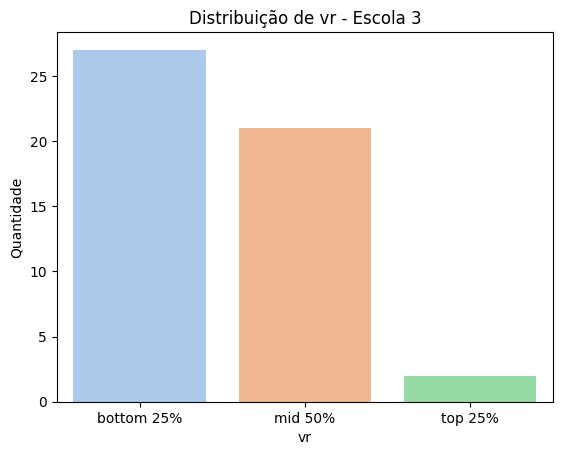

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


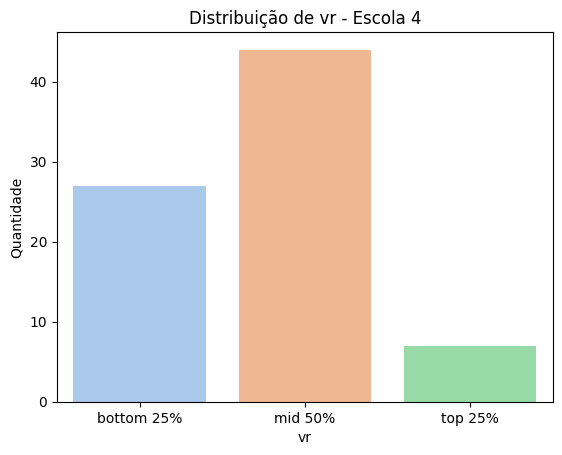

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


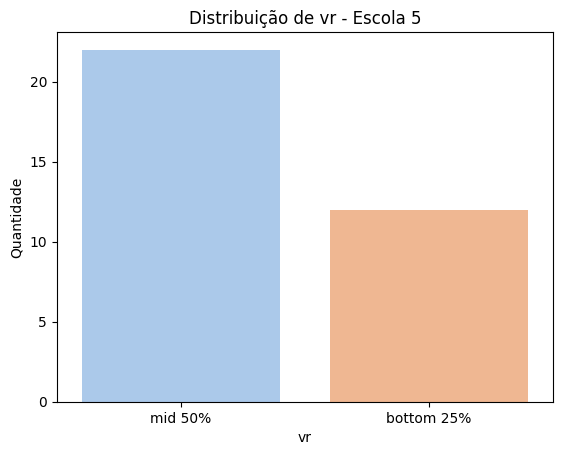

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


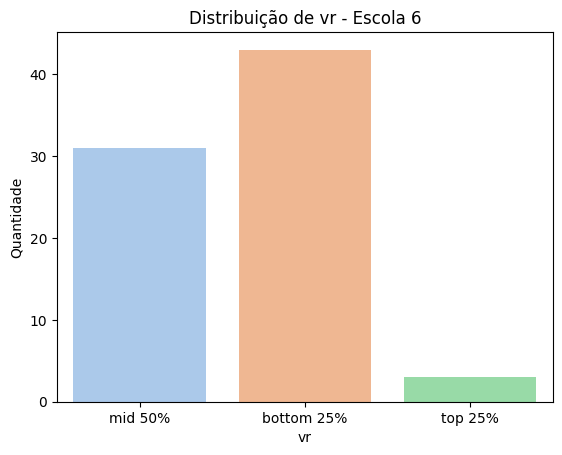

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


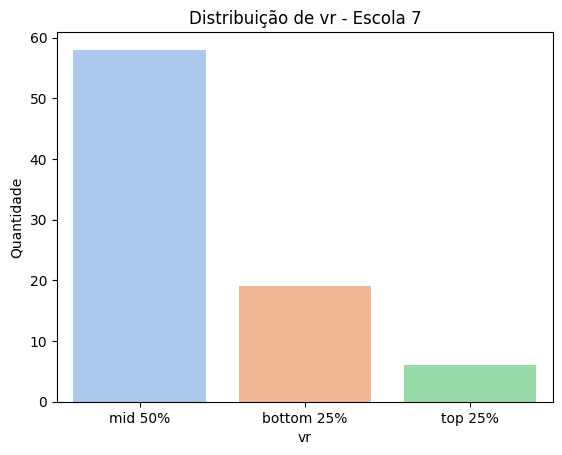

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


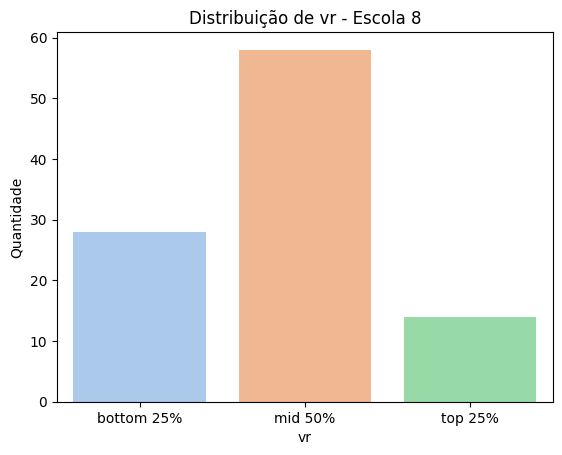

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


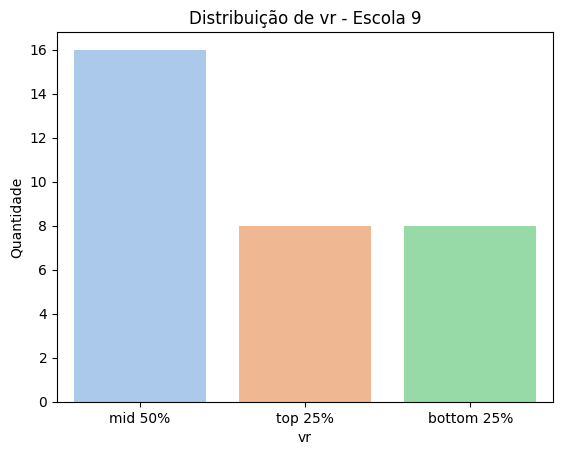

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


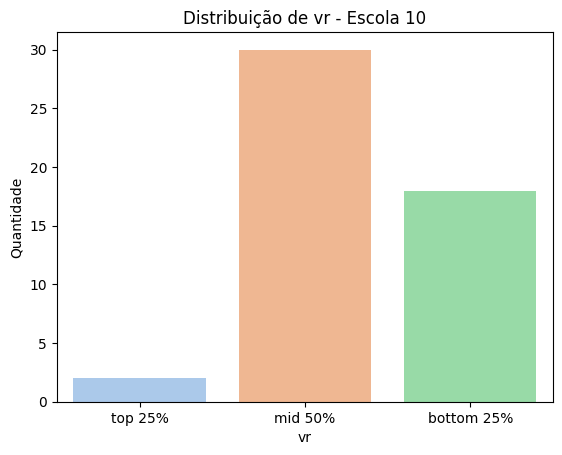

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


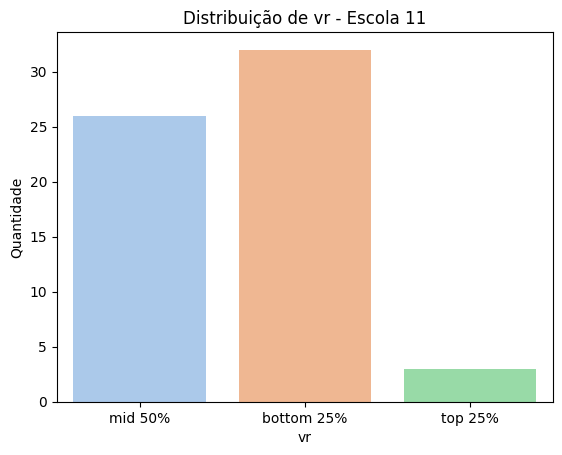

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


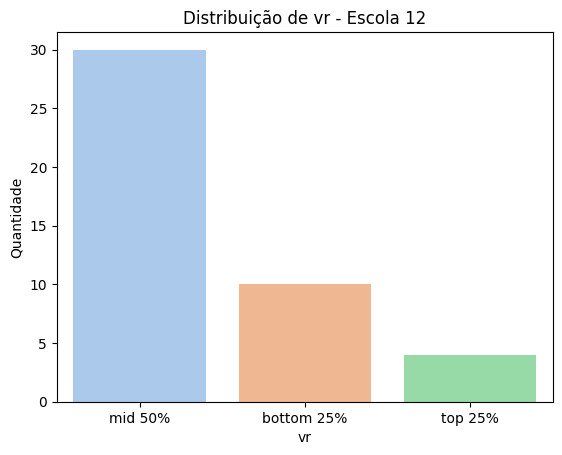

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


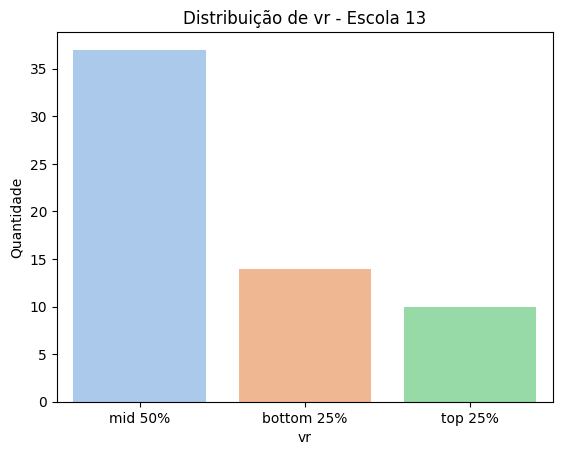

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


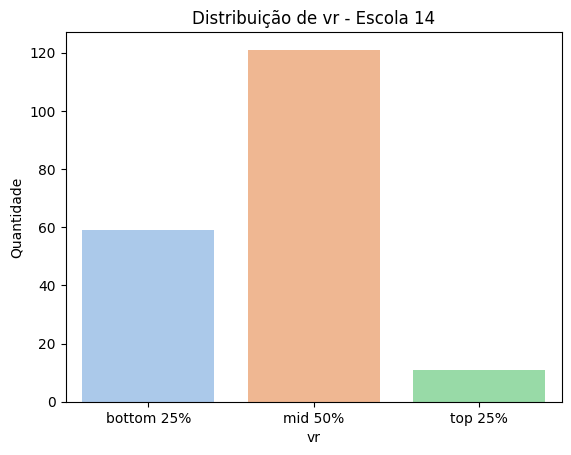

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


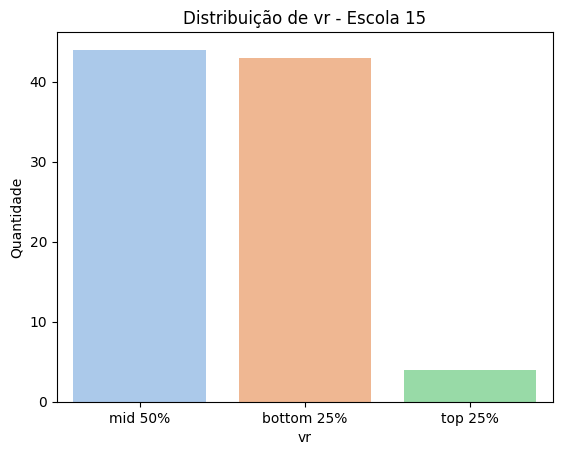

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


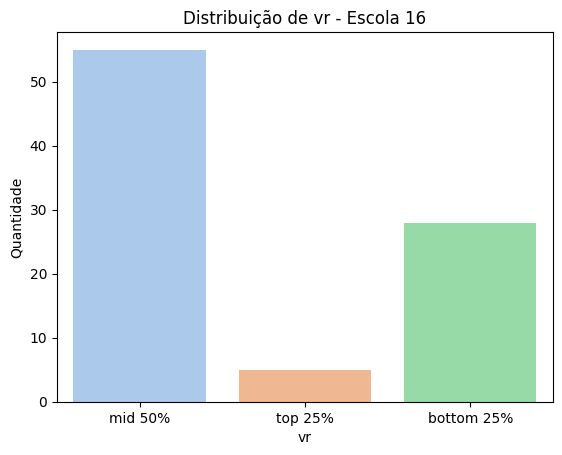

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


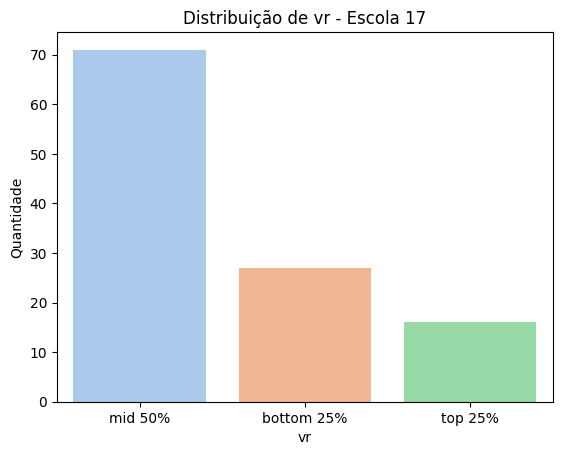

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


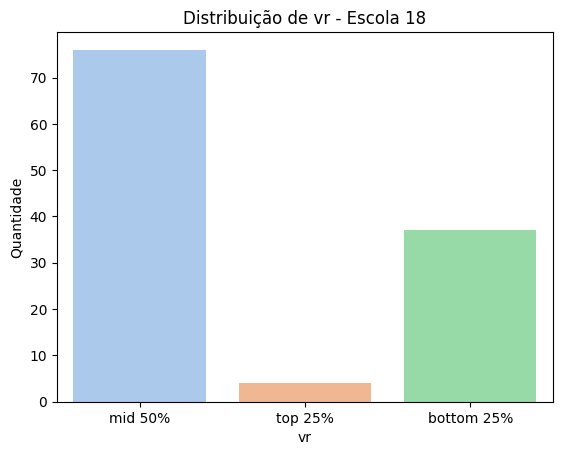

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


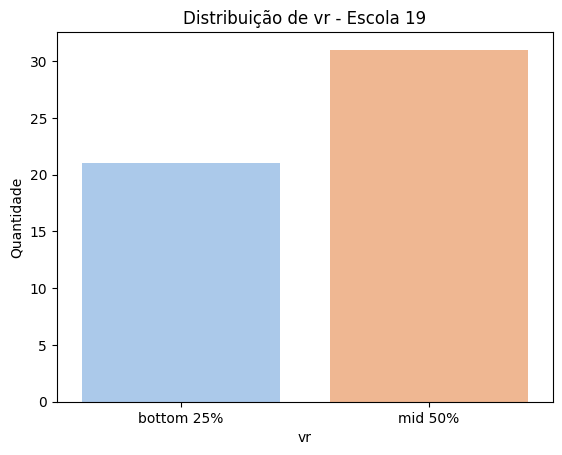

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


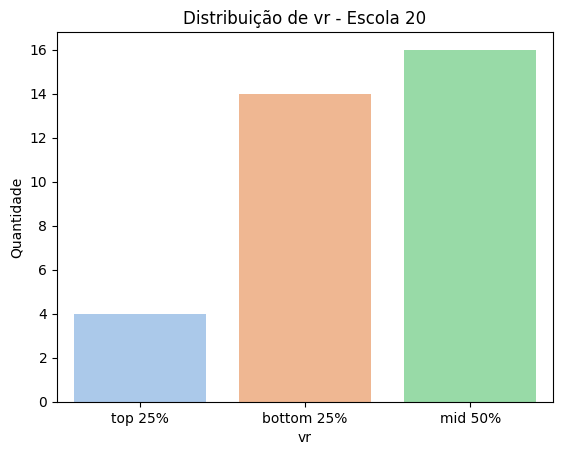

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


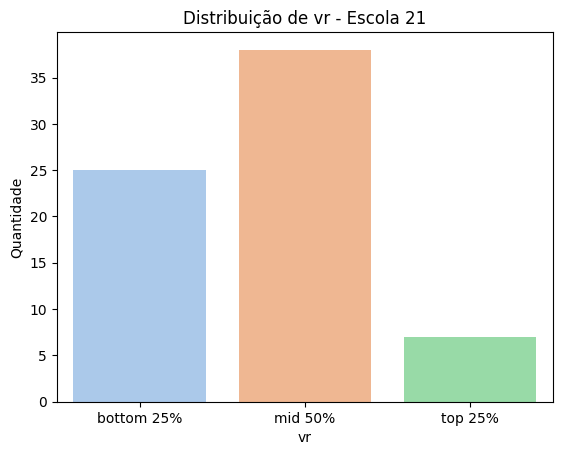

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


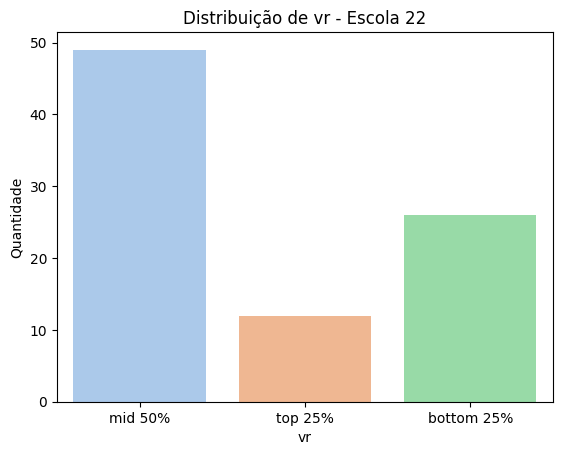

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


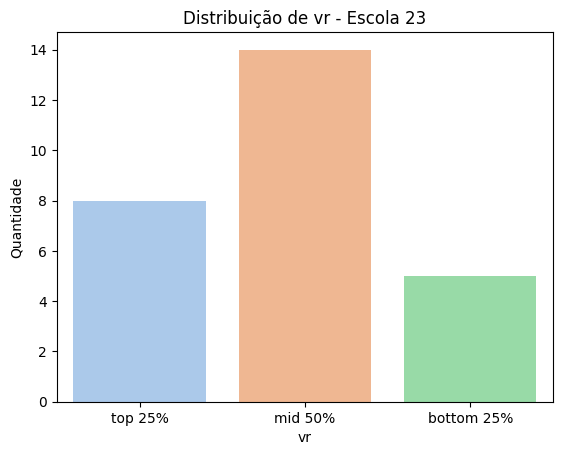

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


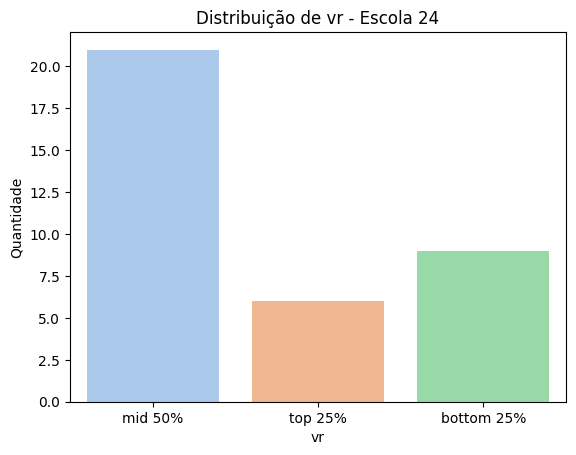

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


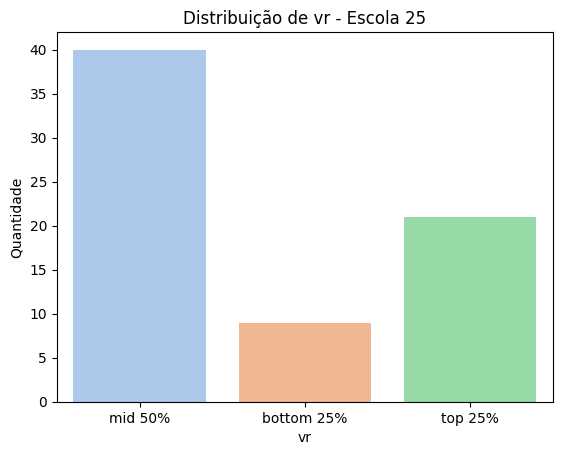

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


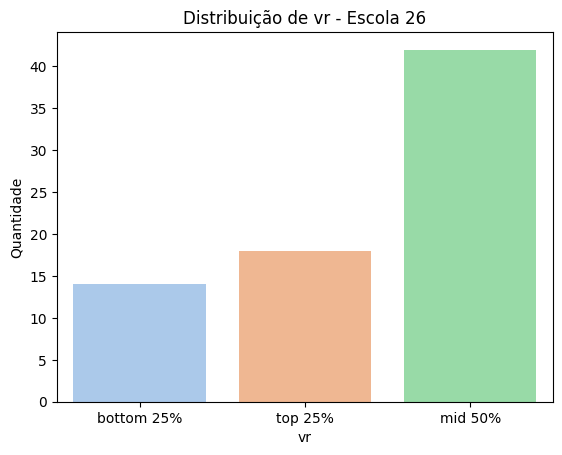

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


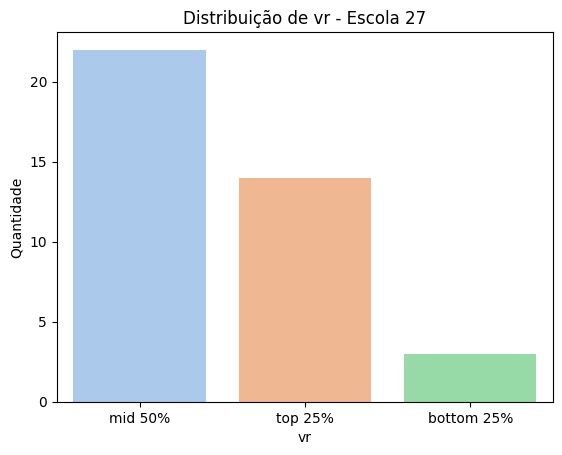

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


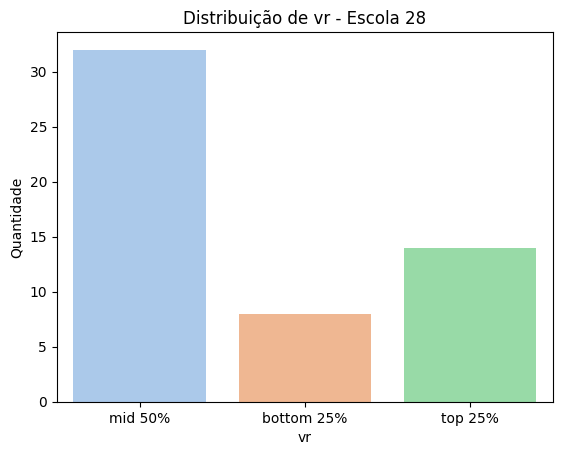

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


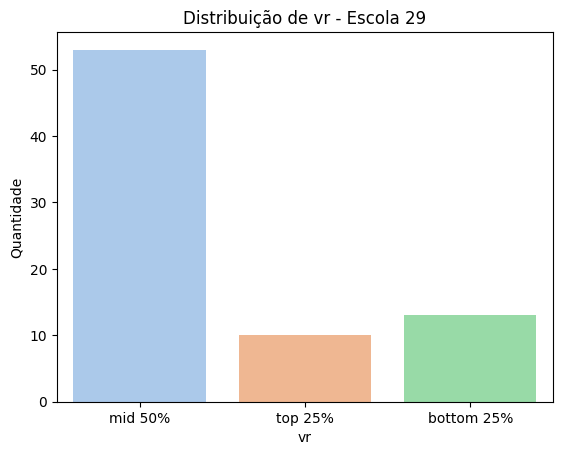

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


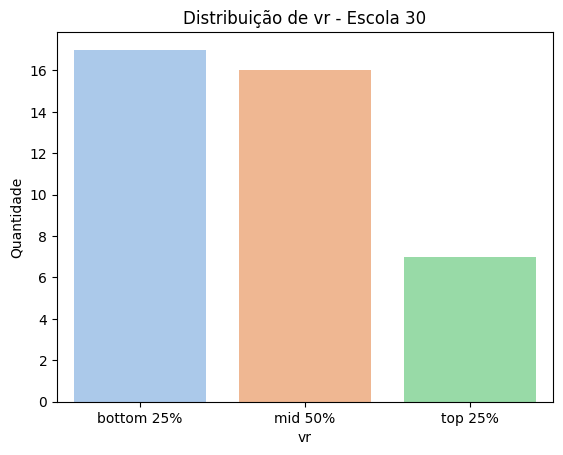

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


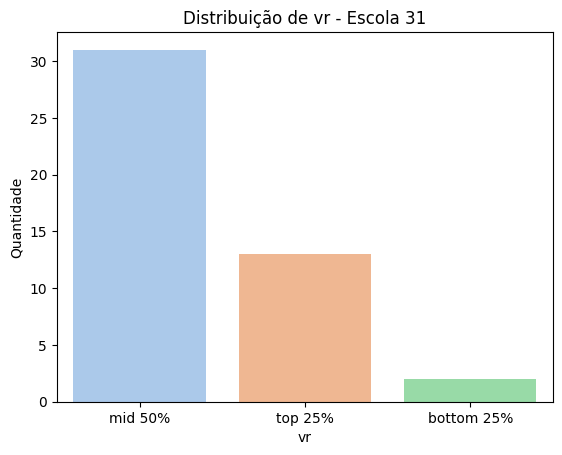

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


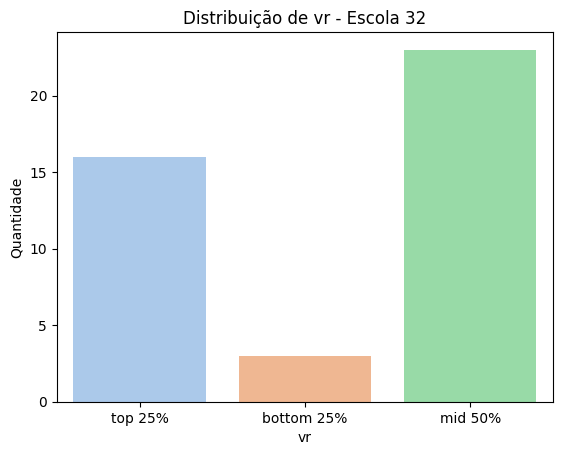

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


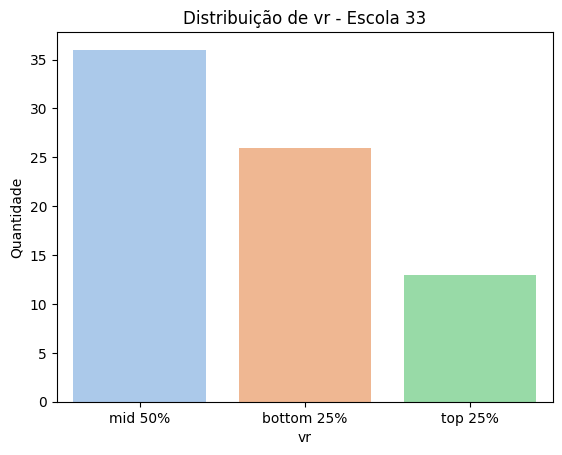

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


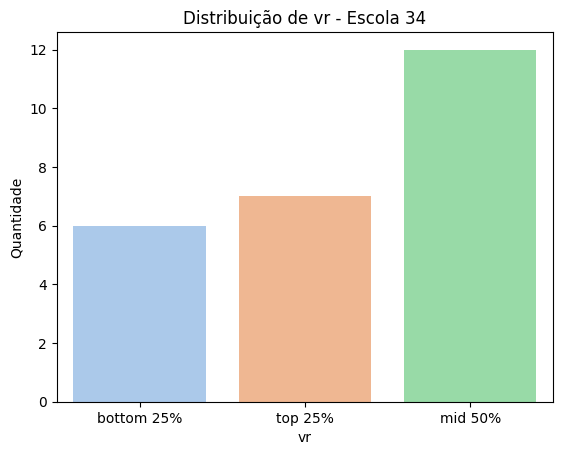

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


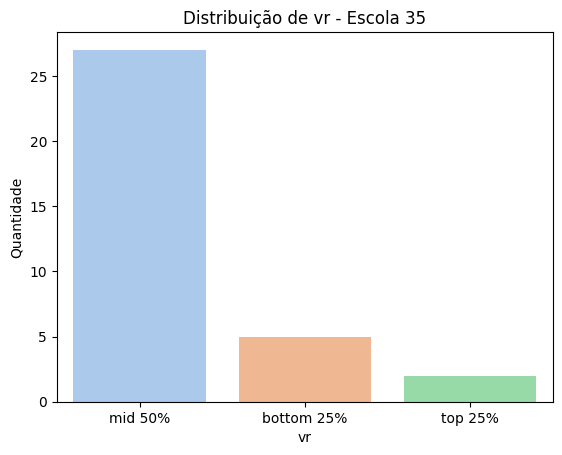

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


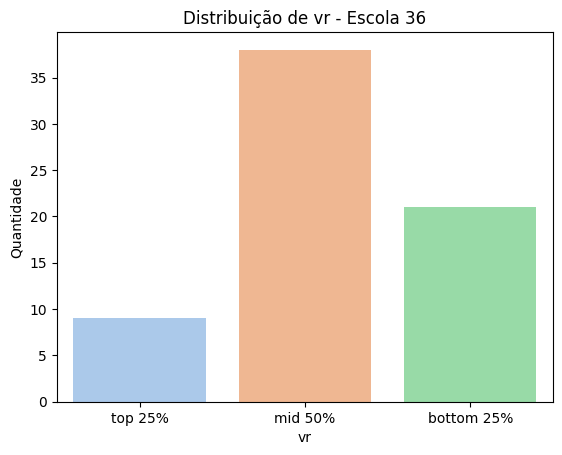

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


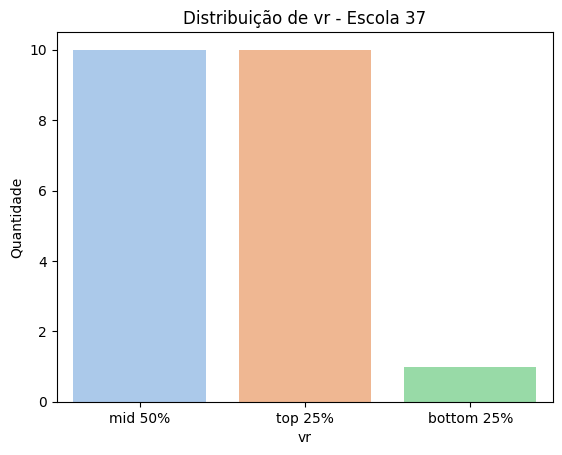

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


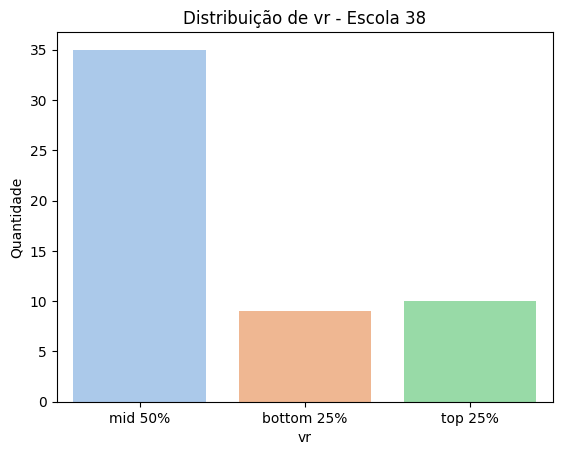

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


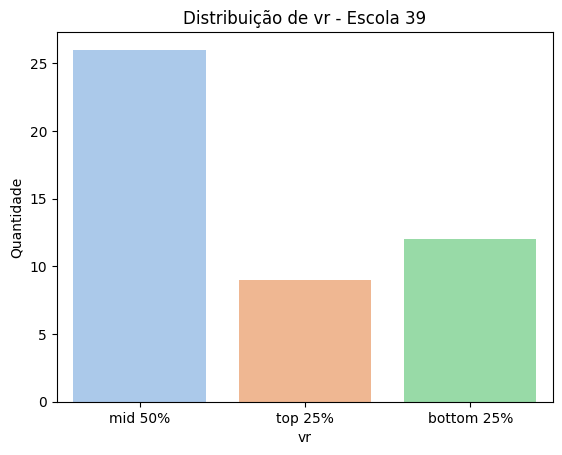

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


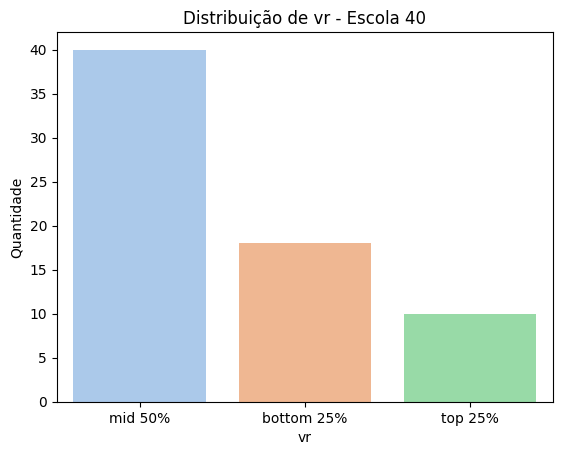

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


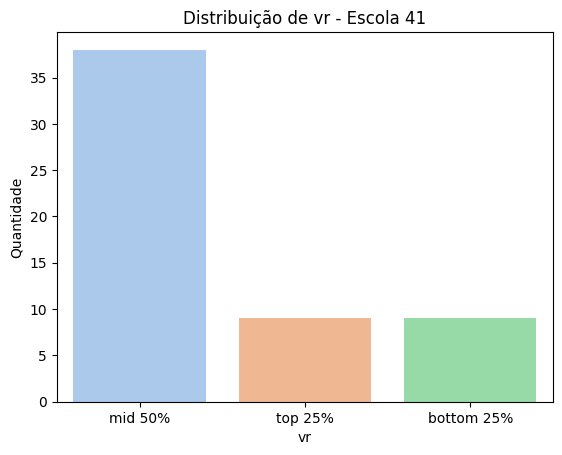

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


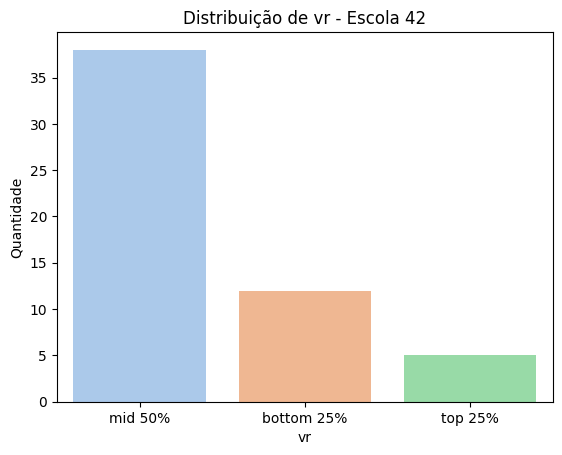

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


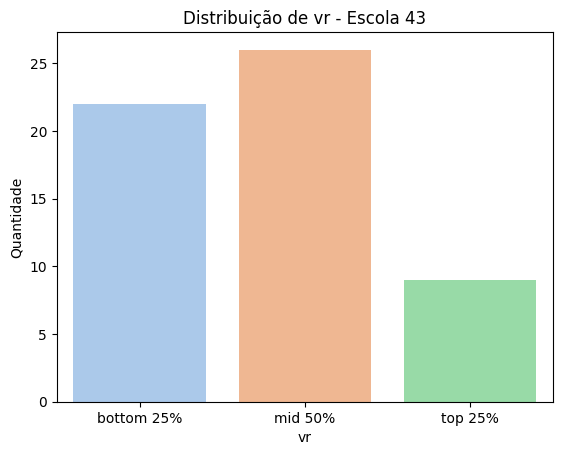

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


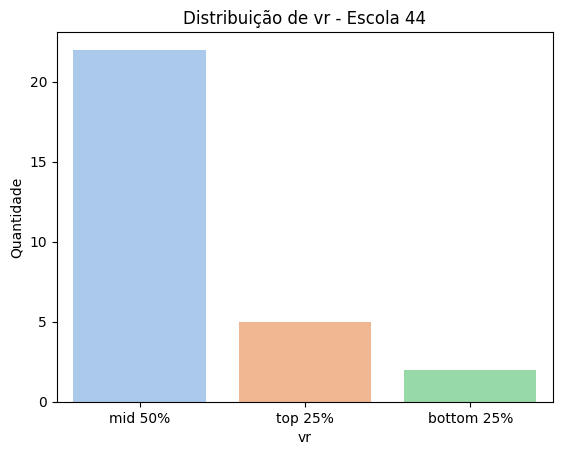

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


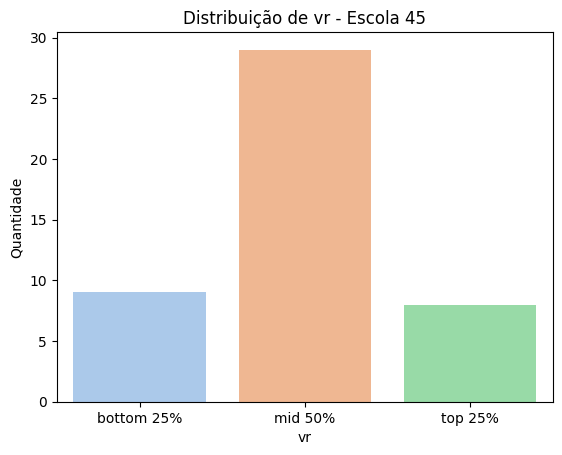

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


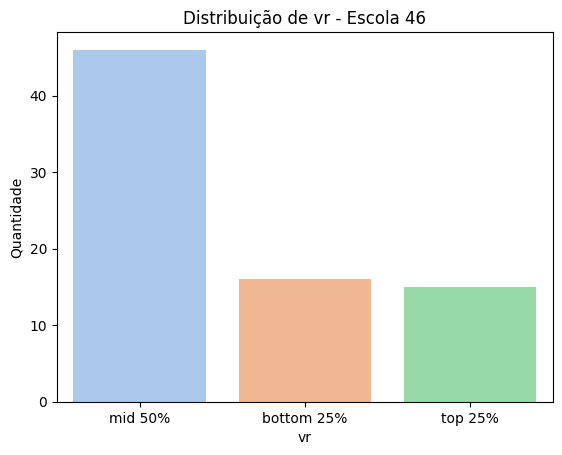

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


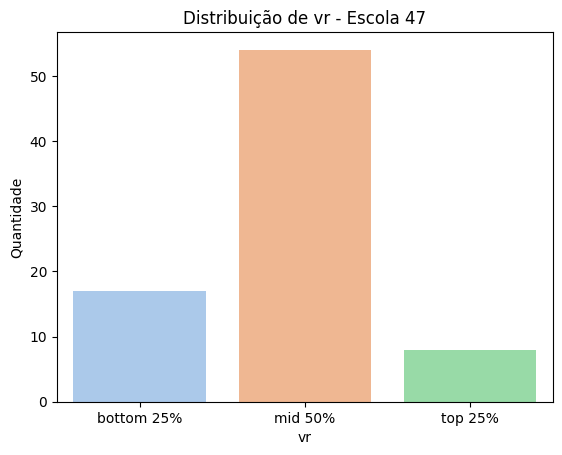

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


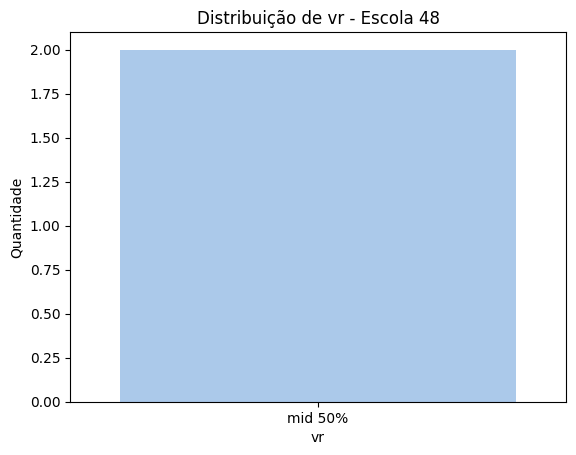

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


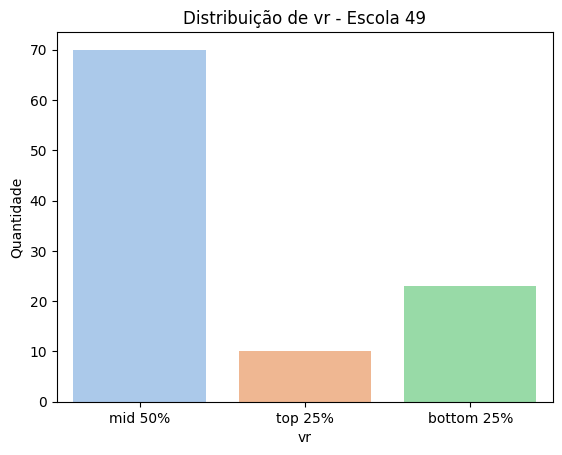

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


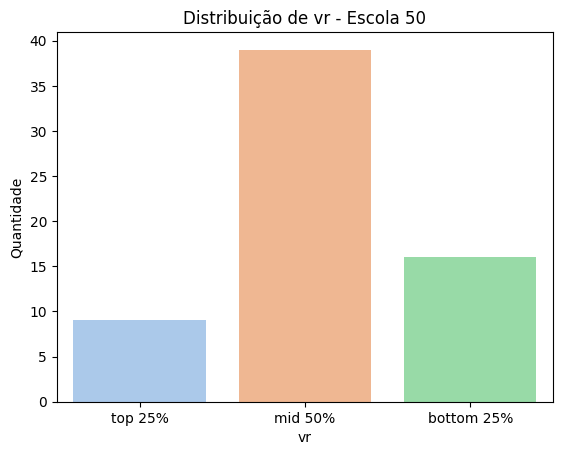

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


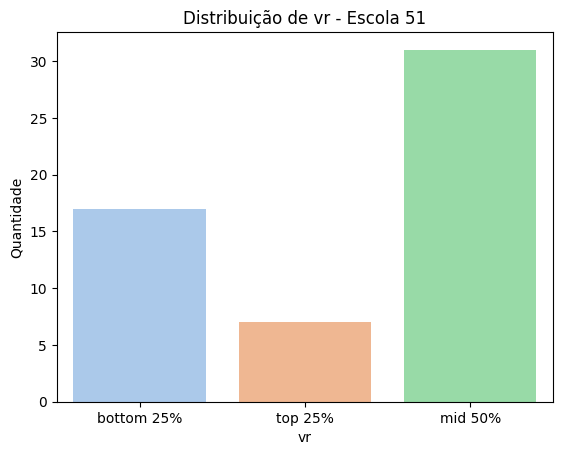

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


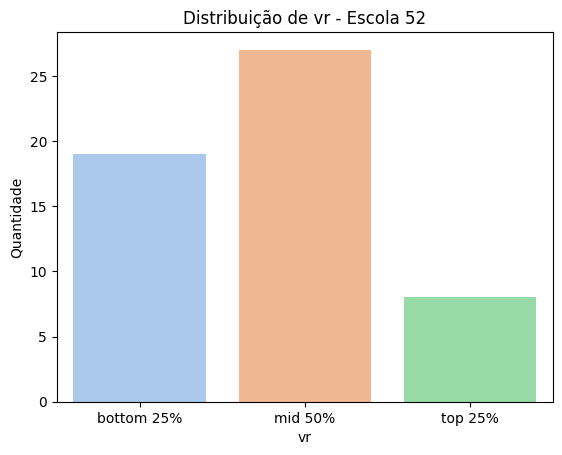

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


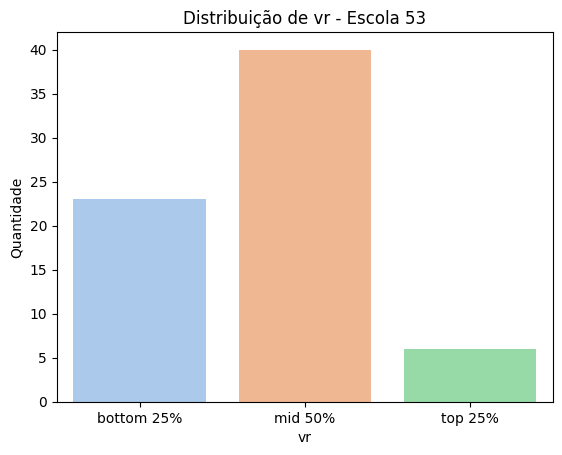

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


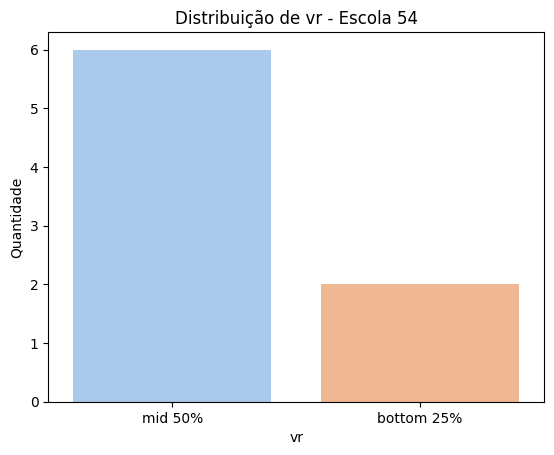

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


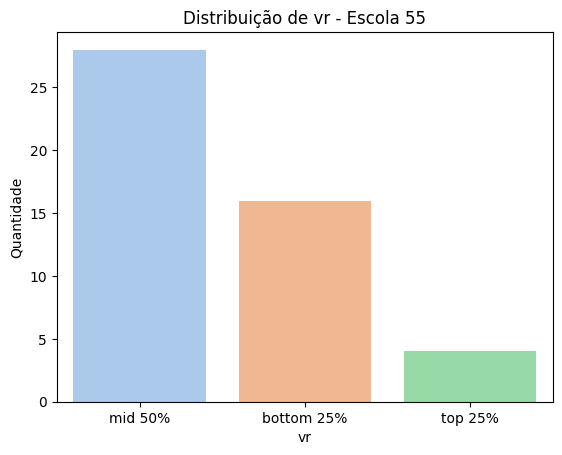

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


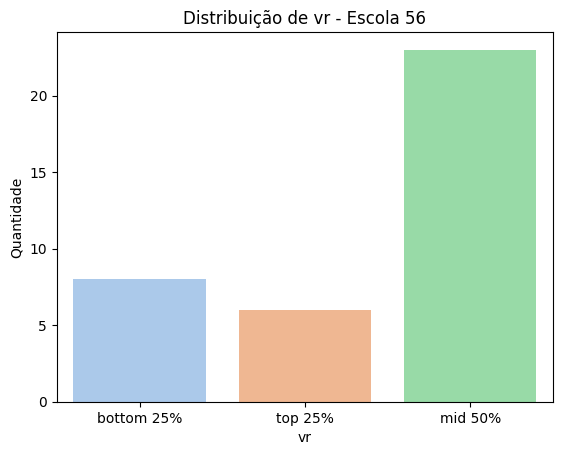

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


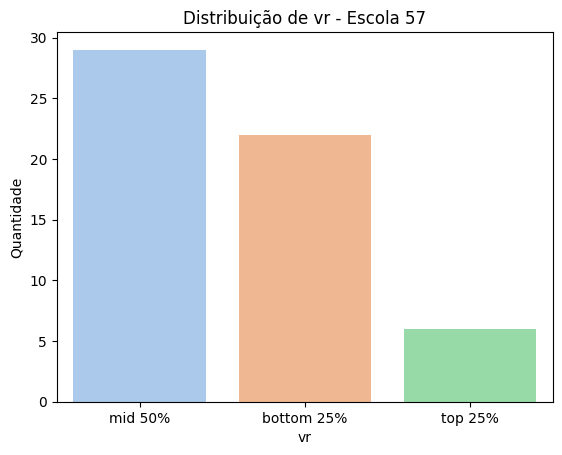

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


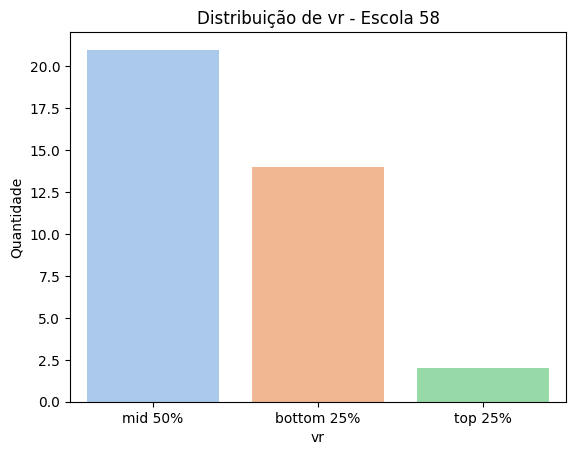

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


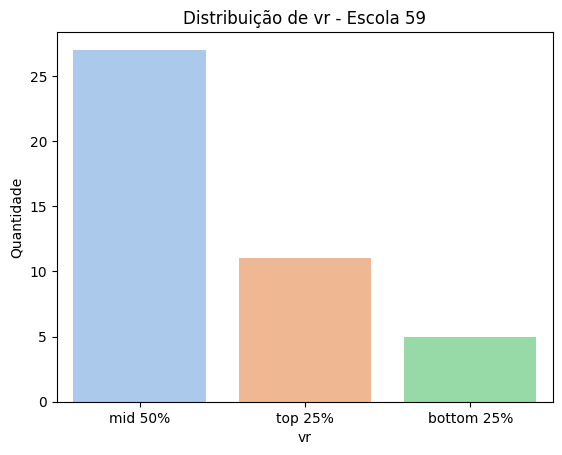

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


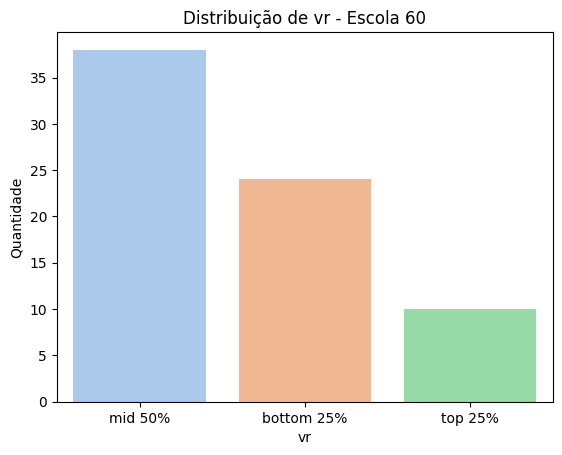

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


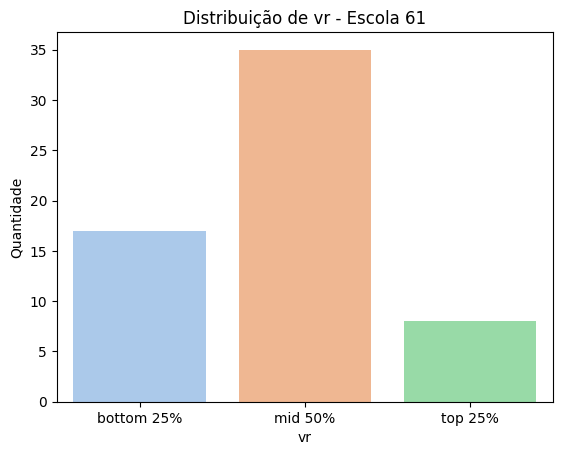

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


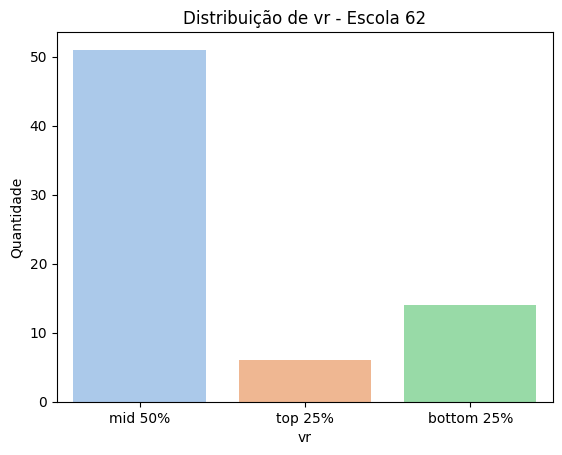

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


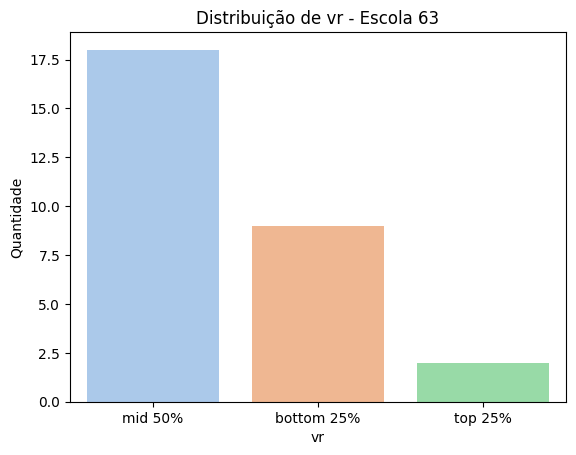

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


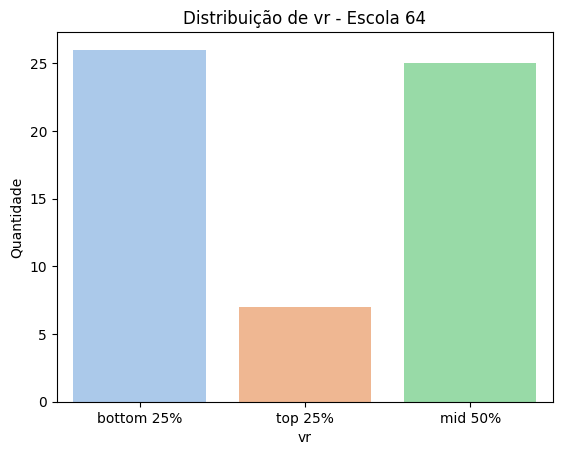

/tmp/ipython-input-2585071352.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(student_school, x='intake', palette='pastel')


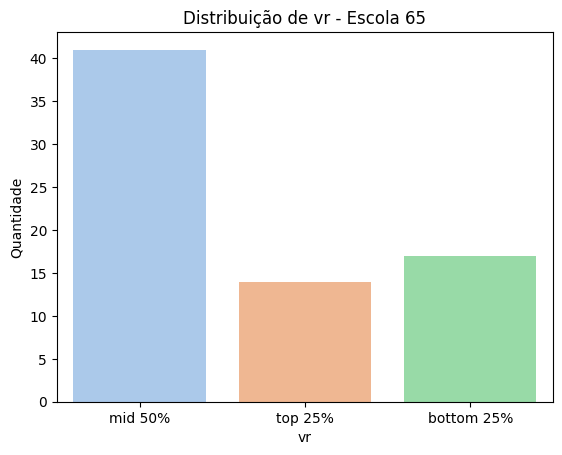

In [ ]:
for school in df_school.index:
  student_school = df_student[df_student['school'] == school]
  sns.countplot(student_school, x='intake', palette='pastel')
  plt.title(f'Distribuição de vr - Escola {school}')
  plt.xlabel('vr')
  plt.ylabel('Quantidade')
  plt.show()

In [ ]:
# Contagem de cada tipo de VR por escola
vr_por_escola = pd.crosstab(df_student['school'], df_student['vr'])

vr_por_escola


vr,bottom 25%,mid 50%,top 25%
school,,,
1,0,69,0
2,0,0,53
3,0,0,50
4,0,78,0
5,0,0,34
...,...,...,...
61,0,60,0
62,0,71,0
63,0,29,0


In [ ]:
# Contagem de cada tipo de VR por escola
vr_por_escola = pd.crosstab(df_student['school'], df_student['intake'])

vr_por_escola



intake,bottom 25%,mid 50%,top 25%
school,,,
1,29,32,9
2,24,25,4
3,27,21,2
4,27,44,7
5,12,22,0
...,...,...,...
61,17,35,8
62,14,51,6
63,9,18,2


In [1]:
vr_prop_por_escola = pd.crosstab(df_student['school'], df_student['intake'], normalize='index')
vr_prop_por_escola


vr_prop_por_escola.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    color=['#66c2a5','#fc8d62','#8da0cb']
)

plt.xlabel('Escola')
plt.ylabel('Proporção de alunos')
plt.title('Distribuição de VR por escola')
plt.legend(title='VR')
plt.tight_layout()
plt.show()


NameError: name 'pd' is not defined